# Réseau Neuronal Analogique — Visualisation v8

Adapté pour les réseaux **1 sortie** entraînés en v8.

**Corrections vs notebook original :**
- `Itot < rheobase` → `Fout = 0 Hz` (neurone silencieux, pas d'extrapolation)
- Decision map : `Fout ≥ seuil → classe 1` (pas d'argmax multi-sortie)
- Confiance : `|Fout − seuil|` en kHz
- Espace d'entrée : `[-1, 1]²` converti en tension via `xy_to_voltage`
- Diagnostic Itot par couche (plage neurone + % silencieux + % saturé)

## 0. Imports

In [48]:
import sys
print(sys.executable)

/home/haittaleb/ENTER/envs/econeuron/bin/python


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11

INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'
FREQ_MERGE_TOL_HZ = 1000.0

## 1. Fonctions de base

In [50]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(f"{csv_path}: colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Ligne '{row_name}' introuvable dans {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def interp2d_bilinear(x, y, x_axis, y_axis, z_grid):
    x = float(np.clip(x, x_axis[0], x_axis[-1]))
    y = float(np.clip(y, y_axis[0], y_axis[-1]))
    ix = int(np.clip(np.searchsorted(x_axis, x) - 1, 0, len(x_axis) - 2))
    iy = int(np.clip(np.searchsorted(y_axis, y) - 1, 0, len(y_axis) - 2))
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[ix,iy]*(1-tx)*(1-ty) + z_grid[ix+1,iy]*tx*(1-ty)
          + z_grid[ix,iy+1]*(1-tx)*ty   + z_grid[ix+1,iy+1]*tx*ty)

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol: groups[-1].append(v)
        else: groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = map(lambda a: np.asarray(a, float), [W_all, F_all, Y_all])
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions de base OK.')

Fonctions de base OK.


## 2. Chargement des modèles Cadence

In [51]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(W2_EXC, FPRE_EXC, IPOST_EXC)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(W2_INH, FPRE_INH, IPOST_INH)

V_MIN = float(INPUT_V_AXIS[0])
V_MAX = float(INPUT_V_AXIS[-1])
NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])
NEURON_I_MAX      = float(NEURON_I_AXIS[-1])
NEURON_F_MAX      = float(NEURON_F_AXIS[-1])

print(f'Input  V : [{V_MIN*1e3:.1f}, {V_MAX*1e3:.1f}] mV')
print(f'Neurone  : [{NEURON_I_AXIS[0]*1e12:.1f}, {NEURON_I_MAX*1e12:.1f}] pA → [{NEURON_F_AXIS[0]/1e3:.1f}, {NEURON_F_MAX/1e3:.1f}] kHz')
print(f'Rheobase : {NEURON_I_RHEOBASE*1e12:.2f} pA')
print(f'EXC W    : {W_EXC_AXIS} um')
print(f'INH W    : {W_INH_AXIS} um')
print('Modèles Cadence chargés.')

Input  V : [-100.0, 100.0] mV
Neurone  : [3.0, 1000.0] pA → [3.1, 193.1] kHz
Rheobase : 3.00 pA
EXC W    : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ] um
INH W    : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ] um
Modèles Cadence chargés.


## 3. Fonctions neurone et synapses

**Correction v8 :** `neuron_f_of_i` retourne `0 Hz` si `Itot < rheobase`  
(le neurone est silencieux — pas d'extrapolation incorrecte)

In [52]:
def input_f_of_v(Vin_V):
    """Tension → fréquence (bloc d'entrée)."""
    return float(interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    """
    Courant → fréquence (neurone interne).
    FIX v8 : si Iin < rheobase → 0 Hz (neurone silencieux).
    Le notebook original utilisait interp_clip qui retournait F[0] ≠ 0.
    """
    Iin_A = float(Iin_A)
    if Iin_A < NEURON_I_RHEOBASE:
        return 0.0
    return float(interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS))

def isyn_exc(Fpre_Hz, Wexc_um):
    return interp2d_bilinear(Wexc_um, Fpre_Hz, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)

def isyn_inh(Fpre_Hz, Winh_um):
    return interp2d_bilinear(Winh_um, Fpre_Hz, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)

# Vérification du fix
print('=== Vérification neuron_f_of_i ===')
print(f'  Itot = -10 pA  → {neuron_f_of_i(-10e-12)/1e3:.2f} kHz  (attendu: 0.00 kHz)')
print(f'  Itot =   0 pA  → {neuron_f_of_i(0)/1e3:.2f} kHz  (attendu: 0.00 kHz)')
print(f'  Itot = rheo    → {neuron_f_of_i(NEURON_I_RHEOBASE)/1e3:.2f} kHz  (attendu: {NEURON_F_AXIS[0]/1e3:.2f} kHz)')
print(f'  Itot = 50 pA   → {neuron_f_of_i(50e-12)/1e3:.2f} kHz')
print(f'  Itot = I_max   → {neuron_f_of_i(NEURON_I_MAX)/1e3:.2f} kHz  (attendu: {NEURON_F_MAX/1e3:.2f} kHz)')

=== Vérification neuron_f_of_i ===
  Itot = -10 pA  → 0.00 kHz  (attendu: 0.00 kHz)
  Itot =   0 pA  → 0.00 kHz  (attendu: 0.00 kHz)
  Itot = rheo    → 3.08 kHz  (attendu: 3.08 kHz)
  Itot = 50 pA   → 40.42 kHz
  Itot = I_max   → 193.10 kHz  (attendu: 193.10 kHz)


## 4. Couche forward

In [53]:
def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """
    Propagation d'une couche.
    Fin_vec_Hz      : (N,)    fréquences pré-synaptiques [Hz]
    sign_matrix     : (N, M)  +1 excitateur, -1 inhibiteur
    width_matrix_um : (N, M)  largeurs synapses [µm]
    Retourne : Fout (M,), Iconn (N,M), Itot (M,)
    """
    N = len(Fin_vec_Hz)
    M = sign_matrix.shape[1]
    Iconn_mat = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            s, w = sign_matrix[i, j], width_matrix_um[i, j]
            if s == 1:
                Iconn_mat[i, j] = float(isyn_exc(Fin_vec_Hz[i], w))
            elif s == -1:
                Iconn_mat[i, j] = -float(isyn_inh(Fin_vec_Hz[i], w))
    Itot = np.sum(Iconn_mat, axis=0)
    # FIX : neuron_f_of_i retourne 0 si Itot < rheobase
    Fout = np.array([neuron_f_of_i(it) for it in Itot])
    return Fout, Iconn_mat, Itot

print('layer_forward OK.')

layer_forward OK.


## 5. Configuration du réseau v8

Colle ici les poids exportés par `weights_cadence_disk_v8.csv`  
et le seuil depuis `threshold_cadence_disk_v8.csv`.

**Architecture v8 :** `[2, N_HIDDEN, 1]` — 1 seule sortie  
**Décision :** `Fout ≥ THRESHOLD_HZ → classe 1 (intérieur)`

In [54]:
# ╔══════════════════════════════════════════════════════════╗
# ║         COLLER LES POIDS ICI (depuis v8)                ║
# ╚══════════════════════════════════════════════════════════╝

# Option A : charger depuis CSV exporté par v8
LOAD_FROM_CSV = True   # mettre False pour entrer les poids manuellement

WEIGHTS_CSV   = 'weights_cadence_disk_v8.csv'
THRESHOLD_CSV = 'threshold_cadence_disk_v8.csv'

if LOAD_FROM_CSV:
    df_w = pd.read_csv(WEIGHTS_CSV)
    df_t = pd.read_csv(THRESHOLD_CSV)
    THRESHOLD_HZ = float(df_t['threshold_Hz'].iloc[0])

    # Reconstruire signs et widths par couche
    layers_config = []
    for li in sorted(df_w['layer'].unique()):
        sub = df_w[df_w['layer'] == li]
        n_in  = sub['pre'].max()  + 1
        n_out = sub['post'].max() + 1
        signs  = np.zeros((n_in, n_out), dtype=int)
        widths = np.zeros((n_in, n_out))
        for _, row in sub.iterrows():
            signs [int(row['pre']), int(row['post'])] = int(row['sign'])
            widths[int(row['pre']), int(row['post'])] = float(row['width_um'])
        layers_config.append({'signs': signs, 'widths': widths})

    layer_sizes = [2] + [cfg['signs'].shape[1] for cfg in layers_config]
    print(f'Chargé depuis CSV : architecture={layer_sizes}')
    print(f'Seuil de décision : {THRESHOLD_HZ/1e3:.3f} kHz')
    if 'bal_acc_train' in df_t.columns:
        print(f'bal_acc train={df_t["bal_acc_train"].iloc[0]:.4f}  '
              f'test={df_t["bal_acc_test"].iloc[0]:.4f}')

else:
    # ── Option B : poids manuels ─────────────────────────────
    # Remplacer par les matrices issues de v8
    layer_sizes = [2, 8, 1]
    THRESHOLD_HZ = 50000.0   # seuil en Hz — à ajuster

    layers_config = [
        {
            'signs':  np.array([[ 1, -1, 1, -1,  1, -1, 1, -1],
                                [-1,  1, 1,  1, -1,  1, 1,  1]]),
            'widths': np.array([[0.135, 0.271, 0.135, 0.271, 0.135, 0.271, 0.135, 0.271],
                                [0.271, 0.135, 0.271, 0.135, 0.271, 0.135, 0.271, 0.135]]),
        },
        {
            'signs':  np.array([[-1], [1], [-1], [1], [-1], [1], [-1], [1]]),
            'widths': np.array([[0.271], [0.135], [0.271], [0.135],
                                [0.271], [0.135], [0.271], [0.135]]),
        },
    ]
    print(f'Poids manuels — architecture={layer_sizes}')
    print(f'Seuil : {THRESHOLD_HZ/1e3:.3f} kHz')

# Point test courant (en coordonnées [-1,1])
XY_TEST = np.array([0, 0])   # (x1, x2) — centre du disque
Vin_test = V_MIN + (XY_TEST + 1.0) * (V_MAX - V_MIN) / 2.0

print(f'Point test : xy={XY_TEST}  →  Vin={Vin_test*1e3} mV')

Chargé depuis CSV : architecture=[2, 5, 1]
Seuil de décision : 26.688 kHz
bal_acc train=0.9821  test=0.9969
Point test : xy=[0 0]  →  Vin=[0. 0.] mV


## 6. Propagation + résumé

In [55]:
def propagate(Vin_V, layers_config):
    """Forward complet. Retourne (history_F, history_Iconn, history_Itot)."""
    F = np.array([input_f_of_v(v) for v in Vin_V])
    history_F     = [F.copy()]
    history_Iconn = []
    history_Itot  = []
    for cfg in layers_config:
        F, Ic, It = layer_forward(F,
                                   np.asarray(cfg['signs'],  int),
                                   np.asarray(cfg['widths'], float))
        history_F.append(F.copy())
        history_Iconn.append(Ic)
        history_Itot.append(It)
    return history_F, history_Iconn, history_Itot

# Propagation du point test
history_F, history_Iconn, history_Itot = propagate(Vin_test, layers_config)

Fout_final = float(history_F[-1][0])   # 1 seule sortie scalaire
classe_pred = 1 if Fout_final >= THRESHOLD_HZ else 0
vrai_label  = 1 if (XY_TEST[0]**2 + XY_TEST[1]**2) < 0.25 else 0

print('=' * 55)
print(f'  Réseau : {layer_sizes}')
print(f'  Point  : xy={XY_TEST}  (r={np.sqrt(XY_TEST[0]**2+XY_TEST[1]**2):.3f})')
print(f'  Vin    : {Vin_test*1e3} mV')
print(f'  Fin    : {history_F[0]*1e-3} kHz')
print('=' * 55)
for k in range(len(layers_config)):
    print(f'  Couche {k}→{k+1} :')
    print(f'    Itot (pA) = {history_Itot[k]*1e12}')
    print(f'    Fout (kHz)= {history_F[k+1]*1e-3}')
print('=' * 55)
print(f'  Fout finale  = {Fout_final/1e3:.3f} kHz')
print(f'  Seuil        = {THRESHOLD_HZ/1e3:.3f} kHz')
print(f'  Marge        = {(Fout_final - THRESHOLD_HZ)/1e3:+.3f} kHz')
print(f'  Classe prédite = {classe_pred}  ({"intérieur" if classe_pred==1 else "extérieur"})')
print(f'  Vrai label     = {vrai_label}   ({"intérieur" if vrai_label==1 else "extérieur"})')
print(f'  {"✓ CORRECT" if classe_pred==vrai_label else "✗ ERREUR"}')
print('=' * 55)

  Réseau : [2, 5, 1]
  Point  : xy=[0 0]  (r=0.000)
  Vin    : [0. 0.] mV
  Fin    : [10.0135 10.0135] kHz
  Couche 0→1 :
    Itot (pA) = [135.34108187 246.82937606 182.62160732  96.32645524 242.11884286]
    Fout (kHz)= [ 78.07638357 109.50047218  93.12043836  63.28125597 108.45060092]
  Couche 1→2 :
    Itot (pA) = [29.20764868]
    Fout (kHz)= [27.20035634]
  Fout finale  = 27.200 kHz
  Seuil        = 26.688 kHz
  Marge        = +0.512 kHz
  Classe prédite = 1  (intérieur)
  Vrai label     = 1   (intérieur)
  ✓ CORRECT


## 7. Visualisation couche par couche

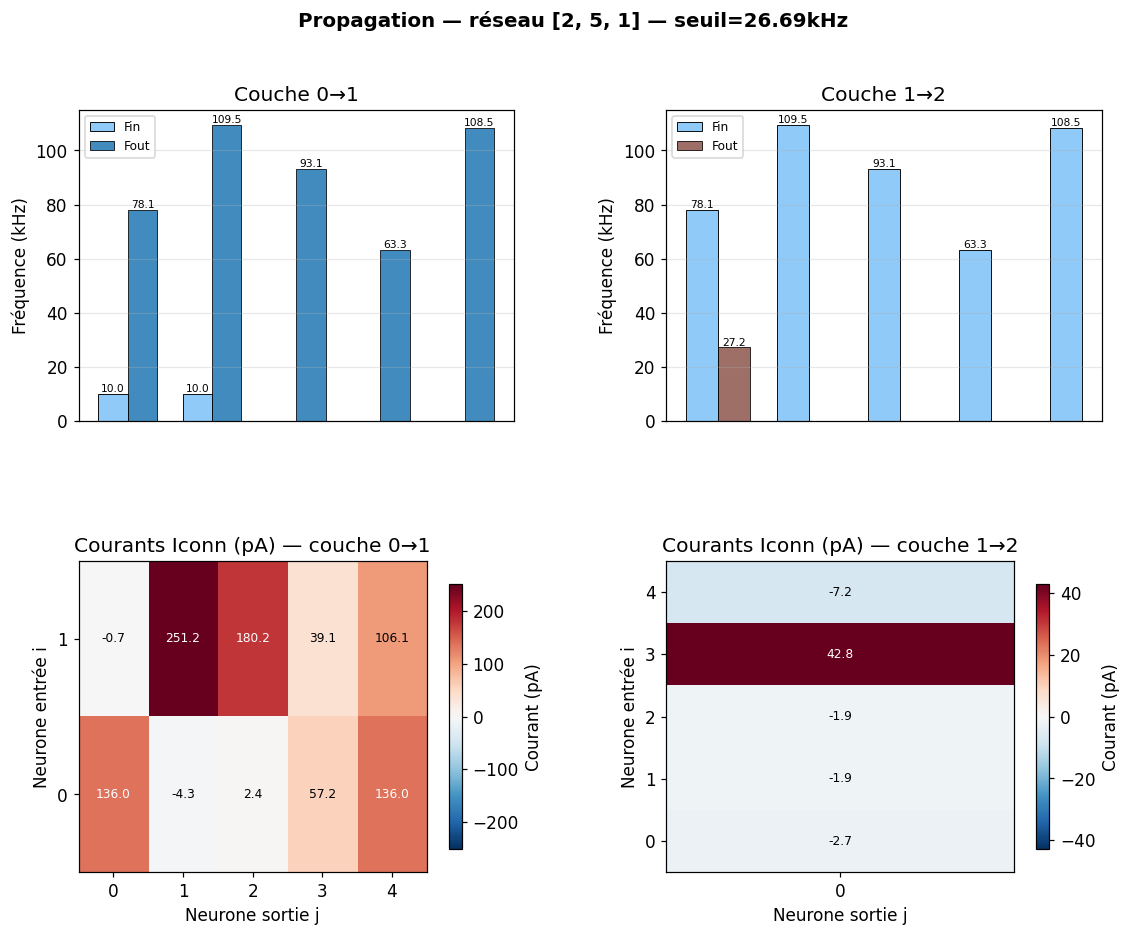

In [56]:
n_conn = len(layers_config)
fig = plt.figure(figsize=(5 * n_conn + 2, 9))
fig.suptitle(f'Propagation — réseau {layer_sizes} — seuil={THRESHOLD_HZ/1e3:.2f}kHz',
             fontsize=13, fontweight='bold')
gs = gridspec.GridSpec(2, n_conn, figure=fig, hspace=0.45, wspace=0.35)
colors = plt.cm.tab10(np.linspace(0, 0.5, n_conn))

for k in range(n_conn):
    Fin_k  = history_F[k]
    Fout_k = history_F[k + 1]
    Iconn  = history_Iconn[k]
    Itot   = history_Itot[k]
    N, M   = Iconn.shape
    color  = colors[k]

    # ── Haut : fréquences ──────────────────────────────────
    ax = fig.add_subplot(gs[0, k])
    x_in  = np.arange(N); x_out = np.arange(M); w = 0.35
    b1 = ax.bar(x_in  - w/2, Fin_k  * 1e-3, w, label='Fin',  color='#90CAF9', edgecolor='k', linewidth=0.6)
    b2 = ax.bar(x_out + w/2, Fout_k * 1e-3, w, label='Fout', color=color,     edgecolor='k', linewidth=0.6, alpha=0.85)
    # Marquer les neurones silencieux
    for j, (bar, f) in enumerate(zip(b2, Fout_k)):
        if f == 0:
            ax.text(bar.get_x()+bar.get_width()/2, 0.5, 'silent',
                    ha='center', va='bottom', fontsize=7, color='red', rotation=90)
    ax.set_title(f'Couche {k}→{k+1}')
    ax.set_ylabel('Fréquence (kHz)')
    ax.set_xticks([]); ax.legend(fontsize=8); ax.grid(True, axis='y', alpha=0.3)
    for bar, val in zip(b1, Fin_k*1e-3):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{val:.1f}',
                ha='center', va='bottom', fontsize=7)
    for bar, val in zip(b2, Fout_k*1e-3):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{val:.1f}',
                ha='center', va='bottom', fontsize=7)

    # ── Bas : matrice Iconn ────────────────────────────────
    ax = fig.add_subplot(gs[1, k])
    vmax = max(np.max(np.abs(Iconn)) * 1e12, 1e-3)
    im = ax.imshow(Iconn * 1e12, aspect='auto', origin='lower',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label='Courant (pA)', shrink=0.85)
    ax.set_xlabel('Neurone sortie j')
    ax.set_ylabel('Neurone entrée i')
    ax.set_title(f'Courants Iconn (pA) — couche {k}→{k+1}')
    ax.set_xticks(range(M)); ax.set_yticks(range(N))
    for i in range(N):
        for j in range(M):
            ax.text(j, i, f'{Iconn[i,j]*1e12:.1f}', ha='center', va='center',
                    fontsize=8, color='white' if abs(Iconn[i,j]*1e12) > vmax*0.5 else 'black')

plt.show()

## 8. Diagnostic Itot par couche

In [57]:
print('=' * 60)
print(f'  DIAGNOSTIC Itot — plage neurone [{NEURON_I_RHEOBASE*1e12:.1f}, {NEURON_I_MAX*1e12:.1f}] pA')
print('=' * 60)
for k, Itot in enumerate(history_Itot):
    for j, it in enumerate(Itot):
        if it < NEURON_I_RHEOBASE:
            statut = '→ SILENCIEUX (0 Hz)' if it >= 0 else f'→ NÉGATIF ({it*1e12:.1f} pA) SILENCIEUX'
        elif it > NEURON_I_MAX:
            statut = '→ SATURÉ (Fmax)'
        else:
            statut = '→ OK'
        print(f'  Couche {k}→{k+1}, neurone {j} : Itot={it*1e12:8.2f} pA  {statut}')
print('=' * 60)
print(f'  Fout finale = {history_F[-1][0]/1e3:.3f} kHz')
print(f'  Seuil       = {THRESHOLD_HZ/1e3:.3f} kHz')
print(f'  Décision    : Fout {"≥" if history_F[-1][0] >= THRESHOLD_HZ else "<"} seuil → classe {1 if history_F[-1][0] >= THRESHOLD_HZ else 0}')
print('=' * 60)

  DIAGNOSTIC Itot — plage neurone [3.0, 1000.0] pA
  Couche 0→1, neurone 0 : Itot=  135.34 pA  → OK
  Couche 0→1, neurone 1 : Itot=  246.83 pA  → OK
  Couche 0→1, neurone 2 : Itot=  182.62 pA  → OK
  Couche 0→1, neurone 3 : Itot=   96.33 pA  → OK
  Couche 0→1, neurone 4 : Itot=  242.12 pA  → OK
  Couche 1→2, neurone 0 : Itot=   29.21 pA  → OK
  Fout finale = 27.200 kHz
  Seuil       = 26.688 kHz
  Décision    : Fout ≥ seuil → classe 1


## 9. Courbes de caractéristiques

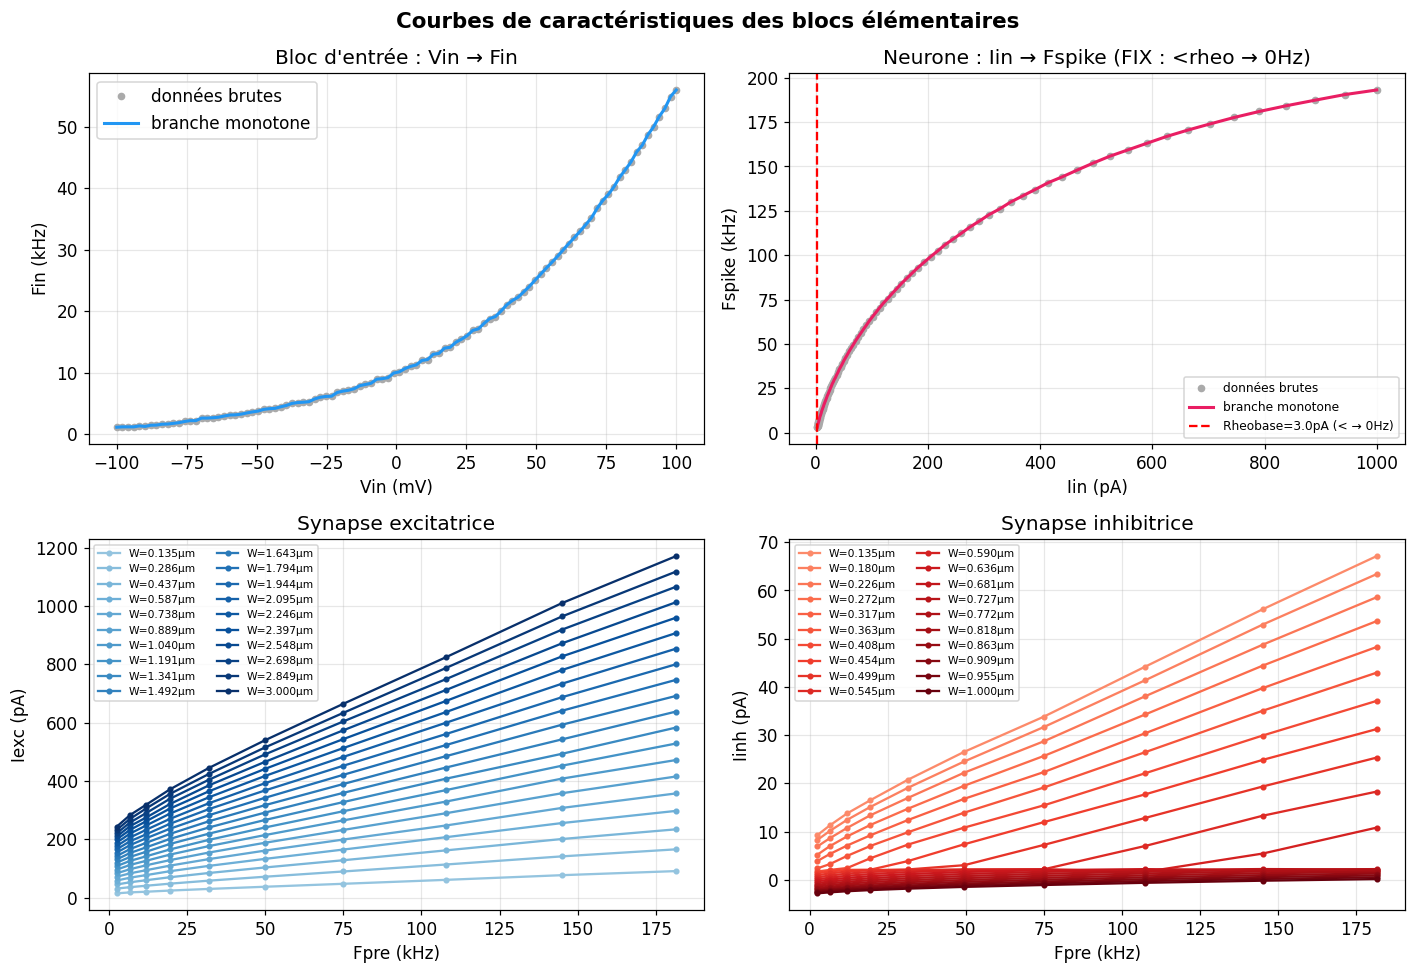

In [58]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Courbes de caractéristiques des blocs élémentaires', fontsize=14, fontweight='bold')

ax = axs[0, 0]
ax.plot(VEX_IN*1e3, FSPIKES_IN*1e-3, 'o', color='#aaa', ms=4, label='données brutes')
ax.plot(INPUT_V_AXIS*1e3, INPUT_F_AXIS*1e-3, '-', color='#2196F3', lw=2, label='branche monotone')
ax.set_xlabel('Vin (mV)'); ax.set_ylabel('Fin (kHz)')
ax.set_title("Bloc d'entrée : Vin → Fin")
ax.grid(True, alpha=0.3); ax.legend()

ax = axs[0, 1]
ax.plot(IEX_NEURO*1e12, FSPIKES_NEURO*1e-3, 'o', color='#aaa', ms=4, label='données brutes')
ax.plot(NEURON_I_AXIS*1e12, NEURON_F_AXIS*1e-3, '-', color='#E91E63', lw=2, label='branche monotone')
ax.axvline(NEURON_I_RHEOBASE*1e12, color='red', ls='--', lw=1.5,
           label=f'Rheobase={NEURON_I_RHEOBASE*1e12:.1f}pA (< → 0Hz)')
ax.set_xlabel('Iin (pA)'); ax.set_ylabel('Fspike (kHz)')
ax.set_title('Neurone : Iin → Fspike (FIX : <rheo → 0Hz)')
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

ax = axs[1, 0]
cmap_exc = plt.cm.Blues(np.linspace(0.4, 1.0, len(W_EXC_AXIS)))
for i, w in enumerate(W_EXC_AXIS):
    ax.plot(F_EXC_AXIS*1e-3, IPOST_EXC_GRID[i]*1e12, 'o-',
            color=cmap_exc[i], lw=1.5, ms=3, label=f'W={w:.3f}µm')
ax.set_xlabel('Fpre (kHz)'); ax.set_ylabel('Iexc (pA)')
ax.set_title('Synapse excitatrice')
ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)

ax = axs[1, 1]
cmap_inh = plt.cm.Reds(np.linspace(0.4, 1.0, len(W_INH_AXIS)))
for i, w in enumerate(W_INH_AXIS):
    ax.plot(F_INH_AXIS*1e-3, IPOST_INH_GRID[i]*1e12, 'o-',
            color=cmap_inh[i], lw=1.5, ms=3, label=f'W={w:.3f}µm')
ax.set_xlabel('Fpre (kHz)'); ax.set_ylabel('Iinh (pA)')
ax.set_title('Synapse inhibitrice')
ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)

plt.tight_layout(); plt.show()

## 10. Decision Map — espace [-1,1]²

**v8 :** décision par seuil sur la fréquence de sortie unique  
`Fout ≥ THRESHOLD_HZ → classe 1 (intérieur)`  
Confiance = `|Fout − seuil|` en kHz

Calcul decision map (50×50 = 2500 points)...
Terminé.


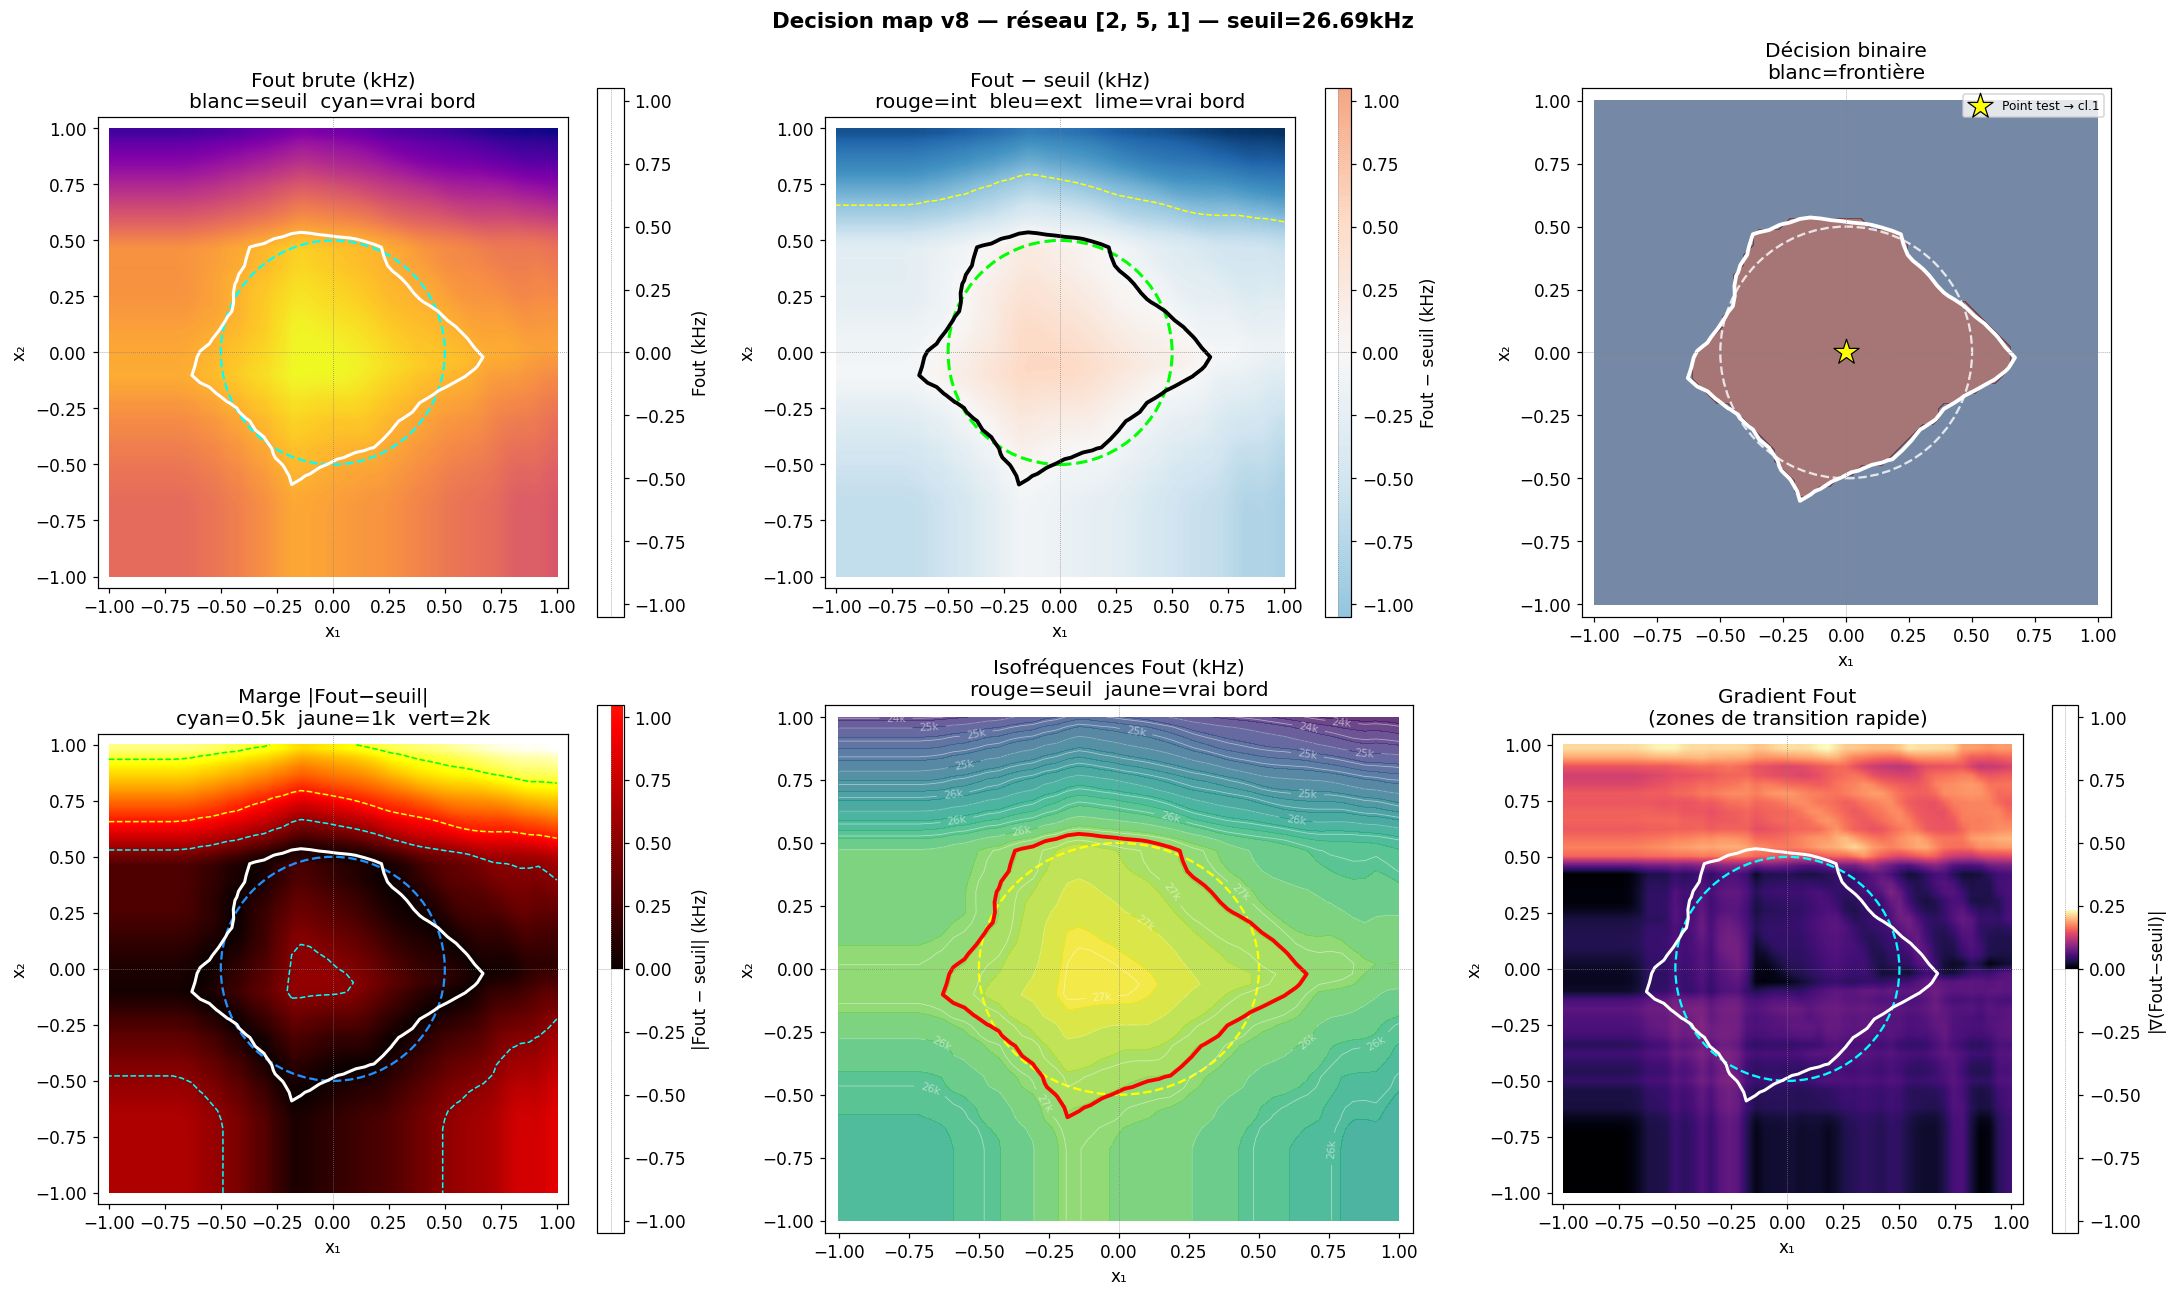


Surface prédite intérieur : 20.4%  (attendu ~19.6%)
Fout min=24.04kHz  max=27.24kHz  range=3.20kHz


In [59]:
N_GRID = 50   # résolution (augmenter pour plus de détails, mais plus lent)

x1_axis = np.linspace(-1, 1, N_GRID)
x2_axis = np.linspace(-1, 1, N_GRID)

fout_grid  = np.zeros((N_GRID, N_GRID))   # fréquence de sortie
class_grid = np.zeros((N_GRID, N_GRID), dtype=int)
conf_grid  = np.zeros((N_GRID, N_GRID))   # |Fout - seuil|
diff_grid  = np.zeros((N_GRID, N_GRID))   # Fout - seuil (signé)

print(f'Calcul decision map ({N_GRID}×{N_GRID} = {N_GRID**2} points)...')
for ii, x1 in enumerate(x1_axis):
    for jj, x2 in enumerate(x2_axis):
        Vin_loc = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        F_loc   = np.array([input_f_of_v(v) for v in Vin_loc])
        for cfg in layers_config:
            F_loc, _, _ = layer_forward(F_loc,
                                         np.asarray(cfg['signs'],  int),
                                         np.asarray(cfg['widths'], float))
        fout   = float(F_loc[0])
        fout_grid [ii, jj] = fout
        class_grid[ii, jj] = 1 if fout >= THRESHOLD_HZ else 0
        diff_grid [ii, jj] = (fout - THRESHOLD_HZ) / 1e3   # kHz signé
        conf_grid [ii, jj] = abs(fout - THRESHOLD_HZ) / 1e3  # kHz absolu

print('Terminé.')

# ── Visualisation 6 cartes ────────────────────────────────────
vmax_diff = float(max(abs(diff_grid.min()), abs(diff_grid.max())))
norm_div  = TwoSlopeNorm(vmin=-vmax_diff, vcenter=0, vmax=vmax_diff)
DISK_RADIUS = 0.5

fig = plt.figure(figsize=(20, 12))
fig.suptitle(f'Decision map v8 — réseau {layer_sizes} — seuil={THRESHOLD_HZ/1e3:.2f}kHz',
             fontsize=14, fontweight='bold')

ext = [-1, 1, -1, 1]  # extent pour imshow

# ── 1. Fout brute ─────────────────────────────────────────────
ax = fig.add_subplot(2, 3, 1)
im = ax.imshow(fout_grid.T/1e3, origin='lower', extent=ext,
               aspect='equal', cmap='plasma', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout (kHz)')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='cyan', fill=False, lw=1.5, ls='--'))
ax.set_title('Fout brute (kHz)\nblanc=seuil  cyan=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 2. Fout − seuil (divergente) ──────────────────────────────
ax = fig.add_subplot(2, 3, 2)
im = ax.imshow(diff_grid.T, origin='lower', extent=ext,
               aspect='equal', cmap='RdBu_r', norm=norm_div, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout − seuil (kHz)')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='black', linewidths=2.5)
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[-1, 1], colors='yellow',
           linewidths=1, linestyles='--')
ax.add_patch(Circle((0,0), DISK_RADIUS, color='lime', fill=False, lw=2, ls='--'))
ax.set_title('Fout − seuil (kHz)\nrouge=int  bleu=ext  lime=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 3. Décision binaire ───────────────────────────────────────
ax = fig.add_subplot(2, 3, 3)
ax.contourf(x1_axis, x2_axis, class_grid.T,
            levels=[-0.5, 0.5, 1.5], colors=['#1a3a6b', '#6b1a1a'], alpha=0.6)
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2.5)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='white', fill=False, lw=1.5, ls='--', alpha=0.8))
ax.scatter(*XY_TEST, marker='*', s=300, color='yellow', edgecolors='black',
           linewidths=0.8, zorder=5, label=f'Point test → cl.{classe_pred}')
ax.legend(fontsize=8, loc='upper right')
ax.set_title(f'Décision binaire\nblanc=frontière')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂'); ax.set_aspect('equal')

# ── 4. Marge |Fout − seuil| ───────────────────────────────────
ax = fig.add_subplot(2, 3, 4)
im = ax.imshow(conf_grid.T, origin='lower', extent=ext,
               aspect='equal', cmap='hot', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='|Fout − seuil| (kHz)')
ax.contour(x1_axis, x2_axis, conf_grid.T, levels=[0.5, 1.0, 2.0],
           colors=['cyan', 'yellow', 'lime'], linewidths=1, linestyles='--')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='dodgerblue', fill=False, lw=1.5, ls='--'))
ax.set_title('Marge |Fout−seuil|\ncyan=0.5k  jaune=1k  vert=2k')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 5. Isofréquences ──────────────────────────────────────────
ax = fig.add_subplot(2, 3, 5)
ax.contourf(x1_axis, x2_axis, fout_grid.T/1e3, levels=30, cmap='viridis', alpha=0.8)
cs = ax.contour(x1_axis, x2_axis, fout_grid.T/1e3, levels=15,
                colors='white', linewidths=0.5, alpha=0.5)
ax.clabel(cs, inline=True, fontsize=7, fmt='%.0fk')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='red', linewidths=2.5)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='yellow', fill=False, lw=1.5, ls='--'))
ax.set_title('Isofréquences Fout (kHz)\nrouge=seuil  jaune=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 6. Gradient (zones de transition rapide) ──────────────────
ax = fig.add_subplot(2, 3, 6)
dy, dx = np.gradient(diff_grid.T)
grad   = np.sqrt(dx**2 + dy**2)
im = ax.imshow(grad, origin='lower', extent=ext,
               aspect='equal', cmap='magma', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='|∇(Fout−seuil)|')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='cyan', fill=False, lw=1.5, ls='--'))
ax.set_title('Gradient Fout\n(zones de transition rapide)')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

for ax in fig.axes:
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.axvline(0, color='gray', lw=0.5, ls=':')

plt.tight_layout(); plt.show()

# Résumé
pct_int = 100 * class_grid.sum() / N_GRID**2
print(f'\nSurface prédite intérieur : {pct_int:.1f}%  (attendu ~{np.pi*DISK_RADIUS**2/4*100:.1f}%)')
print(f'Fout min={fout_grid.min()/1e3:.2f}kHz  max={fout_grid.max()/1e3:.2f}kHz  range={( fout_grid.max()-fout_grid.min())/1e3:.2f}kHz')

## 11. Tester plusieurs points

Cellule pratique pour tester des points spécifiques.

Calcul 50×50 points...
Terminé.


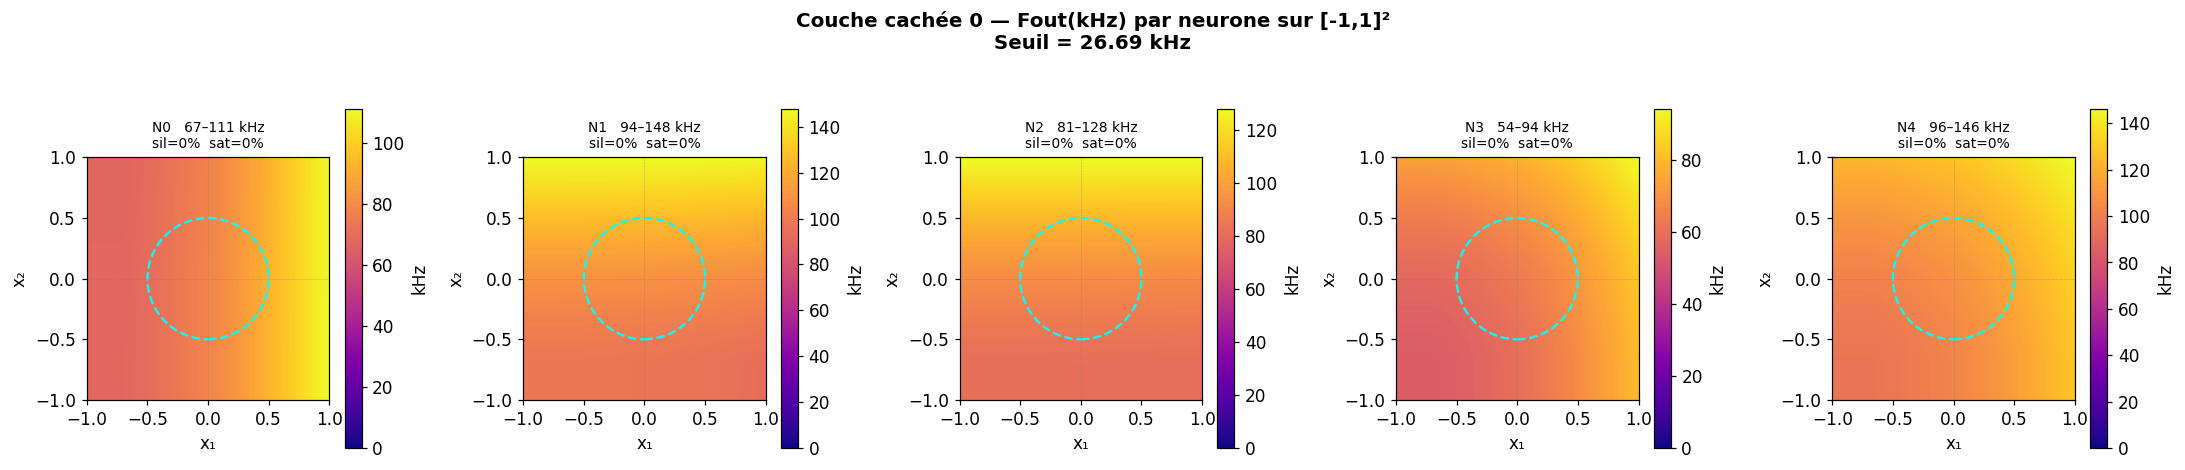

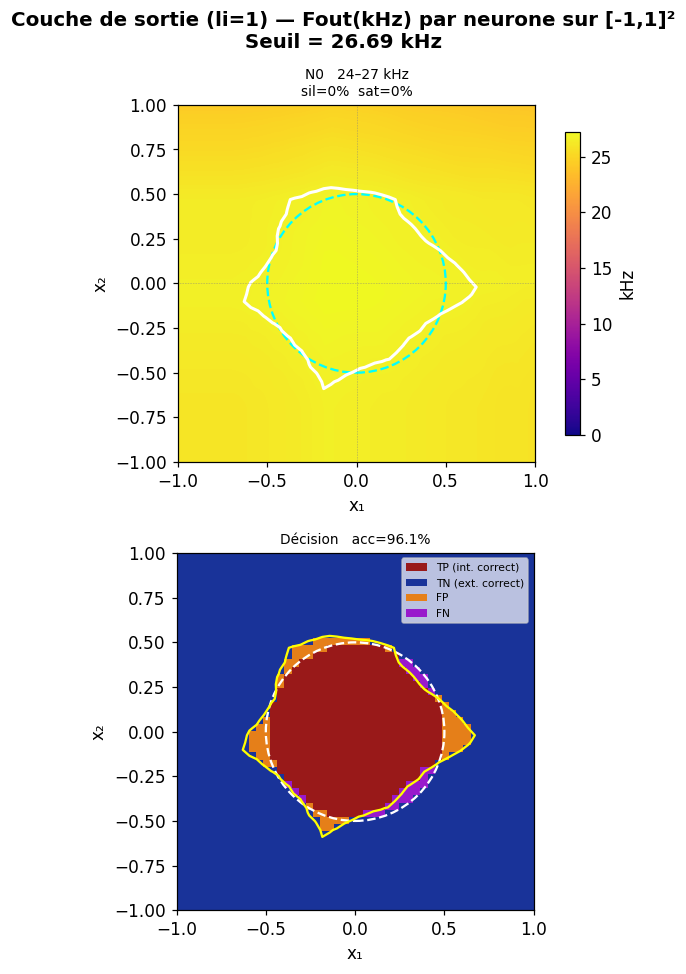

In [60]:
## 12. Decision maps par neurone — espace [-1,1]²

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Circle

N_GRID = 50  # résolution (50 = rapide, 100 = précis)

x1_axis = np.linspace(-1, 1, N_GRID)
x2_axis = np.linspace(-1, 1, N_GRID)

# ── Calcul des grilles par couche et par neurone ──────────────
# histo_grids[li][j] = grille (N_GRID, N_GRID) de Fout du neurone j, couche li
n_layers = len(layers_config)
histo_grids = []
for li, cfg in enumerate(layers_config):
    M = cfg['signs'].shape[1]
    grids = [np.zeros((N_GRID, N_GRID)) for _ in range(M)]
    histo_grids.append(grids)

print(f'Calcul {N_GRID}×{N_GRID} points...')
for ii, x1 in enumerate(x1_axis):
    for jj, x2 in enumerate(x2_axis):
        Vin_loc = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hF, _, _ = propagate(Vin_loc, layers_config)
        for li in range(n_layers):
            for j, fval in enumerate(hF[li + 1]):
                histo_grids[li][j][ii, jj] = fval / 1e3  # en kHz
print('Terminé.')

DISK_RADIUS = 0.5
ext = [-1, 1, -1, 1]

# ── Affichage par couche ──────────────────────────────────────
for li in range(n_layers):
    M = len(histo_grids[li])
    is_output = (li == n_layers - 1)
    
    # Nombre de lignes : 1 ligne fréquence + 1 ligne décision si couche de sortie
    n_rows = 2 if is_output else 1
    fig, axes = plt.subplots(n_rows, M,
                              figsize=(max(4 * M, 6), 4.5 * n_rows),
                              squeeze=False)
    
    layer_label = f'Couche de sortie (li={li})' if is_output else f'Couche cachée {li}'
    fig.suptitle(f'{layer_label} — Fout(kHz) par neurone sur [-1,1]²\n'
                 f'Seuil = {THRESHOLD_HZ/1e3:.2f} kHz',
                 fontsize=13, fontweight='bold')

    for j in range(M):
        grid = histo_grids[li][j]

        # ── Ligne 0 : heatmap fréquence ──────────────────────
        ax = axes[0, j]
        vmax = max(grid.max(), 0.01)
        im = ax.imshow(grid.T, origin='lower', extent=ext,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)

        # Contour seuil (couche de sortie uniquement)
        if is_output:
            ax.contour(x1_axis, x2_axis, (grid - THRESHOLD_HZ/1e3).T,
                       levels=[0], colors='white', linewidths=2)

        # Vrai bord du disque
        ax.add_patch(Circle((0, 0), DISK_RADIUS,
                             color='cyan', fill=False, lw=1.5, ls='--'))

        # Stats
        silent_pct = np.sum(grid == 0) / grid.size * 100
        sat_pct    = np.sum(grid * 1e3 >= NEURON_F_MAX * 0.99) / grid.size * 100
        ax.set_title(f'N{j}   {grid.min():.0f}–{grid.max():.0f} kHz\n'
                     f'sil={silent_pct:.0f}%  sat={sat_pct:.0f}%', fontsize=9)
        ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
        ax.axhline(0, color='gray', lw=0.4, ls=':')
        ax.axvline(0, color='gray', lw=0.4, ls=':')

        # ── Ligne 1 (sortie seulement) : carte de décision ───
        if is_output:
            ax2 = axes[1, j]
            pred_grid = (grid >= THRESHOLD_HZ / 1e3).astype(int)

            X1, X2 = np.meshgrid(x1_axis, x2_axis, indexing='ij')
            true_grid = ((X1**2 + X2**2) < DISK_RADIUS**2).astype(int)

            # Couleurs : vert=correct, rouge=erreur
            correct   = (pred_grid == true_grid)
            rgb = np.zeros((*grid.shape, 3))
            # intérieur prédit correct (TP) → rouge foncé
            rgb[( pred_grid==1) & correct]  = [0.6, 0.1, 0.1]
            # extérieur prédit correct (TN) → bleu foncé
            rgb[( pred_grid==0) & correct]  = [0.1, 0.2, 0.6]
            # FP (prédit int, vrai ext)     → orange
            rgb[( pred_grid==1) & ~correct] = [0.9, 0.5, 0.1]
            # FN (prédit ext, vrai int)     → violet
            rgb[( pred_grid==0) & ~correct] = [0.6, 0.1, 0.8]

            ax2.imshow(rgb.transpose(1, 0, 2), origin='lower',
                       extent=ext, aspect='equal', interpolation='nearest')
            ax2.add_patch(Circle((0, 0), DISK_RADIUS,
                                  color='white', fill=False, lw=1.5, ls='--'))
            ax2.contour(x1_axis, x2_axis, (grid - THRESHOLD_HZ/1e3).T,
                        levels=[0], colors='yellow', linewidths=1.5)

            acc = correct.mean() * 100
            ax2.set_title(f'Décision   acc={acc:.1f}%', fontsize=9)
            ax2.set_xlabel('x₁'); ax2.set_ylabel('x₂')

            from matplotlib.patches import Patch
            legend_els = [
                Patch(facecolor=[0.6,0.1,0.1], label='TP (int. correct)'),
                Patch(facecolor=[0.1,0.2,0.6], label='TN (ext. correct)'),
                Patch(facecolor=[0.9,0.5,0.1], label='FP'),
                Patch(facecolor=[0.6,0.1,0.8], label='FN'),
            ]
            ax2.legend(handles=legend_els, fontsize=7,
                       loc='upper right', framealpha=0.7)

    plt.tight_layout()
    plt.show()
    print()

Architecture détectée : [2, 5, 1]
Mesures Cadence : (25, 5)
Indices sélectionnés : [0, 1, 2, 3, 4]
Nombre de points : 25

Propagation hybride [2,5,1]...

Point        Vin1     Vin2        Fmod        Fhyb     Delta F       Décision
C0_0         -100     -100       26.03       13.04      -12.99             OK
C0_1          -50     -100       26.17       10.24      -15.93             OK
C0_2            0     -100       26.53        7.15      -19.38             OK
C0_3           50     -100       26.18        4.27      -21.91             OK
C0_4          100     -100       25.83        0.00      -25.83             OK
C0_5         -100      -50       26.16        9.67      -16.49             OK
C0_6          -50      -50       26.31        8.38      -17.93             OK
C0_7            0      -50       26.66        7.83      -18.83             OK
C0_8           50      -50       26.30        4.22      -22.08             OK
C0_9          100      -50       25.93        0.00      -25.93    

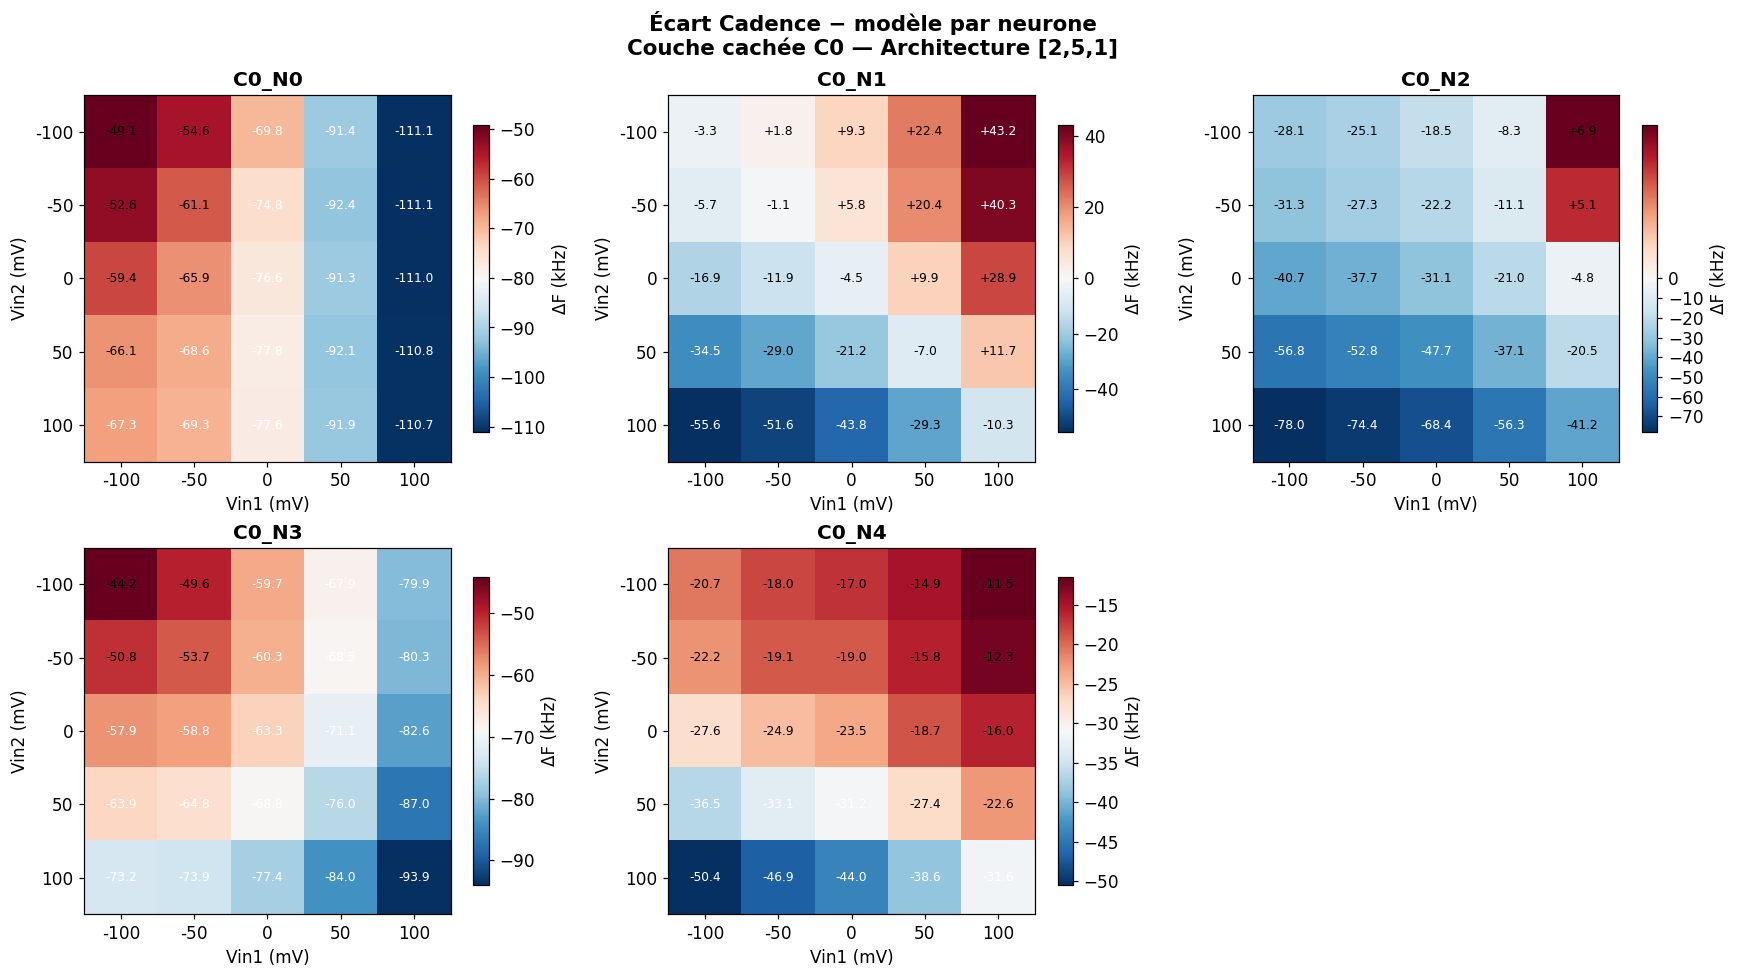

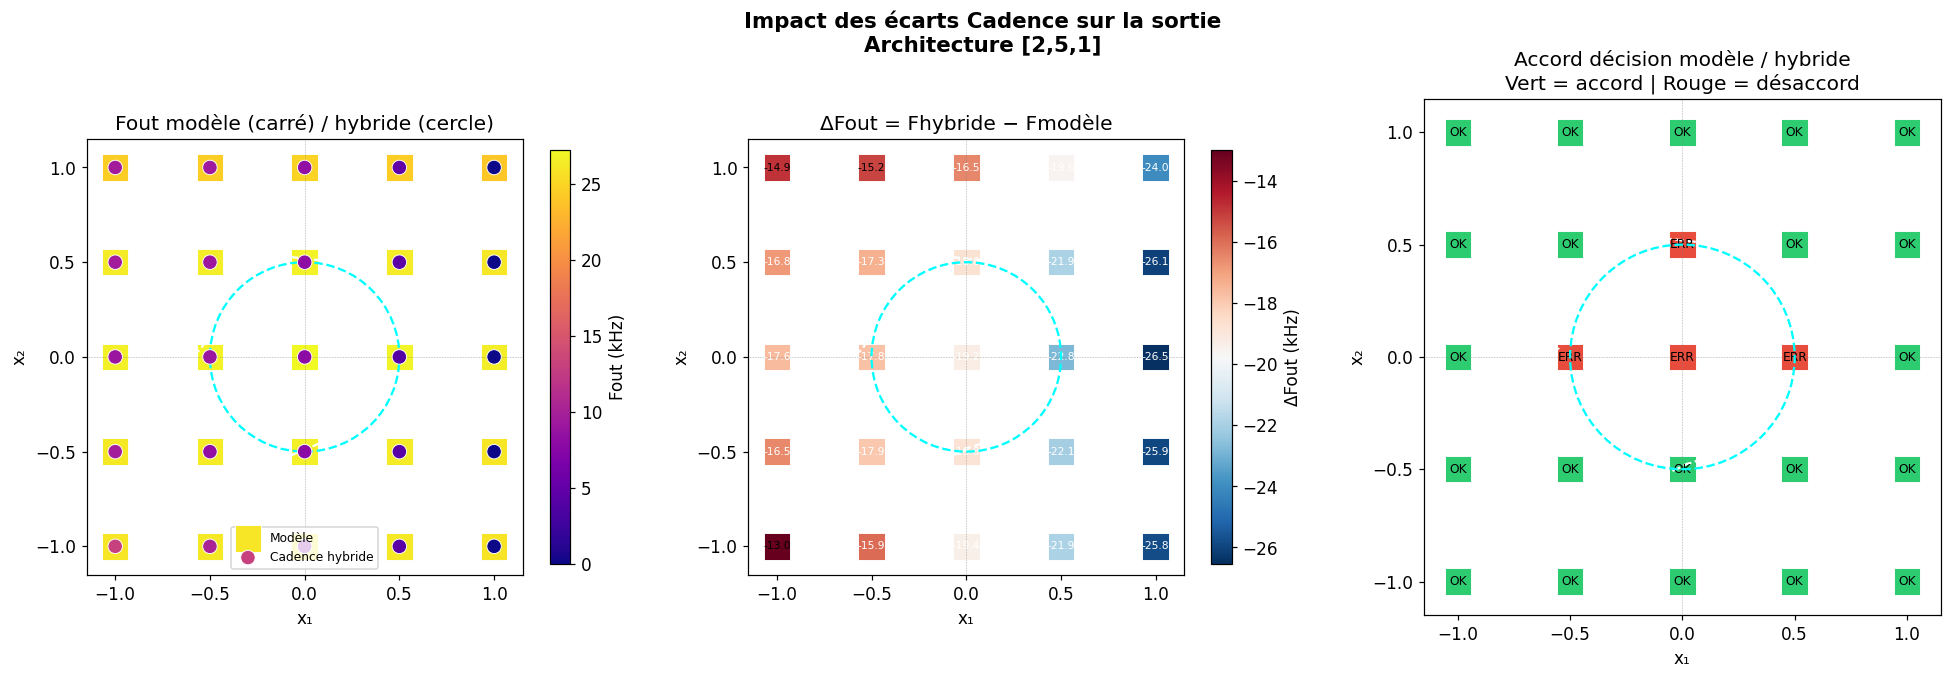


RÉSUMÉ PROPAGATION HYBRIDE [2,5,1]
Nombre de points : 25
MAE              : 19.693 kHz
RMSE             : 20.053 kHz
Désaccords       : 4/25


In [61]:
# ============================================================
# 13. PROPAGATION HYBRIDE CADENCE
# Architecture : [2, 5, 1]
# Grille : 5 × 5
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm


# ============================================================
# 1. VÉRIFICATION DE L'ARCHITECTURE
# ============================================================

N_HIDDEN_LAYERS = len(layers_config) - 1

HIDDEN_SIZES = [
    layers_config[li]['signs'].shape[1]
    for li in range(N_HIDDEN_LAYERS)
]

OUT_SIZE = layers_config[-1]['signs'].shape[1]

print("Architecture détectée :", [2] + HIDDEN_SIZES + [OUT_SIZE])

assert HIDDEN_SIZES == [5], \
    "Architecture attendue : [2, 5, 1]"

assert OUT_SIZE == 1, \
    "Le réseau doit posséder une seule sortie."

assert layers_config[0]['signs'].shape == (2, 5)
assert layers_config[1]['signs'].shape == (5, 1)


# ============================================================
# 2. GRILLE CADENCE
# ============================================================

VIN_GRID = np.array([
    -0.100,
    -0.050,
     0.000,
     0.050,
     0.100
])


def vin_to_xy(vin):

    return 2.0 * (vin - V_MIN) / (V_MAX - V_MIN) - 1.0


# ============================================================
# 3. MESURES CADENCE — COUCHE C0
# ============================================================

# Les mesures ci-dessous sont celles de ton fichier.
# Elles contiennent encore 6 fréquences par point.
#
# Ordre supposé :
# [N0, N1, N2, N3, N4, N5]
#
# Indiquer ici les indices des 5 neurones du nouveau circuit.
# À confirmer avec ton schéma Cadence.

CADENCE_NEURON_INDICES = [0, 1, 2, 3, 4]


C0_0  = [19.0e3, 94.0e3, 53.5e3, 10.0e3, 75.0e3, 26.5e3]
C0_1  = [15.5e3, 99.0e3, 56.5e3, 5.5e3, 79.0e3, 24.5e3]
C0_2  = [8.5e3, 106.0e3, 63.0e3, 0.0, 86.0e3, 20.5e3]
C0_3  = [1.0e3, 118.0e3, 73.0e3, 0.0, 98.5e3, 8.0e3]
C0_4  = [0.0, 137.0e3, 88.0e3, 0.0, 116.5e3, 2.0e3]

C0_5  = [15.5e3, 94.0e3, 52.5e3, 4.0e3, 74.5e3, 25.0e3]
C0_6  = [9.0e3, 98.5e3, 56.5e3, 2.0e3, 79.0e3, 22.5e3]
C0_7  = [3.5e3, 105.0e3, 61.5e3, 0.0, 85.0e3, 18.5e3]
C0_8  = [0.0, 118.5e3, 72.5e3, 0.0, 98.5e3, 3.5e3]
C0_9  = [0.0, 136.5e3, 88.5e3, 0.0, 116.5e3, 1.5e3]

C0_10 = [8.5e3, 93.0e3, 52.5e3, 0.0, 74.0e3, 21.0e3]
C0_11 = [4.0e3, 98.0e3, 55.5e3, 0.0, 78.0e3, 19.0e3]
C0_12 = [1.5e3, 105.0e3, 62.0e3, 0.0, 85.0e3, 12.5e3]
C0_13 = [1.0e3, 118.5e3, 72.0e3, 0.0, 99.5e3, 3.0e3]
C0_14 = [0.0, 136.0e3, 88.0e3, 0.0, 116.0e3, 0.0]

C0_15 = [1.5e3, 92.0e3, 51.5e3, 0.0, 73.5e3, 7.5e3]
C0_16 = [1.0e3, 97.5e3, 55.5e3, 0.0, 78.0e3, 3.5e3]
C0_17 = [0.0, 105.0e3, 60.5e3, 0.0, 85.0e3, 3.0e3]
C0_18 = [0.0, 118.5e3, 71.0e3, 0.0, 97.5e3, 1.5e3]
C0_19 = [0.0, 136.0e3, 87.5e3, 0.0, 115.0e3, 1.5e3]

C0_20 = [0.0, 92.0e3, 50.0e3, 0.0, 72.0e3, 1.5e3]
C0_21 = [0.0, 96.0e3, 53.5e3, 0.0, 76.5e3, 1.0e3]
C0_22 = [0.0, 103.5e3, 59.5e3, 0.0, 83.5e3, 1.5e3]
C0_23 = [0.0, 117.5e3, 71.5e3, 0.0, 96.5e3, 1.0e3]
C0_24 = [0.0, 135.5e3, 86.5e3, 0.0, 114.5e3, 1.0e3]


CADENCE_RAW = np.array([
    C0_0, C0_1, C0_2, C0_3, C0_4,
    C0_5, C0_6, C0_7, C0_8, C0_9,
    C0_10, C0_11, C0_12, C0_13, C0_14,
    C0_15, C0_16, C0_17, C0_18, C0_19,
    C0_20, C0_21, C0_22, C0_23, C0_24
], dtype=float)


# Sélection des 5 neurones

assert len(CADENCE_NEURON_INDICES) == 5
assert len(set(CADENCE_NEURON_INDICES)) == 5
assert all(0 <= i < CADENCE_RAW.shape[1]
           for i in CADENCE_NEURON_INDICES)

CADENCE_C0 = CADENCE_RAW[:, CADENCE_NEURON_INDICES]

assert CADENCE_C0.shape == (25, 5)

print("Mesures Cadence :", CADENCE_C0.shape)
print("Indices sélectionnés :", CADENCE_NEURON_INDICES)


# ============================================================
# 4. CONSTRUCTION DES 25 POINTS
# ============================================================

GRID_POINTS = []

idx = 0

for vin2 in VIN_GRID:

    for vin1 in VIN_GRID:

        GRID_POINTS.append({

            'name': f'C0_{idx}',

            'vin1': float(vin1),
            'vin2': float(vin2),

            'x1': vin_to_xy(vin1),
            'x2': vin_to_xy(vin2),

            'cad_c0': CADENCE_C0[idx].copy()

        })

        idx += 1

print("Nombre de points :", len(GRID_POINTS))


# ============================================================
# 5. PROPAGATION HYBRIDE
# ============================================================

def propagate_hybrid_251(Vin_V, layers_config, cad_c0):

    """
    Architecture [2, 5, 1].

    1. Propagation complète avec le modèle Python.
    2. Remplacement des fréquences cachées par Cadence.
    3. Propagation Cadence C0 vers la sortie.
    """

    hF_model, _, _ = propagate(Vin_V, layers_config)

    Fin_model = hF_model[0].copy()

    C0_model = hF_model[1].copy()

    Fout_model = float(hF_model[-1][0])

    # Remplacement couche cachée

    C0_hybrid = C0_model.copy()

    assert len(cad_c0) == 5

    for j, cad_val in enumerate(cad_c0):

        if cad_val is not None and np.isfinite(cad_val):

            C0_hybrid[j] = float(cad_val)

    # Propagation couche 5 -> 1

    cfg_out = layers_config[1]

    Fout_hybrid_vec, _, _ = layer_forward(

        C0_hybrid,

        np.asarray(cfg_out['signs'], dtype=int),

        np.asarray(cfg_out['widths'], dtype=float)

    )

    Fout_hybrid = float(Fout_hybrid_vec[0])

    hF_hybrid = [

        Fin_model,

        C0_hybrid,

        np.array([Fout_hybrid])

    ]

    return Fout_model, Fout_hybrid, hF_model, hF_hybrid


# ============================================================
# 6. CALCUL SUR LES 25 POINTS
# ============================================================

print("\nPropagation hybride [2,5,1]...\n")

for pt in GRID_POINTS:

    Vin = np.array([pt['vin1'], pt['vin2']])

    fmod, fhyb, hF_mod, hF_hyb = propagate_hybrid_251(

        Vin,

        layers_config,

        pt['cad_c0']

    )

    pt['fmod'] = fmod

    pt['fhyb'] = fhyb

    pt['ecart_fout'] = (fhyb - fmod) / 1e3

    pt['hF_mod'] = hF_mod

    pt['hF_hyb'] = hF_hyb

    pt['dec_mod'] = int(fmod >= THRESHOLD_HZ)

    pt['dec_hyb'] = int(fhyb >= THRESHOLD_HZ)

    pt['agree'] = pt['dec_mod'] == pt['dec_hyb']

    pt['ecart_c0'] = (

        hF_hyb[1] - hF_mod[1]

    ) / 1e3


# ============================================================
# 7. TABLEAU RÉCAPITULATIF
# ============================================================

print("=" * 90)

print(
    f'{"Point":<8}'
    f'{"Vin1":>9}'
    f'{"Vin2":>9}'
    f'{"Fmod":>12}'
    f'{"Fhyb":>12}'
    f'{"Delta F":>12}'
    f'{"Décision":>15}'
)

print("=" * 90)

for pt in GRID_POINTS:

    flag = "OK" if pt['agree'] else "ERREUR"

    print(
        f"{pt['name']:<8}"
        f"{pt['vin1']*1e3:>9.0f}"
        f"{pt['vin2']*1e3:>9.0f}"
        f"{pt['fmod']/1e3:>12.2f}"
        f"{pt['fhyb']/1e3:>12.2f}"
        f"{pt['ecart_fout']:>12.2f}"
        f"{flag:>15}"
    )

print("=" * 90)


EFOUT = np.array([
    pt['ecart_fout']
    for pt in GRID_POINTS
])

MAE = np.mean(np.abs(EFOUT))

RMSE = np.sqrt(np.mean(EFOUT**2))

N_DISAGREE = sum(
    not pt['agree']
    for pt in GRID_POINTS
)

print(f"\nMAE  = {MAE:.3f} kHz")
print(f"RMSE = {RMSE:.3f} kHz")

print(
    f"Désaccords décision : "
    f"{N_DISAGREE}/{len(GRID_POINTS)}"
)


# ============================================================
# 8. NORMALISATION
# ============================================================

def safe_norm(values, vcenter=0.0):

    arr = np.asarray(values, dtype=float)

    arr = arr[np.isfinite(arr)]

    if arr.size == 0:

        return plt.Normalize(vmin=-1, vmax=1)

    vmin = float(np.min(arr))

    vmax = float(np.max(arr))

    if np.isclose(vmin, vmax):

        return plt.Normalize(
            vmin=vmin - 1,
            vmax=vmax + 1
        )

    if vmin < vcenter < vmax:

        return TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

    return plt.Normalize(
        vmin=vmin,
        vmax=vmax
    )


# ============================================================
# 9. FIGURE 1 — ÉCART CADENCE / MODÈLE PAR NEURONE
# ============================================================

fig1, axes1 = plt.subplots(

    2, 3,

    figsize=(16, 9)

)

fig1.suptitle(

    "Écart Cadence − modèle par neurone\n"
    "Couche cachée C0 — Architecture [2,5,1]",

    fontsize=14,

    fontweight='bold'

)

axes_flat = axes1.flatten()

for j in range(5):

    ax = axes_flat[j]

    mat = np.full((5, 5), np.nan)

    for idx_pt, pt in enumerate(GRID_POINTS):

        r = idx_pt // 5

        c = idx_pt % 5

        mat[r, c] = pt['ecart_c0'][j]

    norm_j = safe_norm(mat)

    im = ax.imshow(

        mat,

        cmap='RdBu_r',

        norm=norm_j,

        origin='upper',

        aspect='equal',

        interpolation='nearest'

    )

    plt.colorbar(

        im,

        ax=ax,

        label='ΔF (kHz)',

        shrink=0.8

    )

    vmax_txt = max(
        np.nanmax(np.abs(mat)),
        1e-9
    )

    for r in range(5):

        for c in range(5):

            value = mat[r, c]

            color = (
                'white'
                if abs(value) > 0.6 * vmax_txt
                else 'black'
            )

            ax.text(

                c, r,

                f'{value:+.1f}',

                ha='center',

                va='center',

                fontsize=8,

                color=color

            )

    ax.set_xticks(range(5))

    ax.set_yticks(range(5))

    labels = [
        f'{int(round(v*1e3))}'
        for v in VIN_GRID
    ]

    ax.set_xticklabels(labels)

    ax.set_yticklabels(labels)

    ax.set_xlabel('Vin1 (mV)')

    ax.set_ylabel('Vin2 (mV)')

    ax.set_title(
        f'C0_N{j}',
        fontweight='bold'
    )

# Supprimer le sixième graphique vide

axes_flat[5].axis('off')

plt.tight_layout()

plt.show()


# ============================================================
# 10. FIGURE 2 — IMPACT SUR LA SORTIE FINALE
# ============================================================

DISK_R = 0.5

N_CONT = 50

x1c = np.linspace(-1, 1, N_CONT)

x2c = np.linspace(-1, 1, N_CONT)

fout_cont = np.zeros((N_CONT, N_CONT))


# Fréquence de sortie du modèle sur toute la grille

for ii, x2 in enumerate(x2c):

    for jj, x1 in enumerate(x1c):

        Vc = V_MIN + (

            np.array([x1, x2]) + 1.0

        ) * (V_MAX - V_MIN) / 2.0

        hFc, _, _ = propagate(Vc, layers_config)

        fout_cont[ii, jj] = hFc[-1][0] / 1e3


# Mesures aux 25 points

X1_PTS = np.array([
    pt['x1'] for pt in GRID_POINTS
])

X2_PTS = np.array([
    pt['x2'] for pt in GRID_POINTS
])

FMOD = np.array([
    pt['fmod']/1e3 for pt in GRID_POINTS
])

FHYB = np.array([
    pt['fhyb']/1e3 for pt in GRID_POINTS
])

EFOUT = np.array([
    pt['ecart_fout'] for pt in GRID_POINTS
])

AGREE = np.array([
    pt['agree'] for pt in GRID_POINTS
])


# ============================================================
# FIGURE 2 — CRÉATION
# ============================================================

fig2, axes2 = plt.subplots(

    1, 3,

    figsize=(18, 6)

)

fig2.suptitle(

    "Impact des écarts Cadence sur la sortie\n"
    "Architecture [2,5,1]",

    fontsize=14,

    fontweight='bold'

)


def add_decor(ax):

    ax.add_patch(

        Circle(

            (0, 0),

            DISK_R,

            color='cyan',

            fill=False,

            lw=1.5,

            ls='--',

            zorder=4

        )

    )

    # Frontière du modèle uniquement si le seuil
    # est compris dans les fréquences calculées.

    if fout_cont.min() < THRESHOLD_HZ/1e3 < fout_cont.max():

        ax.contour(

            x1c,

            x2c,

            fout_cont,

            levels=[THRESHOLD_HZ/1e3],

            colors='white',

            linewidths=1.5,

            linestyles='--'

        )

    ax.axhline(0, color='gray', lw=0.4, ls=':')

    ax.axvline(0, color='gray', lw=0.4, ls=':')

    ax.set_xlim(-1.15, 1.15)

    ax.set_ylim(-1.15, 1.15)

    ax.set_aspect('equal')

    ax.set_xlabel('x₁')

    ax.set_ylabel('x₂')


# ============================================================
# 2A. FRÉQUENCE MODÈLE / HYBRIDE
# ============================================================

ax = axes2[0]

# Même échelle de couleur pour comparer les fréquences

FMAX_PLOT = max(
    FMOD.max(),
    FHYB.max(),
    1.0
)

sc1 = ax.scatter(

    X1_PTS,

    X2_PTS,

    c=FMOD,

    cmap='plasma',

    vmin=0,

    vmax=FMAX_PLOT,

    s=300,

    marker='s',

    edgecolors='white',

    linewidths=0.6,

    label='Modèle'

)

sc2 = ax.scatter(

    X1_PTS,

    X2_PTS,

    c=FHYB,

    cmap='plasma',

    vmin=0,

    vmax=FMAX_PLOT,

    s=90,

    marker='o',

    edgecolors='white',

    linewidths=0.6,

    zorder=5,

    label='Cadence hybride'

)

plt.colorbar(

    sc1,

    ax=ax,

    label='Fout (kHz)',

    shrink=0.8

)

add_decor(ax)

ax.set_title(
    'Fout modèle (carré) / hybride (cercle)'
)

ax.legend(fontsize=8)


# ============================================================
# 2B. ÉCART DE FRÉQUENCE EN SORTIE
# ============================================================

ax = axes2[1]

norm = safe_norm(EFOUT)

sc = ax.scatter(

    X1_PTS,

    X2_PTS,

    c=EFOUT,

    cmap='RdBu_r',

    norm=norm,

    s=300,

    marker='s',

    edgecolors='white',

    linewidths=0.6

)

plt.colorbar(

    sc,

    ax=ax,

    label='ΔFout (kHz)',

    shrink=0.8

)

vmax_txt = max(
    np.max(np.abs(EFOUT)),
    1e-9
)

for pt in GRID_POINTS:

    value = pt['ecart_fout']

    ax.text(

        pt['x1'],

        pt['x2'],

        f'{value:+.1f}',

        ha='center',

        va='center',

        fontsize=7,

        color=(
            'white'
            if abs(value) > 0.6*vmax_txt
            else 'black'
        )

    )

add_decor(ax)

ax.set_title(
    'ΔFout = Fhybride − Fmodèle'
)


# ============================================================
# 2C. ACCORD DE DÉCISION
# ============================================================

ax = axes2[2]

colors_dec = [

    '#2ecc71' if agree else '#e74c3c'

    for agree in AGREE

]

ax.scatter(

    X1_PTS,

    X2_PTS,

    c=colors_dec,

    s=300,

    marker='s',

    edgecolors='white',

    linewidths=0.6

)

for pt in GRID_POINTS:

    txt = 'OK' if pt['agree'] else 'ERR'

    ax.text(

        pt['x1'],

        pt['x2'],

        txt,

        ha='center',

        va='center',

        fontsize=8,

        color='black'

    )

add_decor(ax)

ax.set_title(

    'Accord décision modèle / hybride\n'
    'Vert = accord | Rouge = désaccord'

)


plt.tight_layout()

plt.show()


# ============================================================
# 11. RÉSUMÉ FINAL
# ============================================================

print("\n" + "="*60)

print("RÉSUMÉ PROPAGATION HYBRIDE [2,5,1]")

print("="*60)

print(f"Nombre de points : {len(GRID_POINTS)}")

print(f"MAE              : {MAE:.3f} kHz")

print(f"RMSE             : {RMSE:.3f} kHz")

print(
    f"Désaccords       : "
    f"{N_DISAGREE}/{len(GRID_POINTS)}"
)

print("="*60)

Construction des interpolateurs RBF par neurone...
  C0 : 5/5 neurones avec RBF Cadence
  C0 mesurée : True

Calcul grille Cadence correct...
Terminé.


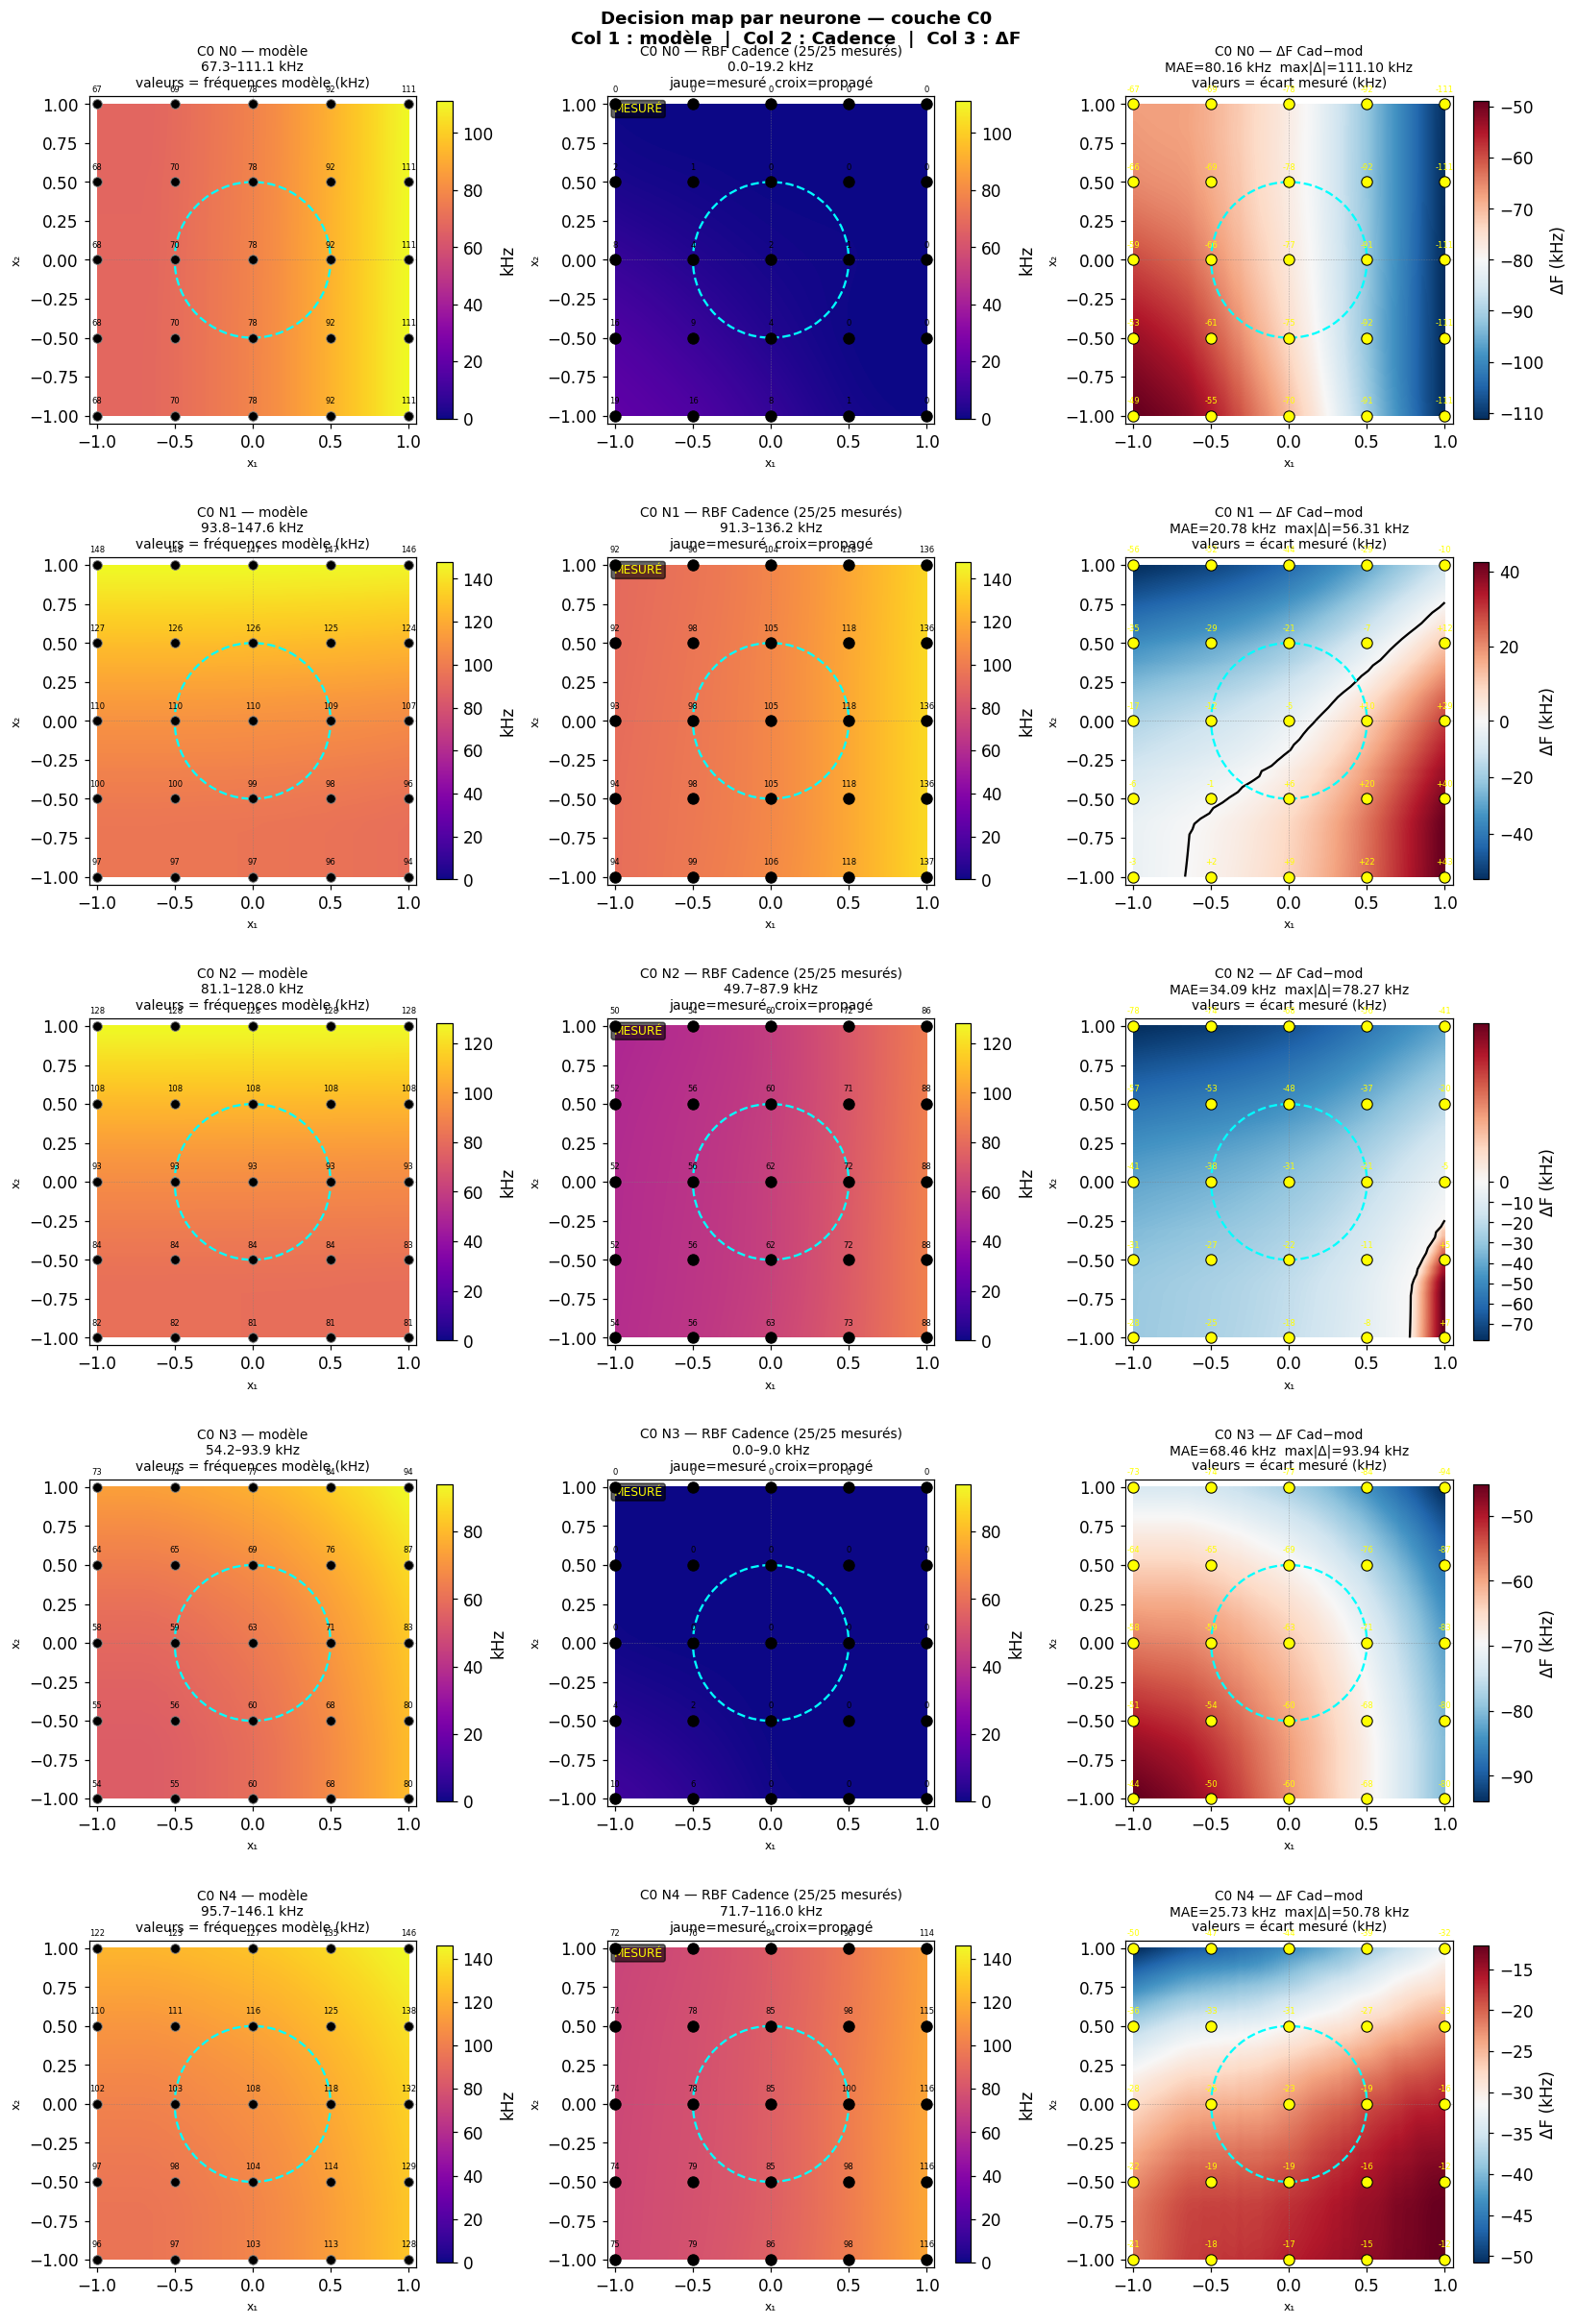

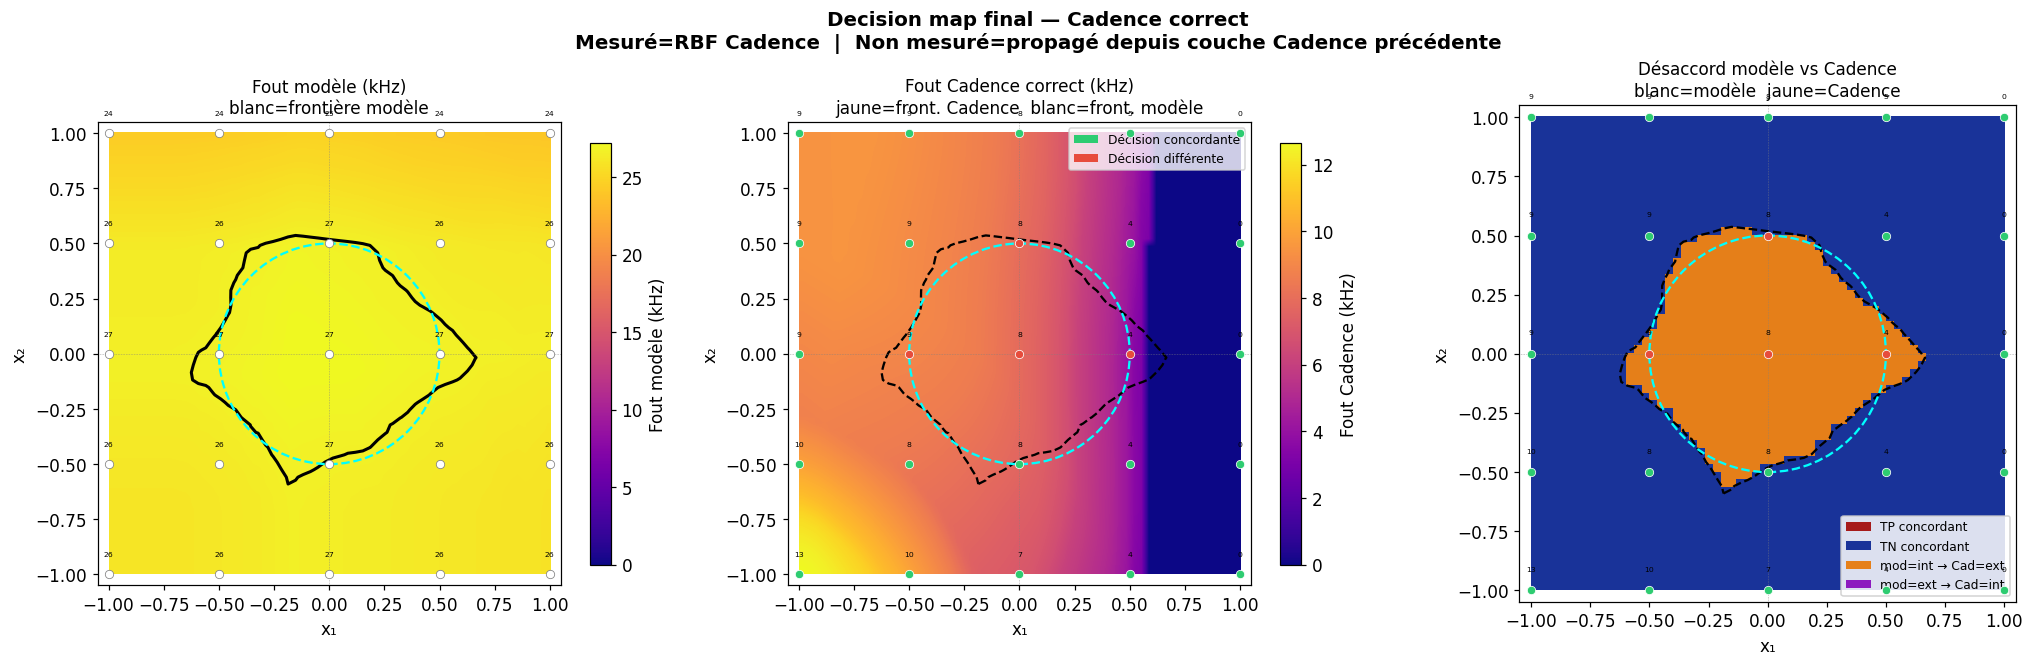


Surface intérieur — modèle          : 20.5%
Surface intérieur — Cadence correct : 0.0%
Zone de désaccord                   : 20.5%
Décalage surface                    : -20.5%


In [62]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE PUR — PROPAGATION CORRECTE
# Si couche Li est mesurée → on substitue les valeurs Cadence
# Si couche Li n'est pas mesurée → on propage depuis la couche
#   précédente (qui peut être Cadence ou modèle entrée)
# La sortie est toujours recalculée depuis la dernière couche
# cachée disponible.
# ══════════════════════════════════════════════════════════════
from scipy.interpolate import RBFInterpolator

N_MAP_CAD = 60

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)
X1G_cad, X2G_cad = np.meshgrid(x1_cad, x2_cad)
query_cad = np.column_stack([X1G_cad.ravel(), X2G_cad.ravel()])
ext_cad   = [-1, 1, -1, 1]

pts_xy = np.array([[pt['x1'], pt['x2']] for pt in GRID_POINTS])

# ── Interpolation RBF par neurone mesuré ─────────────────────
# rbf_by_layer[li][j] = RBFInterpolator ou None si pas mesuré
print('Construction des interpolateurs RBF par neurone...')
rbf_by_layer = []
for li in range(N_HIDDEN_LAYERS):
    cad_key = f'cad_c{li}'
    rbf_layer = []
    for j in range(HIDDEN_SIZES[li]):
        pts_with_val = [(pt['x1'], pt['x2'], float(pt[cad_key][j]))
                        for pt in GRID_POINTS
                        if pt[cad_key][j] is not None]
        if len(pts_with_val) >= 3:
            xy_m  = np.array([[p[0], p[1]] for p in pts_with_val])
            fhz_m = np.array([p[2]          for p in pts_with_val])  # Hz
            rbf_j = RBFInterpolator(xy_m, fhz_m,
                                    kernel='thin_plate_spline',
                                    smoothing=0.3)
            rbf_layer.append(rbf_j)
        else:
            rbf_layer.append(None)   # neurone non mesuré
    rbf_by_layer.append(rbf_layer)
    n_meas = sum(1 for r in rbf_layer if r is not None)
    print(f'  C{li} : {n_meas}/{HIDDEN_SIZES[li]} neurones avec RBF Cadence')

# ── Vérification : quelles couches sont "toutes None" ────────
layer_has_cadence = []
for li in range(N_HIDDEN_LAYERS):
    has = any(r is not None for r in rbf_by_layer[li])
    layer_has_cadence.append(has)
    print(f'  C{li} mesurée : {has}')

# ══════════════════════════════════════════════════════════════
# PROPAGATION CADENCE CORRECTE — point par point
# Pour chaque point (x1, x2) :
#   1. Calculer Fin depuis les tensions (modèle entrée — pas de
#      mesure Cadence sur les entrées)
#   2. Pour chaque couche cachée li :
#      - Si RBF disponible pour neurone j → prendre valeur Cadence
#      - Sinon → propager depuis F_prev avec les synapses du modèle
#   3. Calculer la sortie depuis la dernière couche cachée
# ══════════════════════════════════════════════════════════════
def propagate_cadence_correct(x1, x2, rbf_by_layer, layers_config):
    """
    Propagation où chaque neurone mesuré par Cadence prend sa
    vraie valeur interpolée, et les non-mesurés sont calculés
    en propageant depuis la couche précédente (pas le modèle pur).

    Retourne : fout_cad (Hz), F_history (liste par couche)
    """
    # Entrée : modèle entrée (pas de mesure Cadence sur Vin→Fin)
    Vin = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
    F_cur = np.array([input_f_of_v(v) for v in Vin])
    F_history = [F_cur.copy()]

    for li, cfg in enumerate(layers_config):
        # Propagation normale depuis F_cur
        F_next, _, _ = layer_forward(
            F_cur,
            np.asarray(cfg['signs'],  int),
            np.asarray(cfg['widths'], float)
        )

        # Si couche cachée → substituer les neurones mesurés
        if li < N_HIDDEN_LAYERS:
            query_pt = np.array([[x1, x2]])
            for j in range(HIDDEN_SIZES[li]):
                rbf_j = rbf_by_layer[li][j]
                if rbf_j is not None:
                    # Valeur Cadence interpolée pour ce neurone
                    val_hz = float(rbf_j(query_pt)[0])
                    val_hz = max(0.0, val_hz)   # pas de fréquence négative
                    F_next[j] = val_hz
                # Sinon : F_next[j] reste la valeur propagée depuis
                # F_cur qui est déjà Cadence pour les couches précédentes

        F_history.append(F_next.copy())
        F_cur = F_next

    fout = float(F_cur[0])
    return fout, F_history


# ── Calcul des grilles ────────────────────────────────────────
print('\nCalcul grille Cadence correct...')
grid_cad_correct = np.zeros((N_MAP_CAD, N_MAP_CAD))
grid_mod_ref2    = np.zeros((N_MAP_CAD, N_MAP_CAD))

# Grilles par neurone pour visualisation
grids_cad_correct  = [[np.zeros((N_MAP_CAD, N_MAP_CAD))
                        for _ in range(HIDDEN_SIZES[li])]
                       for li in range(N_HIDDEN_LAYERS)]
grids_mod_correct  = [[np.zeros((N_MAP_CAD, N_MAP_CAD))
                        for _ in range(HIDDEN_SIZES[li])]
                       for li in range(N_HIDDEN_LAYERS)]

for ii in range(N_MAP_CAD):
    for jj in range(N_MAP_CAD):
        x1_q = x1_cad[jj]
        x2_q = x2_cad[ii]

        # Cadence correct
        fout_cad, F_hist_cad = propagate_cadence_correct(
            x1_q, x2_q, rbf_by_layer, layers_config
        )
        grid_cad_correct[ii, jj] = fout_cad / 1e3

        # Modèle pur (référence)
        Vc = V_MIN + (np.array([x1_q, x2_q]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hFc, _, _ = propagate(Vc, layers_config)
        grid_mod_ref2[ii, jj] = hFc[-1][0] / 1e3

        # Grilles par neurone
        for li in range(N_HIDDEN_LAYERS):
            for j in range(HIDDEN_SIZES[li]):
                grids_cad_correct[li][j][ii, jj] = F_hist_cad[li+1][j] / 1e3
                grids_mod_correct[li][j][ii, jj]  = hFc[li+1][j] / 1e3

print('Terminé.')


# ── Decision maps par neurone ─────────────────────────────────
for li in range(N_HIDDEN_LAYERS):
    M = HIDDEN_SIZES[li]
    cad_key = f'cad_c{li}'

    fig, axes = plt.subplots(M, 3, figsize=(15, 4.5 * M), squeeze=False)
    fig.suptitle(
        f'Decision map par neurone — couche C{li}\n'
        f'Col 1 : modèle  |  Col 2 : Cadence  |  Col 3 : ΔF',
        fontsize=12, fontweight='bold'
    )

    for j in range(M):
        g_mod  = grids_mod_correct[li][j]
        g_cad  = grids_cad_correct[li][j]
        g_diff = g_cad - g_mod
        vmax_f = max(g_mod.max(), g_cad.max(), 0.1)
        norm_d = safe_norm(g_diff, vcenter=0)

        is_measured = rbf_by_layer[li][j] is not None
        n_meas = sum(1 for pt in GRID_POINTS
                     if pt[cad_key][j] is not None)

        def scatter_model(ax, li=li, j=j):
            """Points avec valeur MODÈLE sur la carte modèle."""
            for pt in GRID_POINTS:
                mod_val = pt['hF_mod'][li + 1][j] / 1e3
                ax.scatter(pt['x1'], pt['x2'],
                           c='black', s=40,
                           edgecolors='gray', linewidths=0.6, zorder=6)
                ax.text(pt['x1'], pt['x2'] + 0.08,
                        f'{mod_val:.0f}',
                        ha='center', fontsize=5.5,
                        color='black', zorder=7)

        def scatter_cadence(ax, li=li, j=j, cad_key=cad_key):
            """Points avec valeur CADENCE sur la carte Cadence.
            Jaune = mesuré avec valeur réelle.
            Croix grise = non mesuré (valeur propagée)."""
            for pt in GRID_POINTS:
                val = pt[cad_key][j]
                if val is not None:
                    # Mesuré → point jaune avec valeur Cadence
                    ax.scatter(pt['x1'], pt['x2'],
                               c='black', s=55,
                               edgecolors='black', linewidths=0.7, zorder=6)
                    ax.text(pt['x1'], pt['x2'] + 0.08,
                            f'{float(val)/1e3:.0f}',
                            ha='center', fontsize=5.5,
                            color='black', zorder=7)
                else:
                    # Non mesuré → croix grise (valeur propagée)
                    ax.scatter(pt['x1'], pt['x2'],
                               c='gray', s=20, marker='x',
                               linewidths=0.8, zorder=6)

        def scatter_diff(ax, li=li, j=j, cad_key=cad_key):
            """Points avec écart ΔF sur la carte diff."""
            for pt in GRID_POINTS:
                val = pt[cad_key][j]
                mod_val = pt['hF_mod'][li + 1][j] / 1e3
                if val is not None:
                    cad_val = float(val) / 1e3
                    diff    = cad_val - mod_val
                    ax.scatter(pt['x1'], pt['x2'],
                               c='yellow', s=55,
                               edgecolors='black', linewidths=0.7, zorder=6)
                    ax.text(pt['x1'], pt['x2'] + 0.08,
                            f'{diff:+.0f}',
                            ha='center', fontsize=5.5,
                            color='yellow', zorder=7)
                else:
                    ax.scatter(pt['x1'], pt['x2'],
                               c='gray', s=20, marker='x',
                               linewidths=0.8, zorder=6)

        def base_decor2(ax):
            ax.add_patch(Circle((0, 0), DISK_R, color='cyan',
                                 fill=False, lw=1.5, ls='--', zorder=5))
            ax.axhline(0, color='gray', lw=0.4, ls=':')
            ax.axvline(0, color='gray', lw=0.4, ls=':')
            ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
            ax.set_aspect('equal')
            ax.set_xlabel('x₁', fontsize=8)
            ax.set_ylabel('x₂', fontsize=8)

        # ── Col 0 : modèle — points avec valeurs modèle ──────
        ax = axes[j, 0]
        im = ax.imshow(g_mod, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax_f, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)
        scatter_model(ax)   # valeurs modèle sur carte modèle
        base_decor2(ax)
        ax.set_title(f'C{li} N{j} — modèle\n'
                     f'{g_mod.min():.1f}–{g_mod.max():.1f} kHz\n'
                     f'valeurs = fréquences modèle (kHz)',
                     fontsize=9)

        # ── Col 1 : Cadence — points avec valeurs Cadence ────
        ax = axes[j, 1]
        im = ax.imshow(g_cad, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax_f, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)
        scatter_cadence(ax)   # valeurs Cadence sur carte Cadence
        base_decor2(ax)
        badge = f'RBF Cadence ({n_meas}/25 mesurés)' if is_measured \
                else f'Propagé depuis C{li-1} Cadence'
        ax.set_title(f'C{li} N{j} — {badge}\n'
                     f'{g_cad.min():.1f}–{g_cad.max():.1f} kHz\n'
                     f'jaune=mesuré  croix=propagé',
                     fontsize=9)
        ax.text(0.02, 0.98,
                'MESURÉ' if is_measured else 'PROPAGÉ',
                transform=ax.transAxes, fontsize=8, va='top',
                color='yellow' if is_measured else 'cyan',
                bbox=dict(boxstyle='round,pad=0.2',
                          fc='black', alpha=0.6))

        # ── Col 2 : ΔF — points avec écart ───────────────────
        ax = axes[j, 2]
        im = ax.imshow(g_diff, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='RdBu_r',
                       norm=norm_d, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='ΔF (kHz)', shrink=0.85)
        ax.contour(x1_cad, x2_cad, g_diff,
                   levels=[0], colors='black', linewidths=1.5)
        scatter_diff(ax)   # écarts sur carte diff
        base_decor2(ax)
        vals_ec = [pt[f'ecart_c{li}'][j] for pt in GRID_POINTS
                   if pt[f'ecart_c{li}'][j] is not None]
        mae_n = np.mean(np.abs(vals_ec)) if vals_ec else 0.0
        ax.set_title(f'C{li} N{j} — ΔF Cad−mod\n'
                     f'MAE={mae_n:.2f} kHz  '
                     f'max|Δ|={np.nanmax(np.abs(g_diff)):.2f} kHz\n'
                     f'valeurs = écart mesuré (kHz)',
                     fontsize=9)

    plt.tight_layout()
    plt.show()

# ── Decision map final ────────────────────────────────────────
dec_cad_c = (grid_cad_correct >= THRESHOLD_HZ / 1e3).astype(int)
dec_mod_c  = (grid_mod_ref2   >= THRESHOLD_HZ / 1e3).astype(int)

rgb_c = np.zeros((N_MAP_CAD, N_MAP_CAD, 3))
rgb_c[(dec_mod_c==1)&(dec_cad_c==1)] = [0.65, 0.10, 0.10]
rgb_c[(dec_mod_c==0)&(dec_cad_c==0)] = [0.10, 0.20, 0.60]
rgb_c[(dec_mod_c==1)&(dec_cad_c==0)] = [0.90, 0.50, 0.10]
rgb_c[(dec_mod_c==0)&(dec_cad_c==1)] = [0.55, 0.10, 0.75]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle(
    'Decision map final — Cadence correct\n'
    'Mesuré=RBF Cadence  |  Non mesuré=propagé depuis couche Cadence précédente',
    fontsize=13, fontweight='bold'
)

def decor_fin2(ax, title, show_model_pts=False, show_cadence_pts=False):
    ax.add_patch(Circle((0, 0), DISK_R, color='cyan',
                         fill=False, lw=1.5, ls='--', zorder=5))
    ax.axhline(0, color='gray', lw=0.4, ls=':')
    ax.axvline(0, color='gray', lw=0.4, ls=':')
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.set_aspect('equal')
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
    ax.set_title(title, fontsize=11)
    if show_model_pts:
        # Points blancs = positions modèle sur carte modèle
        for pt in GRID_POINTS:
            fmod_val = pt['fmod'] / 1e3
            ax.scatter(pt['x1'], pt['x2'],
                       c='white', s=30,
                       edgecolors='gray', linewidths=0.5, zorder=6)
            ax.text(pt['x1'], pt['x2'] + 0.08,
                    f'{fmod_val:.0f}',
                    ha='center', fontsize=5,
                    color='black', zorder=7)
    if show_cadence_pts:
        # Points jaunes = positions Cadence sur carte Cadence
        for pt in GRID_POINTS:
            fhyb_val = pt['fhyb'] / 1e3
            c = '#2ecc71' if pt['agree'] else '#e74c3c'
            ax.scatter(pt['x1'], pt['x2'],
                       c=c, s=30,
                       edgecolors='white', linewidths=0.5, zorder=6)
            ax.text(pt['x1'], pt['x2'] + 0.08,
                    f'{fhyb_val:.0f}',
                    ha='center', fontsize=5,
                    color='black', zorder=7)

# 1. Fout modèle — points modèle
ax = axes[0]
im = ax.imshow(grid_mod_ref2, origin='lower', extent=ext_cad,
               aspect='equal', cmap='plasma', vmin=0, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout modèle (kHz)', shrink=0.85)
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2)
decor_fin2(ax, 'Fout modèle (kHz)\nblanc=frontière modèle',
           show_model_pts=True)

# 2. Fout Cadence — points Cadence
ax = axes[1]
im = ax.imshow(grid_cad_correct, origin='lower', extent=ext_cad,
               aspect='equal', cmap='plasma', vmin=0, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout Cadence (kHz)', shrink=0.85)
ax.contour(x1_cad, x2_cad, grid_cad_correct,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2.5)
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black',
           linewidths=1.5, linestyles='--')
decor_fin2(ax, 'Fout Cadence correct (kHz)\njaune=front. Cadence  blanc=front. modèle',
           show_cadence_pts=True)
ax.legend(handles=[
    Patch(facecolor='#2ecc71', label='Décision concordante'),
    Patch(facecolor='#e74c3c', label='Décision différente'),
], fontsize=8, loc='upper right', framealpha=0.8)

# 3. Désaccord — points des deux
ax = axes[2]
ax.imshow(rgb_c, origin='lower', extent=ext_cad,
          aspect='equal', interpolation='nearest')
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black',
           linewidths=1.5, linestyles='--')
ax.contour(x1_cad, x2_cad, grid_cad_correct,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2)
decor_fin2(ax, 'Désaccord modèle vs Cadence\nblanc=modèle  jaune=Cadence',
           show_cadence_pts=True)
ax.legend(handles=[
    Patch(facecolor=[0.65,0.10,0.10], label='TP concordant'),
    Patch(facecolor=[0.10,0.20,0.60], label='TN concordant'),
    Patch(facecolor=[0.90,0.50,0.10], label='mod=int → Cad=ext'),
    Patch(facecolor=[0.55,0.10,0.75], label='mod=ext → Cad=int'),
], fontsize=8, loc='lower right', framealpha=0.85)

plt.tight_layout()
plt.show()

pct_m = dec_mod_c.mean()  * 100
pct_c = dec_cad_c.mean()  * 100
pct_d = (dec_mod_c != dec_cad_c).mean() * 100
print(f'\nSurface intérieur — modèle          : {pct_m:.1f}%')
print(f'Surface intérieur — Cadence correct : {pct_c:.1f}%')
print(f'Zone de désaccord                   : {pct_d:.1f}%')
print(f'Décalage surface                    : {pct_c - pct_m:+.1f}%')


In [63]:
# =========================================================
# Empilement progressif contrasté : Simulation vs Cadence
# Chaque ligne = cumul jusqu'à une synapse donnée
# Les faibles courants sont atténués, les forts sont accentués
# =========================================================

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.colors import to_rgb, Normalize
from matplotlib.cm import ScalarMappable


# =========================================================
# 1) Fonctions utilitaires
# =========================================================

def make_rgba_fixed_color(
    data,
    color,
    vmax=None,
    alpha_min=0.00,
    alpha_max=0.80,
    percentile_cut=70,
    gamma=2.5
):
    """
    Convertit une carte 2D en image RGBA.

    Objectif :
    - chaque synapse garde une couleur fixe ;
    - les faibles valeurs deviennent presque invisibles ;
    - les fortes valeurs deviennent très visibles.

    data :
        courant synaptique en pA.

    percentile_cut :
        seuil visuel.
        60 = plus de zones visibles.
        70 = bon compromis.
        80 = seulement les zones fortes.

    gamma :
        accentuation des fortes valeurs.
        1.0 = linéaire.
        2.5 = bon contraste.
        3.5 = contraste très fort.
    """

    data_abs = np.abs(np.nan_to_num(data))

    if vmax is None:
        vmax = float(np.nanmax(data_abs))

    if vmax < 1e-15:
        vmax = 1e-12

    # Seuil : on diminue fortement les zones faibles
    cut = np.percentile(data_abs, percentile_cut)

    # Normalisation entre cut et vmax
    norm = (data_abs - cut) / (vmax - cut + 1e-15)
    norm = np.clip(norm, 0.0, 1.0)

    # Accentuation non linéaire
    norm = norm ** gamma

    alpha = alpha_min + (alpha_max - alpha_min) * norm

    rgb = np.array(to_rgb(color))

    rgba = np.zeros((data.shape[0], data.shape[1], 4))
    rgba[..., 0] = rgb[0]
    rgba[..., 1] = rgb[1]
    rgba[..., 2] = rgb[2]
    rgba[..., 3] = alpha

    return rgba


def compute_fout_from_current(I_pA_grid):
    """
    Convertit une carte de courant en pA vers une carte de fréquence en kHz.
    """

    Nloc = I_pA_grid.shape[0]
    Fout_kHz = np.zeros_like(I_pA_grid)

    for ii in range(Nloc):
        for jj in range(Nloc):
            I_A = I_pA_grid[ii, jj] * 1e-12
            Fout_kHz[ii, jj] = neuron_f_of_i(I_A) / 1e3

    return Fout_kHz


def draw_progressive_stack_contrast(
    ax,
    grid_Iconn,
    colors,
    step_k,
    title,
    x1_loc,
    x2_loc,
    current_vmin,
    current_vmax,
    cbar_label="Icumul (pA)",
    percentile_cut=70,
    gamma=2.5,
    alpha_max=0.80
):
    """
    Dessine l'empilement progressif jusqu'à l'étape step_k.

    step_k = 0 : aucune synapse
    step_k = 1 : N0
    step_k = 2 : N0 + N1
    step_k = 3 : N0 + N1 + N2
    ...
    """

    Nloc = grid_Iconn.shape[1]

    # -----------------------------------------------------
    # Étape 0 : aucun courant
    # -----------------------------------------------------

    if step_k == 0:

        cumul = np.zeros((Nloc, Nloc))

        ax.imshow(
            cumul,
            origin="lower",
            extent=[-1, 1, -1, 1],
            cmap="gray",
            vmin=0,
            vmax=1,
            aspect="equal",
            interpolation="bilinear"
        )

    # -----------------------------------------------------
    # Étape >= 1 : on superpose les synapses déjà ajoutées
    # -----------------------------------------------------

    else:

        cumul = np.sum(grid_Iconn[:step_k], axis=0)

        for j in range(step_k):

            Ij = grid_Iconn[j]

            abs_max_j = max(
                abs(float(np.nanmin(Ij))),
                abs(float(np.nanmax(Ij)))
            )

            if abs_max_j < 1e-15:
                abs_max_j = 1e-12

            rgba = make_rgba_fixed_color(
                Ij,
                color=colors[j],
                vmax=abs_max_j,
                alpha_min=0.00,
                alpha_max=alpha_max,
                percentile_cut=percentile_cut,
                gamma=gamma
            )

            ax.imshow(
                rgba,
                origin="lower",
                extent=[-1, 1, -1, 1],
                aspect="equal",
                interpolation="bilinear"
            )

    # -----------------------------------------------------
    # Sortie du neurone final après cumul
    # -----------------------------------------------------

    Fout_kHz = compute_fout_from_current(cumul)
    thr_grid = Fout_kHz - THRESHOLD_HZ / 1e3

    try:
        ax.contour(
            x1_loc,
            x2_loc,
            thr_grid,
            levels=[0],
            colors="black",
            linewidths=2.2
        )
    except Exception:
        pass

    # -----------------------------------------------------
    # Disque idéal
    # -----------------------------------------------------

    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=1.7,
            ls="--"
        )
    )

    # -----------------------------------------------------
    # Colorbar du courant cumulé
    # -----------------------------------------------------

    if abs(current_vmax - current_vmin) < 1e-15:
        current_vmax = current_vmin + 1e-12

    sm = ScalarMappable(
        norm=Normalize(vmin=current_vmin, vmax=current_vmax),
        cmap="viridis"
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        shrink=0.82,
        pad=0.03
    )

    cbar.set_label(cbar_label, fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    # -----------------------------------------------------
    # Mise en forme
    # -----------------------------------------------------

    ax.set_title(title, fontsize=9, fontweight="bold")

    ax.text(
        0.02,
        -0.16,
        f"Icumul = {np.nanmin(cumul):.1f} à {np.nanmax(cumul):.1f} pA | "
        f"Fout = {np.nanmin(Fout_kHz):.1f} à {np.nanmax(Fout_kHz):.1f} kHz",
        transform=ax.transAxes,
        fontsize=8
    )

    ax.axhline(0, color="gray", lw=0.4, ls=":")
    ax.axvline(0, color="gray", lw=0.4, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")

    return cumul, Fout_kHz


# =========================================================
# 2) Fonction principale
# =========================================================

def plot_progressive_stack_model_vs_cadence_contrast(
    title_prefix="",
    percentile_cut=70,
    gamma=2.5,
    alpha_max=0.80
):
    """
    Affiche l'empilement progressif contrasté :

    ligne 0 : avant toute synapse
    ligne 1 : N0
    ligne 2 : N0 + N1
    ligne 3 : N0 + N1 + N2
    ...

    colonnes :
    gauche = simulation
    droite = Cadence
    """

    N_HIDDEN_OUT = grid_Iconn_mod.shape[0]
    Nloc = grid_Iconn_mod.shape[1]

    x1_loc = np.linspace(-1, 1, Nloc)
    x2_loc = np.linspace(-1, 1, Nloc)

    base_colors = [
        "purple",
        "red",
        "blue",
        "green",
        "orange",
        "brown",
        "magenta",
        "teal",
        "gold",
        "navy",
        "lime",
        "crimson"
    ]

    colors = [base_colors[j % len(base_colors)] for j in range(N_HIDDEN_OUT)]

    n_rows = N_HIDDEN_OUT + 1
    n_cols = 2

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(11, 4.5 * n_rows),
        squeeze=False
    )

    fig.suptitle(
        f"{title_prefix}\n"
        "Empilement progressif contrasté : Simulation vs Cadence\n"
        f"percentile_cut={percentile_cut}, gamma={gamma}, alpha_max={alpha_max}\n"
        "couleur = synapse ; faibles courants atténués ; forts courants accentués ; noir = frontière sortie ; cyan = disque idéal",
        fontsize=13,
        fontweight="bold"
    )

    # -----------------------------------------------------
    # Échelle commune des colorbars du courant cumulé
    # -----------------------------------------------------

    cumul_mod_all = []
    cumul_cad_all = []

    for k in range(n_rows):

        if k == 0:
            cumul_mod_all.append(np.zeros((Nloc, Nloc)))
            cumul_cad_all.append(np.zeros((Nloc, Nloc)))
        else:
            cumul_mod_all.append(np.sum(grid_Iconn_mod[:k], axis=0))
            cumul_cad_all.append(np.sum(grid_Iconn_cad[:k], axis=0))

    all_cumul_values = np.concatenate(
        [c.ravel() for c in cumul_mod_all + cumul_cad_all]
    )

    current_vmin = float(np.nanmin(all_cumul_values))
    current_vmax = float(np.nanmax(all_cumul_values))

    # -----------------------------------------------------
    # Affichage étape par étape
    # -----------------------------------------------------

    for k in range(n_rows):

        if k == 0:

            step_label = "Étape 0 — avant toute synapse"

        else:

            added_neurons = " + ".join([f"N{j}" for j in range(k)])
            last_j = k - 1

            sign_txt = "+" if signs_out[last_j, 0] == 1 else "-"
            w_txt = widths_out[last_j, 0]

            step_label = (
                f"Étape {k} — cumul {added_neurons}\n"
                f"dernière ajoutée : N{last_j}, synapse {sign_txt}, W={w_txt:.4g}"
            )

        # Simulation
        draw_progressive_stack_contrast(
            ax=axes[k, 0],
            grid_Iconn=grid_Iconn_mod,
            colors=colors,
            step_k=k,
            title=f"Simulation\n{step_label}",
            x1_loc=x1_loc,
            x2_loc=x2_loc,
            current_vmin=current_vmin,
            current_vmax=current_vmax,
            cbar_label="Icumul sim (pA)",
            percentile_cut=percentile_cut,
            gamma=gamma,
            alpha_max=alpha_max
        )

        # Cadence
        draw_progressive_stack_contrast(
            ax=axes[k, 1],
            grid_Iconn=grid_Iconn_cad,
            colors=colors,
            step_k=k,
            title=f"Cadence\n{step_label}",
            x1_loc=x1_loc,
            x2_loc=x2_loc,
            current_vmin=current_vmin,
            current_vmax=current_vmax,
            cbar_label="Icumul Cadence (pA)",
            percentile_cut=percentile_cut,
            gamma=gamma,
            alpha_max=alpha_max
        )

    plt.tight_layout()
    plt.show()



Courants reconstruits vers la sortie
grid_Iconn_mod shape = (5, 60, 60)
grid_Iconn_mod min/max = -13.436672407045013 55.346809548924355 pA
grid_Iconn_cad shape = (5, 60, 60)
grid_Iconn_cad min/max = -8.45276450245707 19.0595454233136 pA


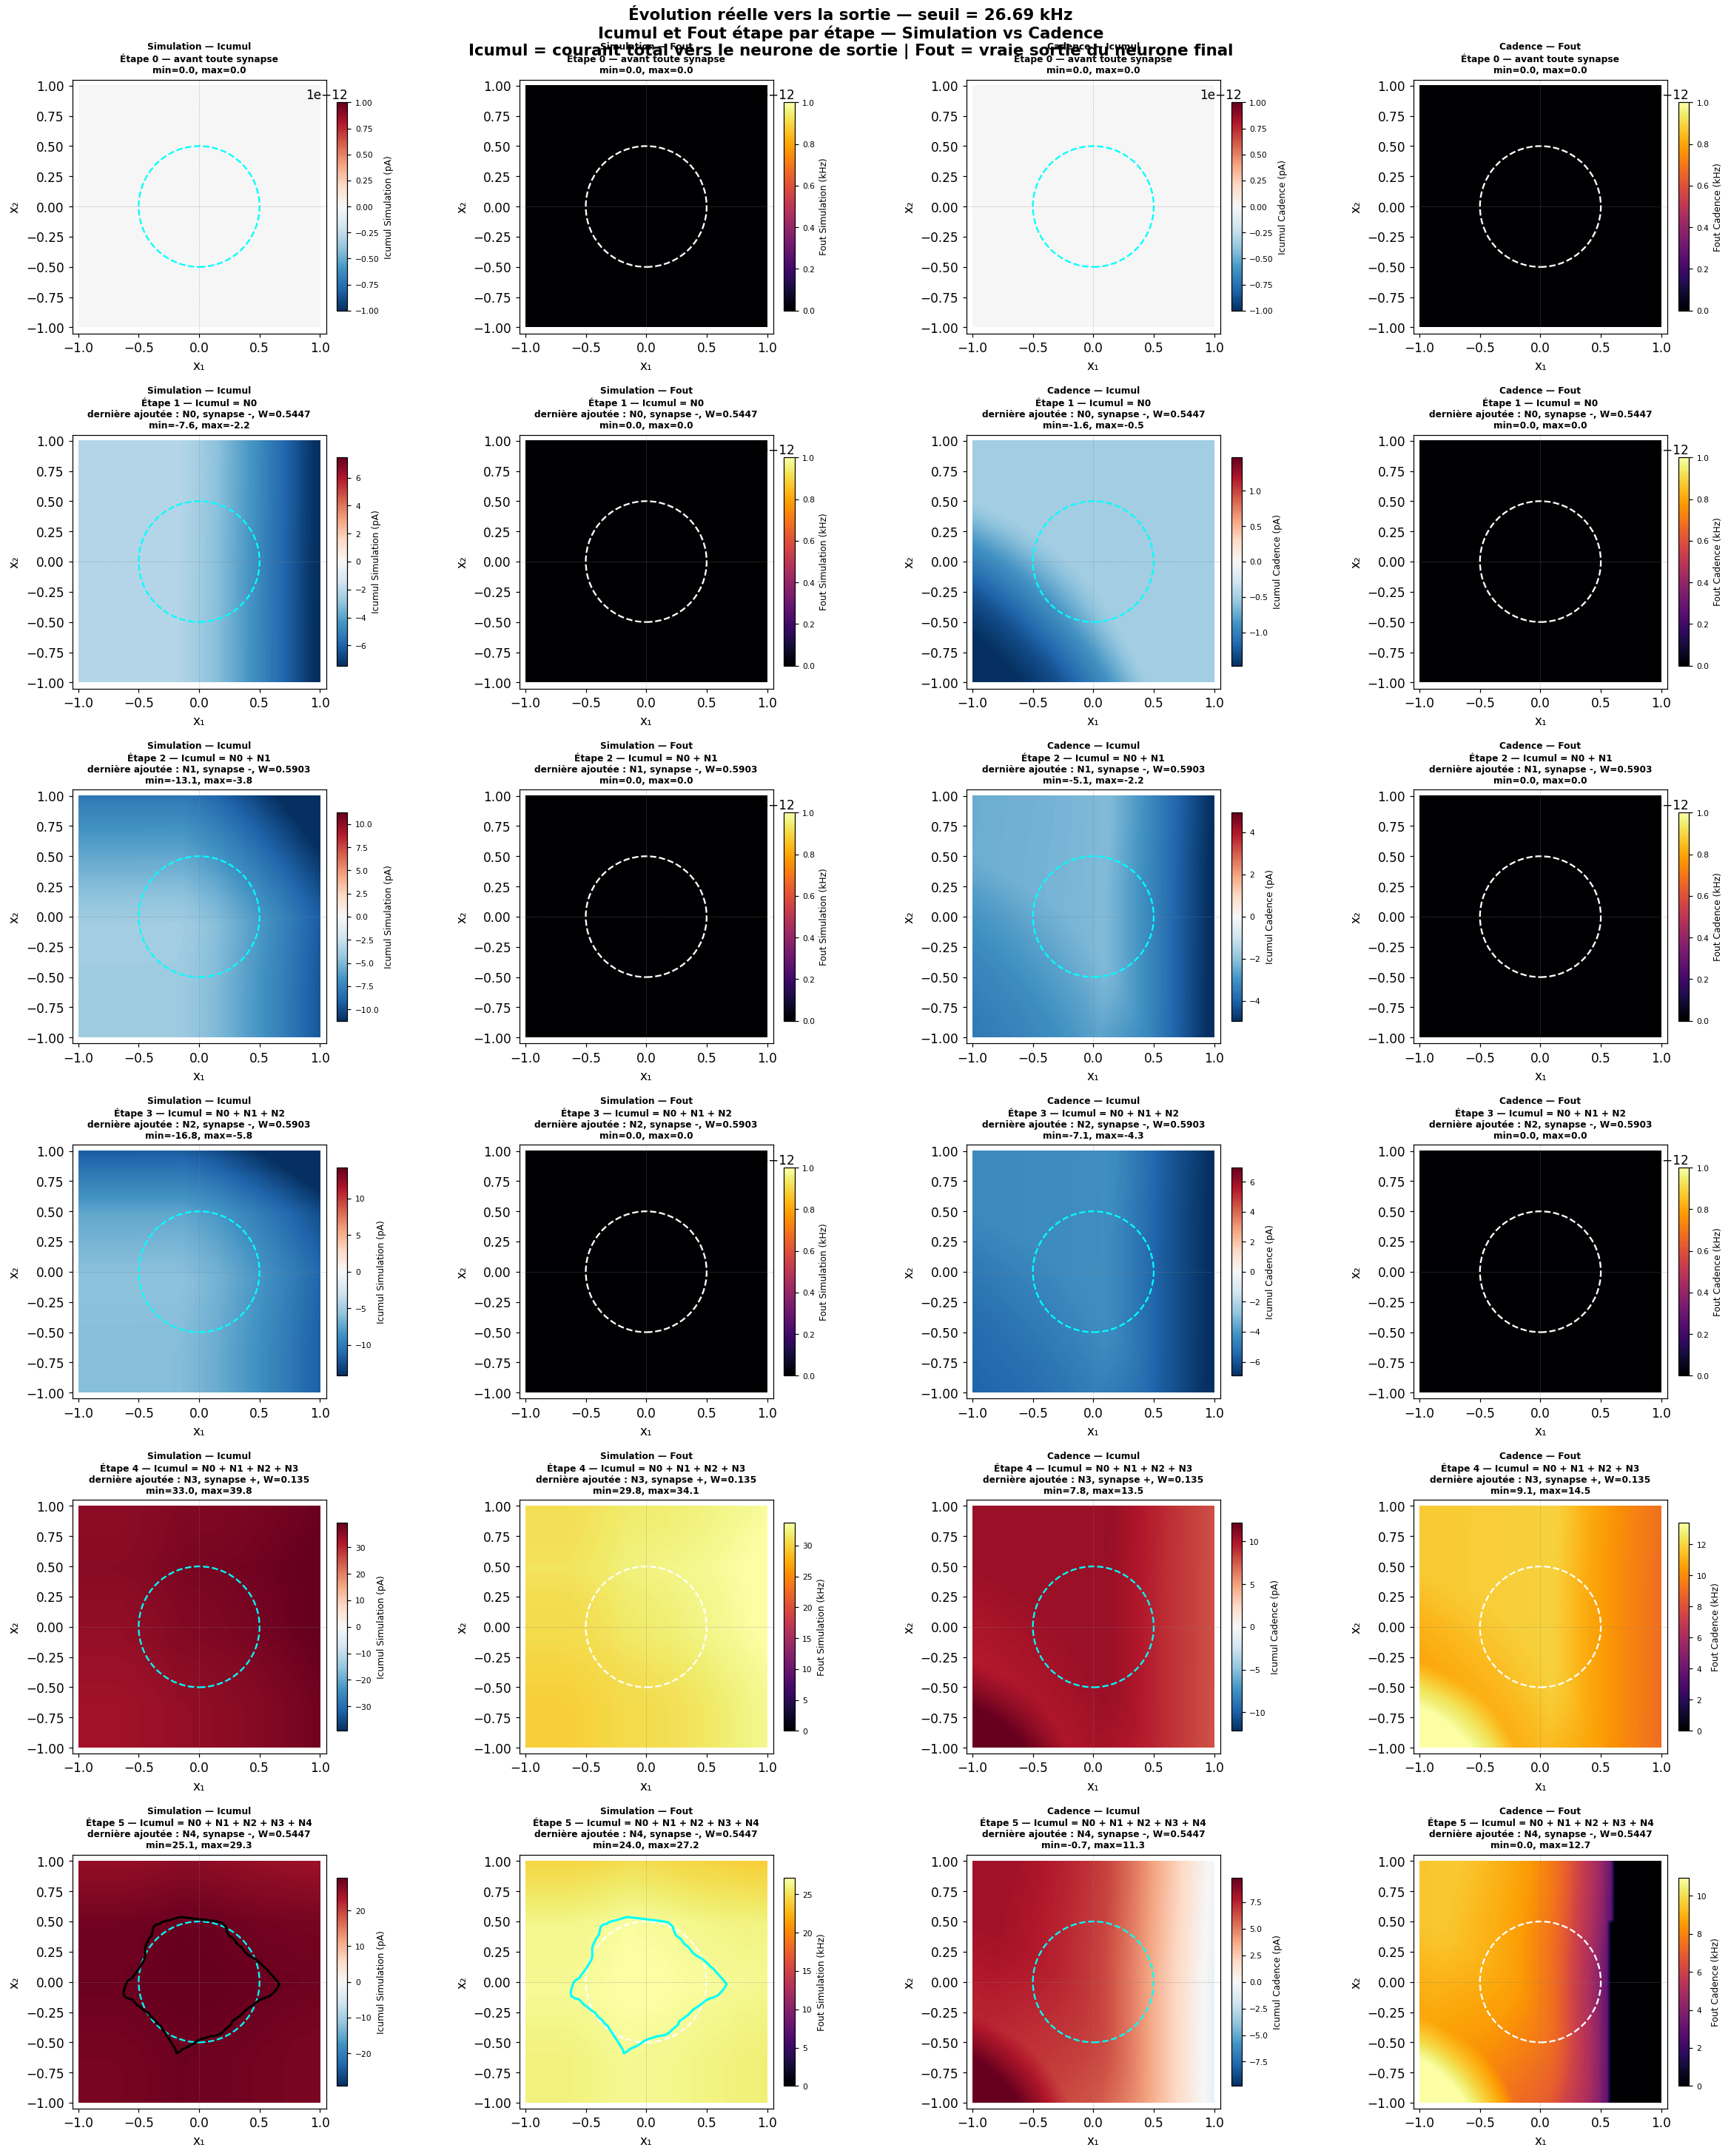

In [64]:
# =========================================================
# Visualisation logique : Icumul et Fout étape par étape
# Simulation vs Cadence
#
# Icumul(k) = somme des courants synaptiques jusqu'à l'étape k
# Fout(k)   = sortie du neurone final après Icumul(k)
# =========================================================

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm, Normalize


# =========================================================
# 1) Reconstruction des courants synaptiques vers la sortie
# =========================================================

cfg_out = layers_config[-1]

signs_out  = np.asarray(cfg_out["signs"], int)
widths_out = np.asarray(cfg_out["widths"], float)

N_HIDDEN_OUT = signs_out.shape[0]
N = grids_cad_correct[0][0].shape[0]

grid_Iconn_cad = np.zeros((N_HIDDEN_OUT, N, N))
grid_Iconn_mod = np.zeros((N_HIDDEN_OUT, N, N))

for j in range(N_HIDDEN_OUT):

    s = signs_out[j, 0]
    w = widths_out[j, 0]

    Fpre_cad_kHz = grids_cad_correct[0][j]
    Fpre_mod_kHz = grids_mod_correct[0][j]

    for ii in range(N):
        for jj in range(N):

            Fcad_Hz = Fpre_cad_kHz[ii, jj] * 1e3
            Fmod_Hz = Fpre_mod_kHz[ii, jj] * 1e3

            if s == 1:
                grid_Iconn_cad[j, ii, jj] = isyn_exc(Fcad_Hz, w) * 1e12
                grid_Iconn_mod[j, ii, jj] = isyn_exc(Fmod_Hz, w) * 1e12

            elif s == -1:
                grid_Iconn_cad[j, ii, jj] = -isyn_inh(Fcad_Hz, w) * 1e12
                grid_Iconn_mod[j, ii, jj] = -isyn_inh(Fmod_Hz, w) * 1e12

            else:
                grid_Iconn_cad[j, ii, jj] = 0.0
                grid_Iconn_mod[j, ii, jj] = 0.0


print("Courants reconstruits vers la sortie")
print("grid_Iconn_mod shape =", grid_Iconn_mod.shape)
print("grid_Iconn_mod min/max =", np.nanmin(grid_Iconn_mod), np.nanmax(grid_Iconn_mod), "pA")
print("grid_Iconn_cad shape =", grid_Iconn_cad.shape)
print("grid_Iconn_cad min/max =", np.nanmin(grid_Iconn_cad), np.nanmax(grid_Iconn_cad), "pA")


# =========================================================
# 2) Courant pA -> fréquence kHz
# =========================================================

def compute_fout_from_current(I_pA_grid):
    """
    Convertit une carte de courant pA vers une carte de fréquence kHz.
    """

    Nloc = I_pA_grid.shape[0]
    Fout_kHz = np.zeros_like(I_pA_grid)

    for ii in range(Nloc):
        for jj in range(Nloc):
            I_A = I_pA_grid[ii, jj] * 1e-12
            Fout_kHz[ii, jj] = neuron_f_of_i(I_A) / 1e3

    return Fout_kHz


# =========================================================
# 3) Construction des cartes cumulées
# =========================================================

def build_cumulative_current_and_frequency(grid_Iconn):
    """
    Retourne :
        cumul_list[k] = Icumul à l'étape k
        fout_list[k]  = Fout à l'étape k
    """

    Nloc = grid_Iconn.shape[1]
    Nsteps = grid_Iconn.shape[0] + 1

    cumul = np.zeros((Nloc, Nloc))

    cumul_list = []
    fout_list = []

    # Étape 0
    cumul_list.append(cumul.copy())
    fout_list.append(compute_fout_from_current(cumul))

    # Étapes 1...N
    for k in range(1, Nsteps):

        j = k - 1
        cumul = cumul + grid_Iconn[j]

        cumul_list.append(cumul.copy())
        fout_list.append(compute_fout_from_current(cumul))

    return cumul_list, fout_list


cumul_mod_list, fout_mod_list = build_cumulative_current_and_frequency(grid_Iconn_mod)
cumul_cad_list, fout_cad_list = build_cumulative_current_and_frequency(grid_Iconn_cad)


# =========================================================
# 4) Fonction principale de plot
# =========================================================

def plot_icumul_and_fout_model_vs_cadence(
    title_prefix="",
    robust_percentile_current=98,
    robust_percentile_freq=98,
    local_scale=True
):
    """
    Affiche à chaque étape :

        Col 0 : Simulation Icumul
        Col 1 : Simulation Fout
        Col 2 : Cadence Icumul
        Col 3 : Cadence Fout

    C'est la visualisation la plus logique pour comprendre le résultat.
    """

    Nsteps = N_HIDDEN_OUT + 1
    Nloc = grid_Iconn_mod.shape[1]

    x1_loc = np.linspace(-1, 1, Nloc)
    x2_loc = np.linspace(-1, 1, Nloc)

    fig, axes = plt.subplots(
        Nsteps,
        4,
        figsize=(22, 4.5 * Nsteps),
        squeeze=False
    )

    fig.suptitle(
        f"{title_prefix}\n"
        "Icumul et Fout étape par étape — Simulation vs Cadence\n"
        "Icumul = courant total vers le neurone de sortie | Fout = vraie sortie du neurone final",
        fontsize=14,
        fontweight="bold"
    )

    # Échelles globales si besoin
    if not local_scale:

        all_cur = np.concatenate(
            [m.ravel() for m in cumul_mod_list + cumul_cad_list]
        )
        vmax_cur_global = np.percentile(np.abs(all_cur), robust_percentile_current)

        if vmax_cur_global < 1e-15:
            vmax_cur_global = 1e-12

        norm_cur_global = TwoSlopeNorm(
            vmin=-vmax_cur_global,
            vcenter=0.0,
            vmax=vmax_cur_global
        )

        all_fout = np.concatenate(
            [m.ravel() for m in fout_mod_list + fout_cad_list]
        )
        vmax_f_global = np.percentile(all_fout, robust_percentile_freq)

        if vmax_f_global < 1e-15:
            vmax_f_global = 1e-12

        norm_f_global = Normalize(
            vmin=0.0,
            vmax=vmax_f_global
        )

    for k in range(Nsteps):

        if k == 0:
            step_label = "Étape 0 — avant toute synapse"
        else:
            added = " + ".join([f"N{j}" for j in range(k)])
            last_j = k - 1
            sign_txt = "+" if signs_out[last_j, 0] == 1 else "-"
            w_txt = widths_out[last_j, 0]

            step_label = (
                f"Étape {k} — Icumul = {added}\n"
                f"dernière ajoutée : N{last_j}, synapse {sign_txt}, W={w_txt:.4g}"
            )

        Ic_mod = cumul_mod_list[k]
        Ic_cad = cumul_cad_list[k]

        Fo_mod = fout_mod_list[k]
        Fo_cad = fout_cad_list[k]

        # -------------------------------------------------
        # Normalisation
        # -------------------------------------------------

        if local_scale:

            # Courant : échelle séparée mod/cad pour bien voir les formes
            vmax_cur_mod = np.percentile(np.abs(Ic_mod.ravel()), robust_percentile_current)
            vmax_cur_cad = np.percentile(np.abs(Ic_cad.ravel()), robust_percentile_current)

            if vmax_cur_mod < 1e-15:
                vmax_cur_mod = 1e-12
            if vmax_cur_cad < 1e-15:
                vmax_cur_cad = 1e-12

            norm_cur_mod = TwoSlopeNorm(
                vmin=-vmax_cur_mod,
                vcenter=0.0,
                vmax=vmax_cur_mod
            )

            norm_cur_cad = TwoSlopeNorm(
                vmin=-vmax_cur_cad,
                vcenter=0.0,
                vmax=vmax_cur_cad
            )

            # Fréquence : échelle séparée mod/cad
            vmax_f_mod = np.percentile(Fo_mod.ravel(), robust_percentile_freq)
            vmax_f_cad = np.percentile(Fo_cad.ravel(), robust_percentile_freq)

            if vmax_f_mod < 1e-15:
                vmax_f_mod = 1e-12
            if vmax_f_cad < 1e-15:
                vmax_f_cad = 1e-12

            norm_f_mod = Normalize(vmin=0.0, vmax=vmax_f_mod)
            norm_f_cad = Normalize(vmin=0.0, vmax=vmax_f_cad)

        else:

            norm_cur_mod = norm_cur_global
            norm_cur_cad = norm_cur_global
            norm_f_mod = norm_f_global
            norm_f_cad = norm_f_global

        datasets = [
            (Ic_mod, "RdBu_r", norm_cur_mod, "Icumul Simulation (pA)", "Simulation — Icumul"),
            (Fo_mod, "inferno", norm_f_mod, "Fout Simulation (kHz)", "Simulation — Fout"),
            (Ic_cad, "RdBu_r", norm_cur_cad, "Icumul Cadence (pA)", "Cadence — Icumul"),
            (Fo_cad, "inferno", norm_f_cad, "Fout Cadence (kHz)", "Cadence — Fout"),
        ]

        for col, (data, cmap, norm, cbar_label, title_col) in enumerate(datasets):

            ax = axes[k, col]

            im = ax.imshow(
                data,
                origin="lower",
                extent=[-1, 1, -1, 1],
                cmap=cmap,
                norm=norm,
                aspect="equal",
                interpolation="bilinear"
            )

            cbar = plt.colorbar(im, ax=ax, shrink=0.82, pad=0.03)
            cbar.set_label(cbar_label, fontsize=8)
            cbar.ax.tick_params(labelsize=7)

            # Frontière de sortie : seulement sur les cartes Fout et aussi possible sur Icumul
            if col in [0, 1]:
                thr_grid = Fo_mod - THRESHOLD_HZ / 1e3
            else:
                thr_grid = Fo_cad - THRESHOLD_HZ / 1e3

            try:
                ax.contour(
                    x1_loc,
                    x2_loc,
                    thr_grid,
                    levels=[0],
                    colors="cyan" if "Fout" in title_col else "black",
                    linewidths=2.0
                )
            except Exception:
                pass

            ax.add_patch(
                Circle(
                    (0, 0),
                    DISK_R,
                    color="white" if "Fout" in title_col else "cyan",
                    fill=False,
                    lw=1.5,
                    ls="--"
                )
            )

            ax.set_title(
                f"{title_col}\n{step_label}\n"
                f"min={np.nanmin(data):.1f}, max={np.nanmax(data):.1f}",
                fontsize=8,
                fontweight="bold"
            )

            ax.axhline(0, color="gray", lw=0.4, ls=":")
            ax.axvline(0, color="gray", lw=0.4, ls=":")

            ax.set_xlim(-1.05, 1.05)
            ax.set_ylim(-1.05, 1.05)
            ax.set_aspect("equal")
            ax.set_xlabel("x₁")
            ax.set_ylabel("x₂")

    plt.tight_layout()
    plt.show()


# =========================================================
# 5) Lancement
# =========================================================

plot_icumul_and_fout_model_vs_cadence(
    title_prefix=f"Évolution réelle vers la sortie — seuil = {THRESHOLD_HZ/1e3:.2f} kHz",
    robust_percentile_current=98,
    robust_percentile_freq=98,
    local_scale=True
)

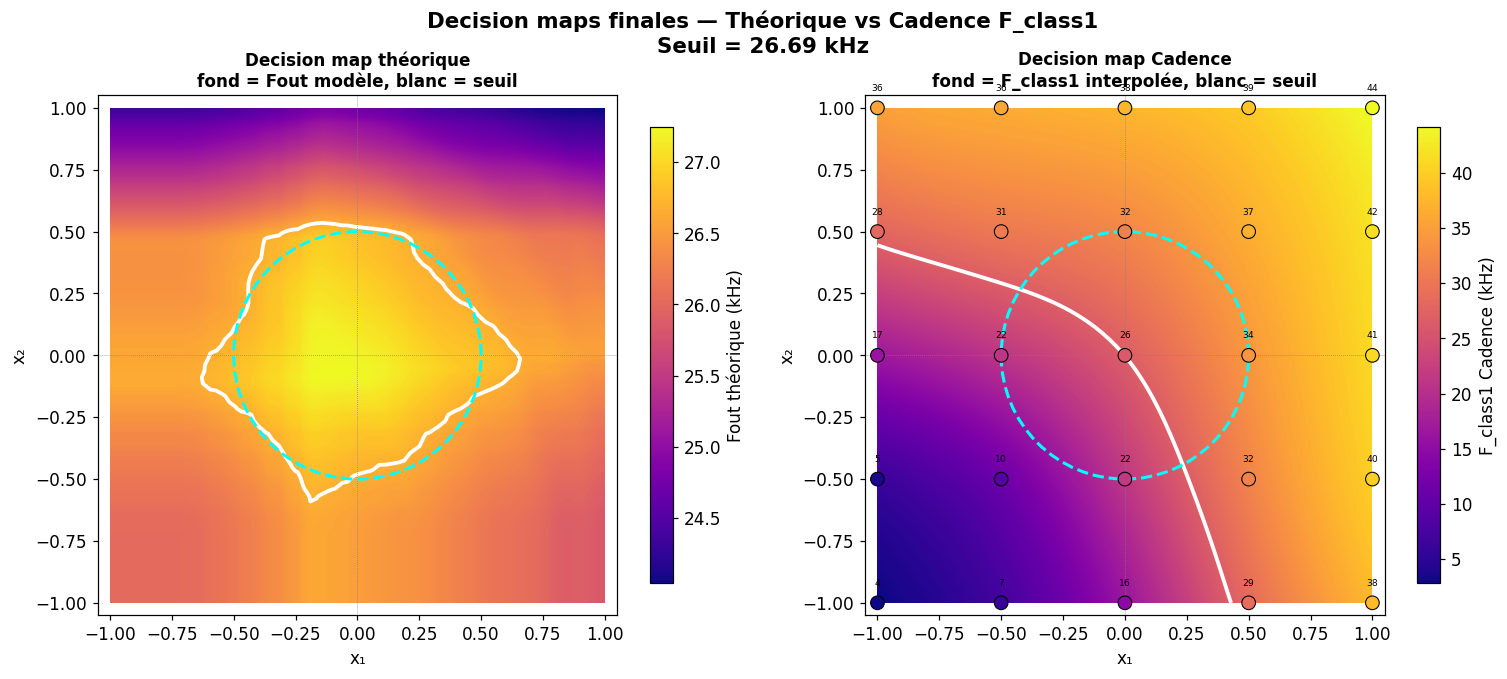

COMPARAISON DECISION MAP THÉORIQUE vs CADENCE
Fout théorique : 24.04 → 27.25 kHz
Fout Cadence   : 2.79 → 44.13 kHz
Seuil          : 26.69 kHz
-----------------------------------------------------------------
Surface classe 1 théorique : 20.7%
Surface classe 1 Cadence   : 62.1%
Désaccord théorique/Cadence: 59.6%


In [65]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP FINALE — THÉORIQUE vs CADENCE F_class1
# Fond = fréquence brute, pas décision binaire
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F1 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F1_CAD = np.array([
     4.0e3,  7.0e3, 15.5e3, 29.0e3, 38.0e3,
     5.0e3, 10.0e3, 22.0e3, 32.0e3, 40.0e3,
    17.0e3, 21.5e3, 26.5e3, 34.0e3, 41.0e3,
    28.5e3, 31.0e3, 31.5e3, 37.0e3, 41.5e3,
    35.5e3, 36.0e3, 37.5e3, 39.0e3, 44.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F1_CAD[i]




# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_COMPARE = 80

x1_cmp = np.linspace(-1, 1, N_MAP_COMPARE)
x2_cmp = np.linspace(-1, 1, N_MAP_COMPARE)

X1_cmp, X2_cmp = np.meshgrid(x1_cmp, x2_cmp)

TH_KHZ = THRESHOLD_HZ / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Carte théorique : propagation modèle
# ─────────────────────────────────────────────────────────────

grid_fout_theo = np.zeros((N_MAP_COMPARE, N_MAP_COMPARE))

for ii, x2 in enumerate(x2_cmp):
    for jj, x1 in enumerate(x1_cmp):
        Vin = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hF, _, _ = propagate(Vin, layers_config)
        grid_fout_theo[ii, jj] = hF[-1][0] / 1e3   # kHz


# ─────────────────────────────────────────────────────────────
# 4. Carte Cadence : interpolation de F_class1 mesurée
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cmp = np.column_stack([X1_cmp.ravel(), X2_cmp.ravel()])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cmp).reshape(N_MAP_COMPARE, N_MAP_COMPARE) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 5. Décisions binaires utiles pour résumé
# ─────────────────────────────────────────────────────────────

dec_theo = (grid_fout_theo >= TH_KHZ).astype(int)
dec_cad  = (grid_fout_cad  >= TH_KHZ).astype(int)


# ─────────────────────────────────────────────────────────────
# 6. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )
    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 7. Figure : deux decision maps fréquence brute
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fig.suptitle(
    f"Decision maps finales — Théorique vs Cadence F_class1\n"
    f"Seuil = {TH_KHZ:.2f} kHz",
    fontsize=14,
    fontweight="bold"
)


# ── Carte théorique ──────────────────────────────────────────

ax = axes[0]

im = ax.imshow(
    grid_fout_theo,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="Fout théorique (kHz)", shrink=0.85)

# Frontière du seuil si visible
if grid_fout_theo.min() <= TH_KHZ <= grid_fout_theo.max():
    ax.contour(
        x1_cmp,
        x2_cmp,
        grid_fout_theo,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fth = {grid_fout_theo.min():.1f}–{grid_fout_theo.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )

decorate_map(ax)

ax.set_title(
    "Decision map théorique\nfond = Fout modèle, blanc = seuil",
    fontsize=11,
    fontweight="bold"
)


# ── Carte Cadence F_class1 ───────────────────────────────────

ax = axes[1]

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)

# Frontière du seuil si visible
if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cmp,
        x2_cmp,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )

# Points mesurés Cadence
sc = ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)

# Valeurs F_class1 sur les points
for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"]/1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )

decorate_map(ax)

ax.set_title(
    "Decision map Cadence\nfond = F_class1 interpolée, blanc = seuil",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ─────────────────────────────────────────────────────────────
# 8. Résumé numérique
# ─────────────────────────────────────────────────────────────

surface_theo = 100 * dec_theo.mean()
surface_cad  = 100 * dec_cad.mean()
desaccord    = 100 * (dec_theo != dec_cad).mean()

print("=" * 65)
print("COMPARAISON DECISION MAP THÉORIQUE vs CADENCE")
print("=" * 65)
print(f"Fout théorique : {grid_fout_theo.min():.2f} → {grid_fout_theo.max():.2f} kHz")
print(f"Fout Cadence   : {grid_fout_cad.min():.2f} → {grid_fout_cad.max():.2f} kHz")
print(f"Seuil          : {TH_KHZ:.2f} kHz")
print("-" * 65)
print(f"Surface classe 1 théorique : {surface_theo:.1f}%")
print(f"Surface classe 1 Cadence   : {surface_cad:.1f}%")
print(f"Désaccord théorique/Cadence: {desaccord:.1f}%")
print("=" * 65)

Calcul colormaps Vx/Vy pour couche cachée C0
Grille : 60 x 60 = 3600 points
Terminé.


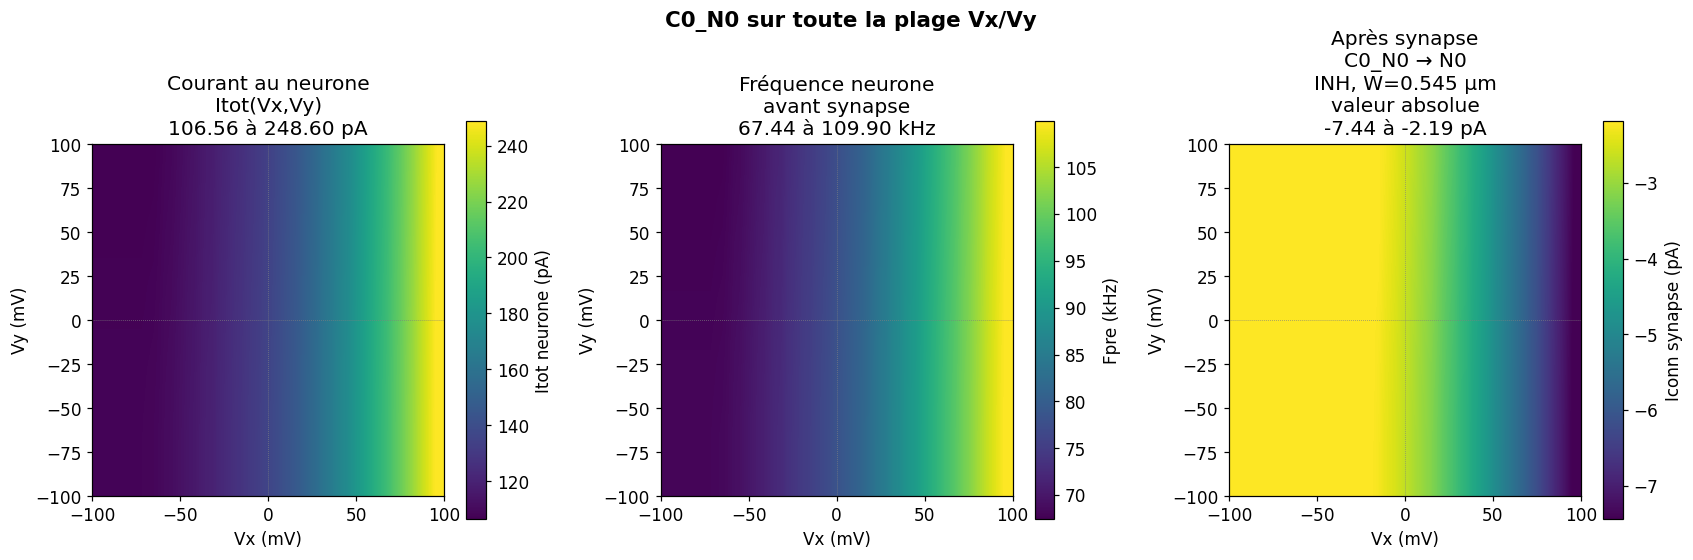

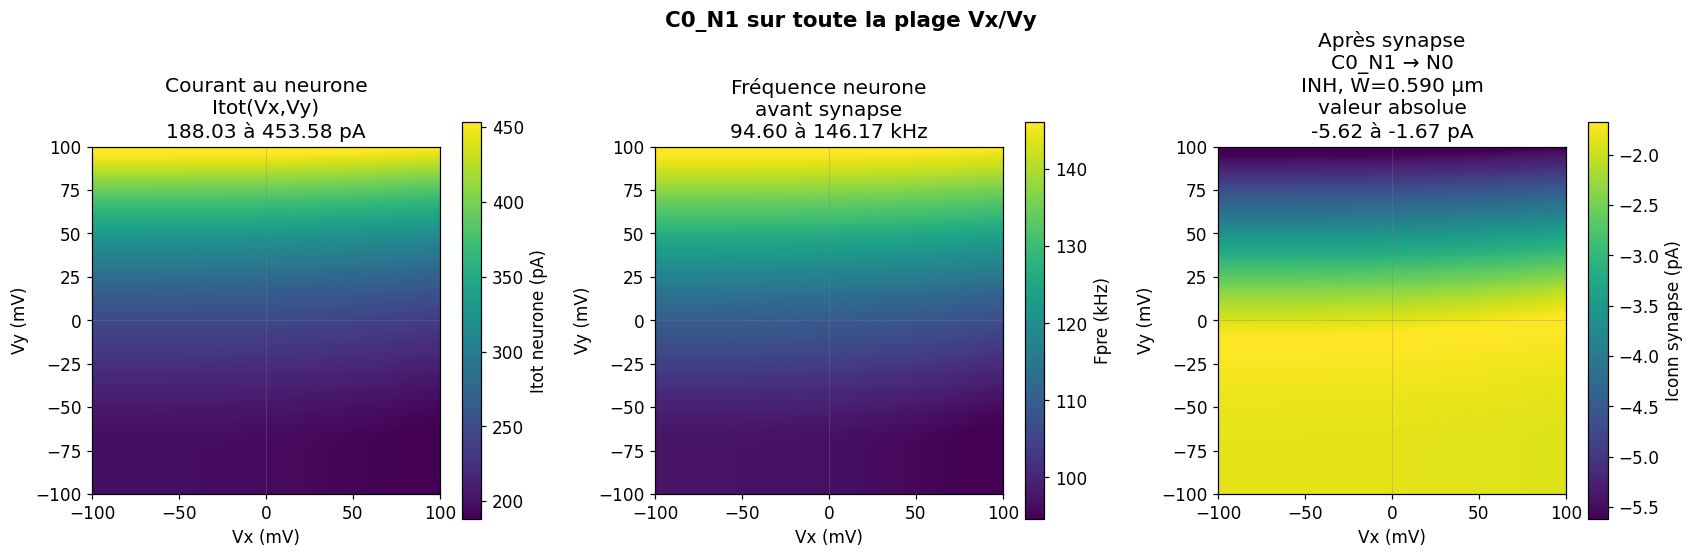

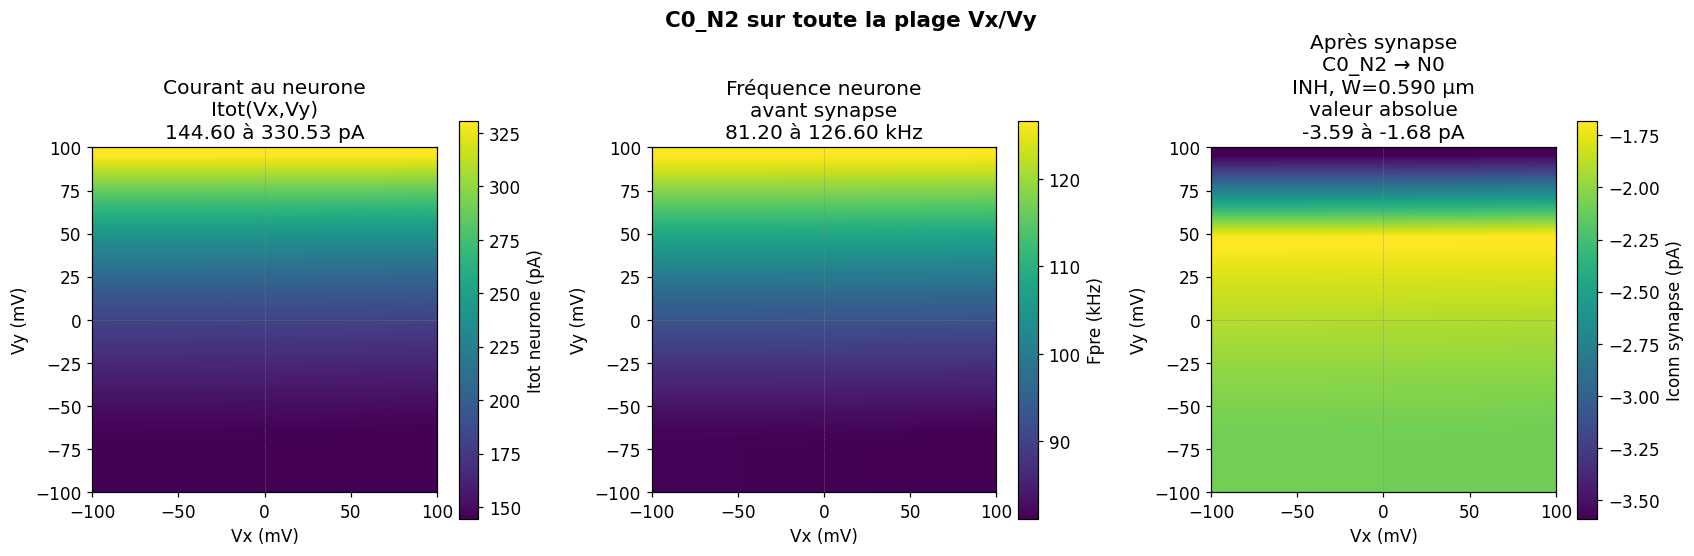

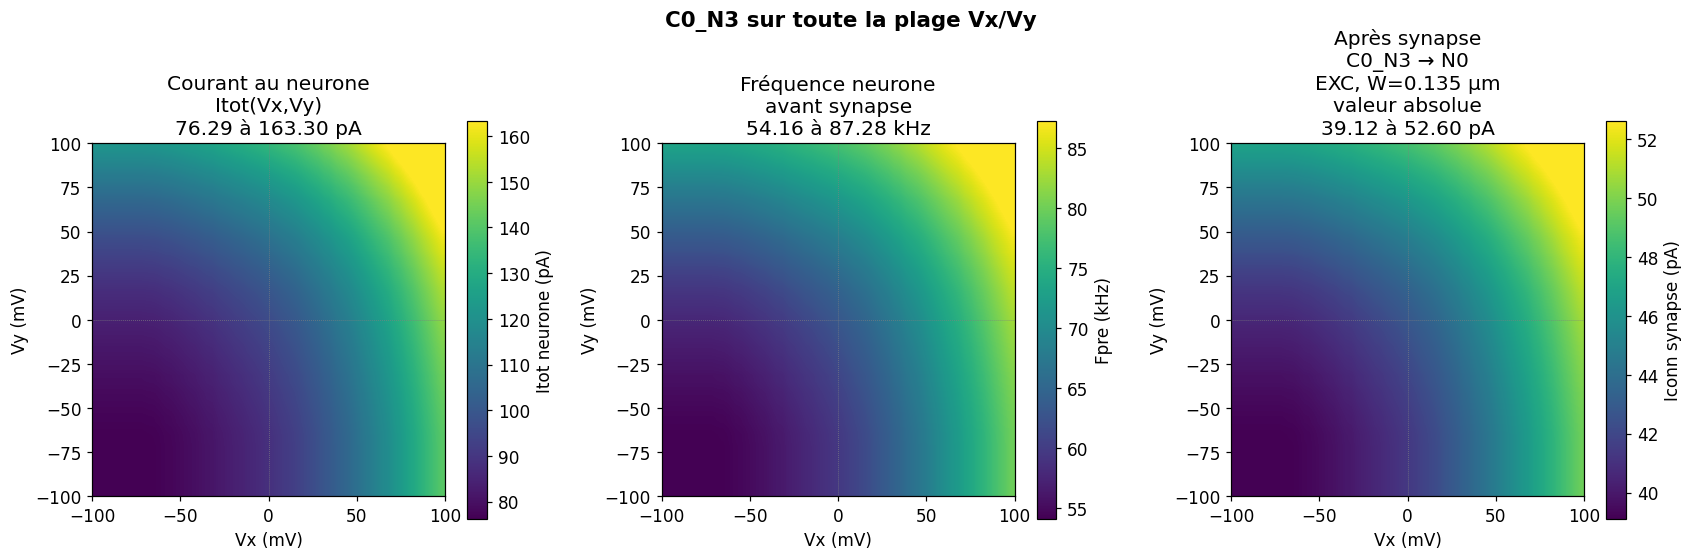

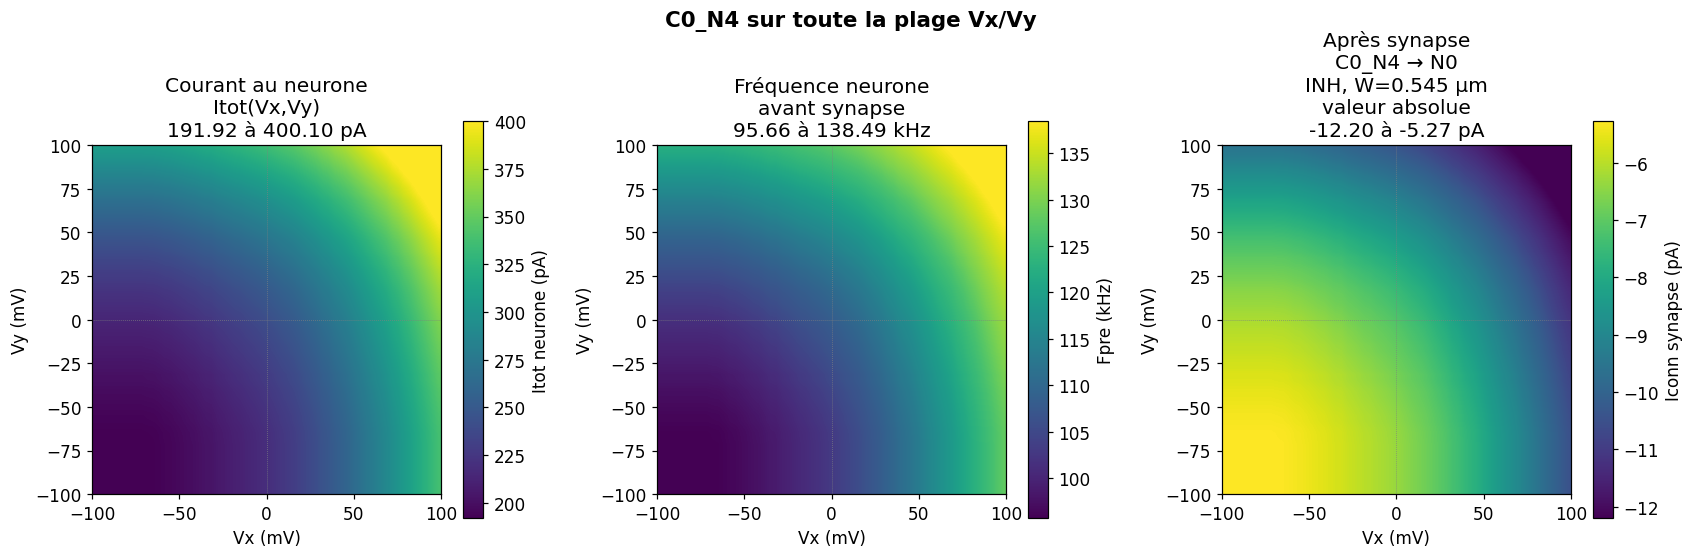

In [66]:
# ══════════════════════════════════════════════════════════════
# 14. Colormaps Vx/Vy : courant neurone caché -> synapse sortie
#     Version complète avec colormap adaptée après synapse
# ══════════════════════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Résolution de la carte
N_GRID_LOCAL = 60

# True = montre Iconn - moyenne(Iconn)
# False = montre Iconn absolu
SHOW_RELATIVE_VARIATION = False

# Percentiles pour accentuer les variations
# 2-98 = doux
# 5-95 = plus contrasté
PERCENTILE_LOW = 2
PERCENTILE_HIGH = 98

# Plage normalisée [-1, 1]
x1_axis_local = np.linspace(-1, 1, N_GRID_LOCAL)
x2_axis_local = np.linspace(-1, 1, N_GRID_LOCAL)

# Conversion vers Vx, Vy réels
vx_axis = V_MIN + (x1_axis_local + 1.0) * (V_MAX - V_MIN) / 2.0
vy_axis = V_MIN + (x2_axis_local + 1.0) * (V_MAX - V_MIN) / 2.0

extent_mv = [
    vx_axis[0] * 1e3,
    vx_axis[-1] * 1e3,
    vy_axis[0] * 1e3,
    vy_axis[-1] * 1e3
]


def adaptive_norm_and_cmap(mat, center_zero=True):
    """
    Normalisation adaptée pour mieux voir les variations.

    - Utilise les percentiles au lieu de min/max.
    - Si la carte traverse 0, utilise une colormap divergente.
    - Sinon utilise une colormap séquentielle.
    """

    vals = np.asarray(mat, float)
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        return plt.Normalize(vmin=-1, vmax=1), "viridis", -1, 1

    p_low, p_high = np.percentile(vals, [PERCENTILE_LOW, PERCENTILE_HIGH])

    # Si les percentiles sont trop proches, revenir au min/max
    if np.isclose(p_low, p_high):
        p_low = float(np.nanmin(vals))
        p_high = float(np.nanmax(vals))

    # Si encore constant, créer une petite plage artificielle
    if np.isclose(p_low, p_high):
        delta = max(abs(p_low) * 0.05, 1e-3)
        p_low -= delta
        p_high += delta

    # Cas signé autour de zéro
    if center_zero and (p_low < 0 < p_high):
        vmax = max(abs(p_low), abs(p_high))
        norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
        cmap = "RdBu_r"
        return norm, cmap, -vmax, vmax

    # Cas non signé ou tout positif/tout négatif
    norm = plt.Normalize(vmin=p_low, vmax=p_high)
    cmap = "viridis"
    return norm, cmap, p_low, p_high


def compute_hidden_to_output_maps(hidden_layer_index=0):
    """
    Calcule les cartes sur toute la plage Vx/Vy.

    Pour chaque point Vx,Vy :
      - Itot_maps[j]    = courant total reçu par le neurone caché j
      - Fpre_maps[j]    = fréquence générée par le neurone caché j
      - Isyn_maps[j,k]  = courant après la synapse j -> k

    Important :
      Isyn_maps[j,k] est le courant d'une synapse seule.
      Ce n'est pas la somme globale de sortie.
    """

    neuron_layer = hidden_layer_index + 1
    synapse_layer = hidden_layer_index + 1

    if synapse_layer >= len(layers_config):
        raise ValueError(
            "Cette couche n'a pas de synapses après elle. "
            "Choisis une couche cachée avant la sortie."
        )

    n_hidden = layers_config[hidden_layer_index]["signs"].shape[1]
    n_next = layers_config[synapse_layer]["signs"].shape[1]

    Itot_maps = np.zeros((n_hidden, N_GRID_LOCAL, N_GRID_LOCAL))
    Fpre_maps = np.zeros((n_hidden, N_GRID_LOCAL, N_GRID_LOCAL))
    Isyn_maps = np.zeros((n_hidden, n_next, N_GRID_LOCAL, N_GRID_LOCAL))

    print("=" * 70)
    print(f"Calcul colormaps Vx/Vy pour couche cachée C{hidden_layer_index}")
    print(f"Grille : {N_GRID_LOCAL} x {N_GRID_LOCAL} = {N_GRID_LOCAL**2} points")
    print("=" * 70)

    for ii, vx in enumerate(vx_axis):
        for jj, vy in enumerate(vy_axis):

            Vin_loc = np.array([vx, vy])

            hF, hIc, hIt = propagate(Vin_loc, layers_config)

            # Courant reçu par les neurones de la couche cachée
            Itot_maps[:, ii, jj] = hIt[hidden_layer_index] * 1e12  # pA

            # Fréquence produite par ces neurones
            Fpre_maps[:, ii, jj] = hF[neuron_layer] / 1e3  # kHz

            # Courant après synapses de sortie
            Isyn_maps[:, :, ii, jj] = hIc[synapse_layer] * 1e12  # pA

    print("Terminé.")
    return Itot_maps, Fpre_maps, Isyn_maps


def plot_maps_per_hidden_neuron(hidden_layer_index=0):
    """
    Affiche pour chaque neurone caché :
      1) Itot(Vx,Vy)
      2) Fpre(Vx,Vy)
      3) Iconn(Vx,Vy) après chaque synapse de sortie

    La colormap après synapse est adaptée par percentiles.
    """

    Itot_maps, Fpre_maps, Isyn_maps = compute_hidden_to_output_maps(hidden_layer_index)

    synapse_layer = hidden_layer_index + 1

    signs_out = np.asarray(layers_config[synapse_layer]["signs"], int)
    widths_out = np.asarray(layers_config[synapse_layer]["widths"], float)

    n_hidden = Itot_maps.shape[0]
    n_next = Isyn_maps.shape[1]

    for j in range(n_hidden):

        n_cols = 2 + n_next

        fig, axes = plt.subplots(
            1,
            n_cols,
            figsize=(5.2 * n_cols, 4.9),
            squeeze=False
        )

        axes = axes[0]

        fig.suptitle(
            f"C{hidden_layer_index}_N{j} sur toute la plage Vx/Vy",
            fontsize=14,
            fontweight="bold"
        )

        # ══════════════════════════════════════════════
        # 1) Courant total reçu par le neurone caché
        # ══════════════════════════════════════════════
        ax = axes[0]
        mat = Itot_maps[j]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
            mat,
            center_zero=True
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        plt.colorbar(im, ax=ax, label="Itot neurone (pA)")
        ax.set_title(
            f"Courant au neurone\n"
            f"Itot(Vx,Vy)\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} pA"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

        # ══════════════════════════════════════════════
        # 2) Fréquence produite par le neurone caché
        # ══════════════════════════════════════════════
        ax = axes[1]
        mat = Fpre_maps[j]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
            mat,
            center_zero=False
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        plt.colorbar(im, ax=ax, label="Fpre (kHz)")
        ax.set_title(
            f"Fréquence neurone\n"
            f"avant synapse\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} kHz"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

        # ══════════════════════════════════════════════
        # 3) Courant après chaque synapse de sortie
        # ══════════════════════════════════════════════
        for k in range(n_next):

            ax = axes[2 + k]

            mat_abs = Isyn_maps[j, k]

            if SHOW_RELATIVE_VARIATION:
                mat = mat_abs - np.nanmean(mat_abs)
                colorbar_label = "Iconn - moyenne (pA)"
                title_mode = "variation relative"
                center_zero = True
            else:
                mat = mat_abs
                colorbar_label = "Iconn synapse (pA)"
                title_mode = "valeur absolue"
                center_zero = True

            norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
                mat,
                center_zero=center_zero
            )

            im = ax.imshow(
                mat.T,
                origin="lower",
                extent=extent_mv,
                aspect="equal",
                cmap=cmap,
                norm=norm,
                interpolation="bilinear"
            )

            sign = signs_out[j, k]
            width = widths_out[j, k]

            if sign == 1:
                syn_name = "EXC"
            elif sign == -1:
                syn_name = "INH"
            else:
                syn_name = "OFF"

            plt.colorbar(im, ax=ax, label=colorbar_label)

            ax.set_title(
                f"Après synapse\n"
                f"C{hidden_layer_index}_N{j} → N{k}\n"
                f"{syn_name}, W={width:.3f} µm\n"
                f"{title_mode}\n"
                f"{vmin_show:.2f} à {vmax_show:.2f} pA"
            )

            ax.set_xlabel("Vx (mV)")
            ax.set_ylabel("Vy (mV)")
            ax.axhline(0, color="gray", lw=0.5, ls=":")
            ax.axvline(0, color="gray", lw=0.5, ls=":")

        plt.tight_layout()
        plt.show()


# ══════════════════════════════════════════════════════════════
# LANCEMENT
# ══════════════════════════════════════════════════════════════

# Pour architecture [2, 8, 1] :
# C0 -> sortie
plot_maps_per_hidden_neuron(hidden_layer_index=0)

Calcul colormaps Vx/Vy pour couche cachée C0
Grille : 60 x 60 = 3600 points
Terminé.


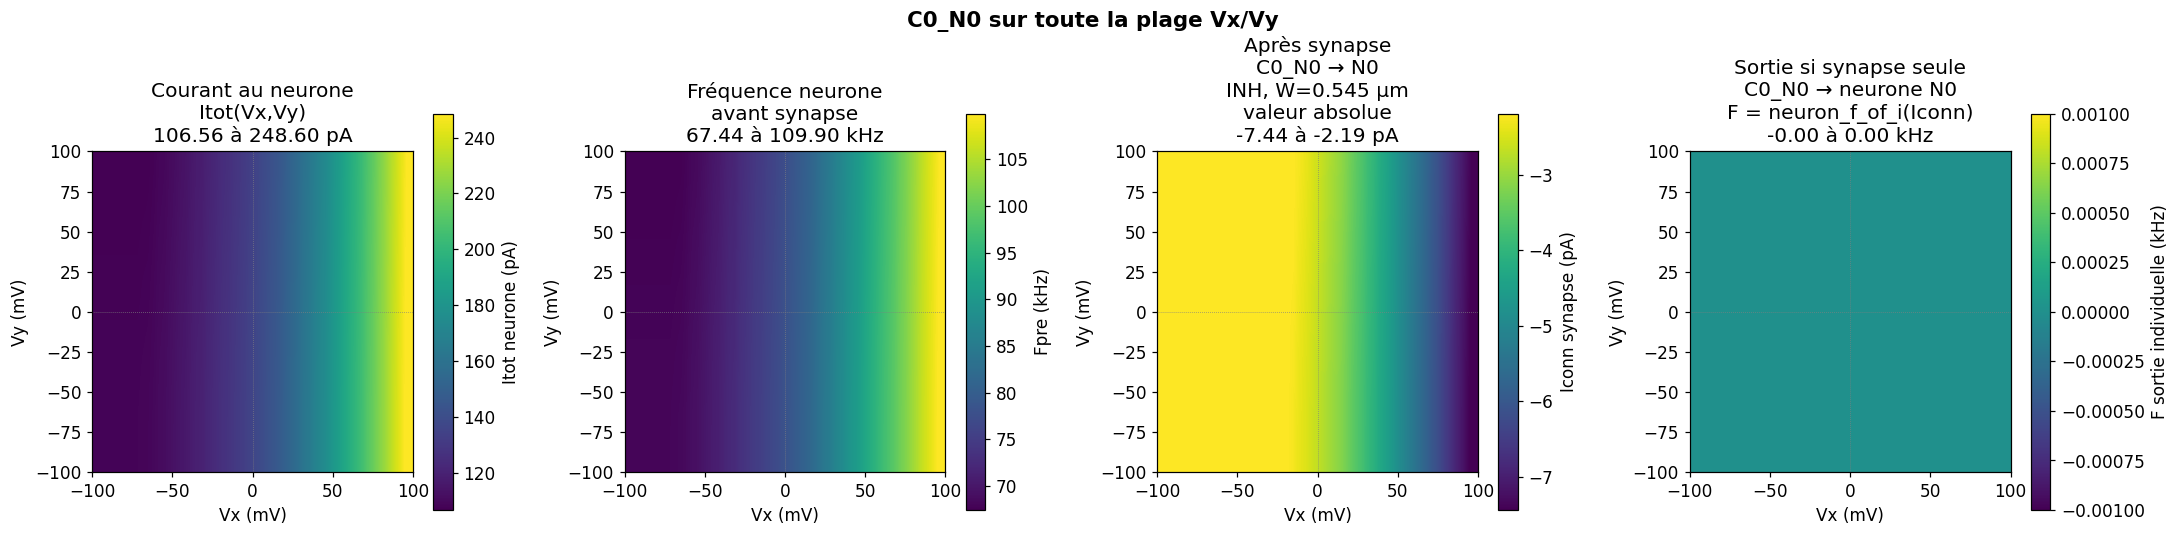

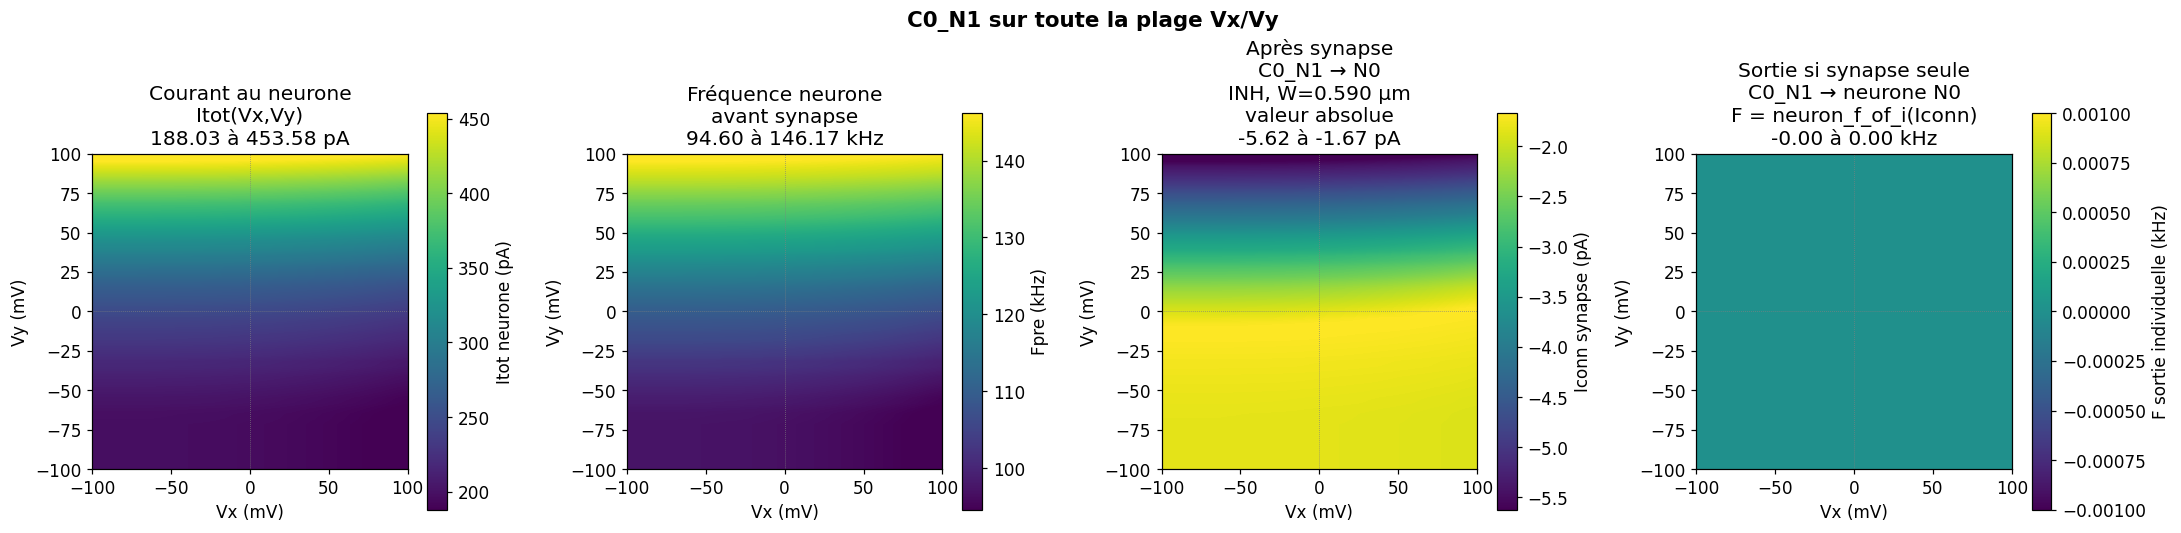

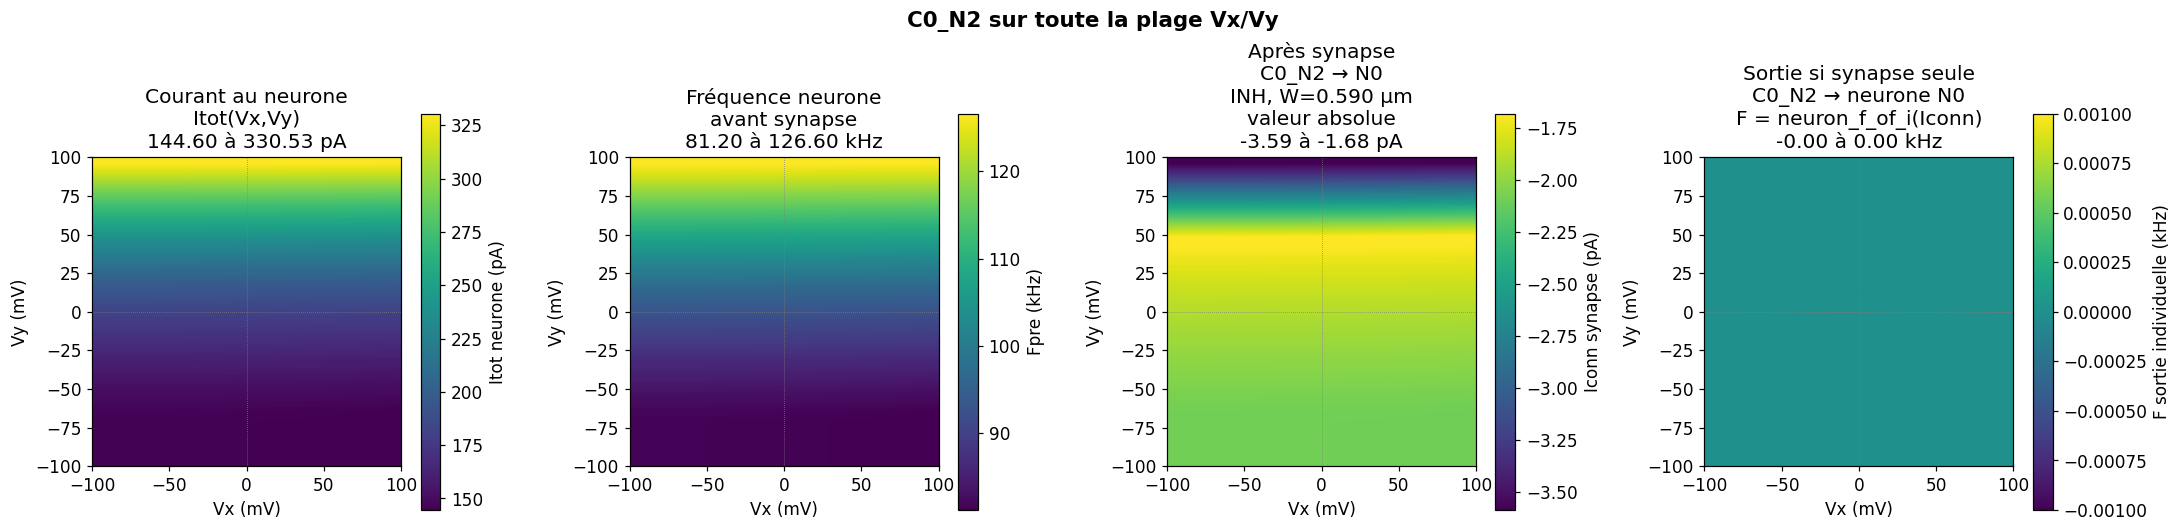

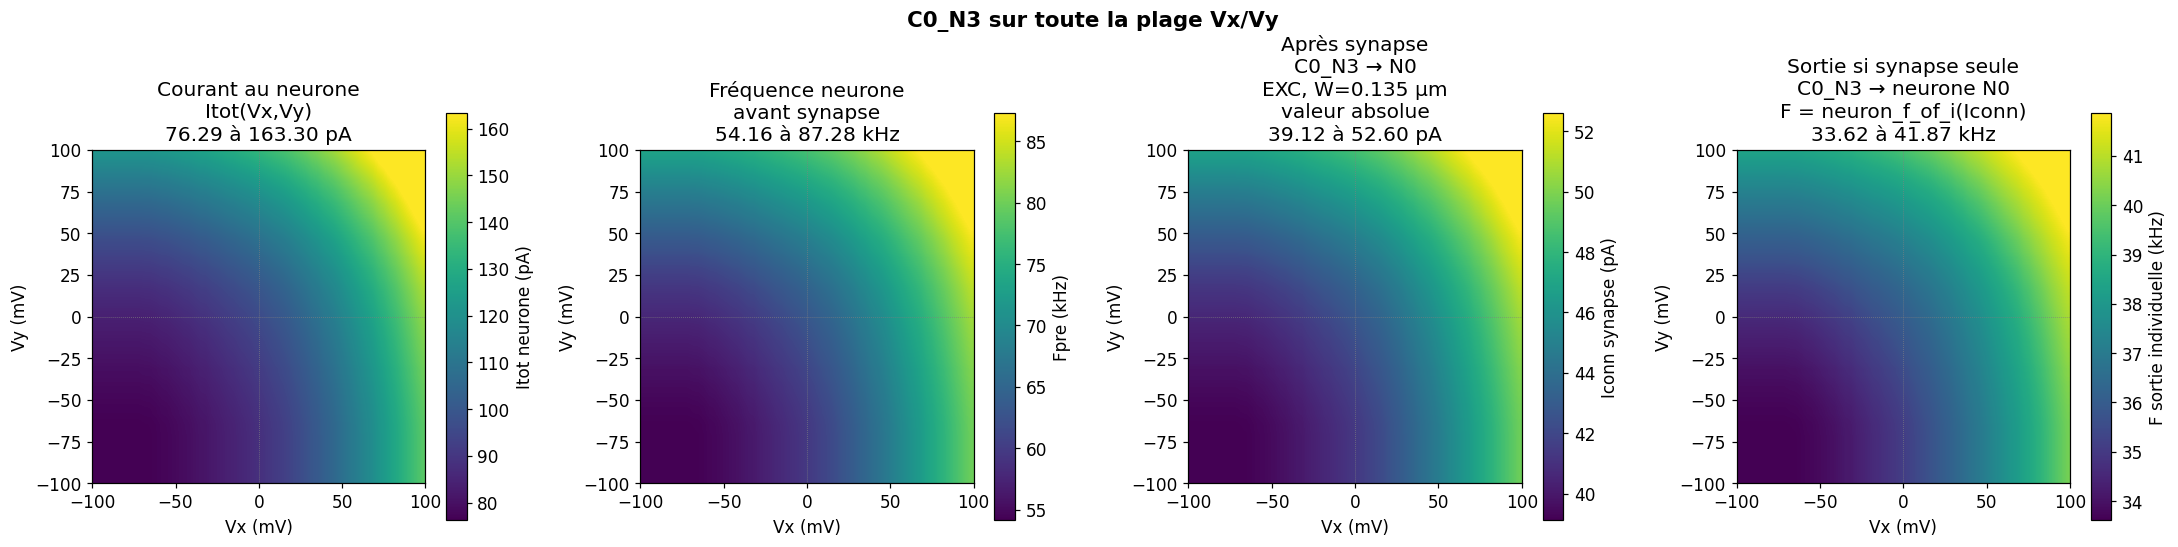

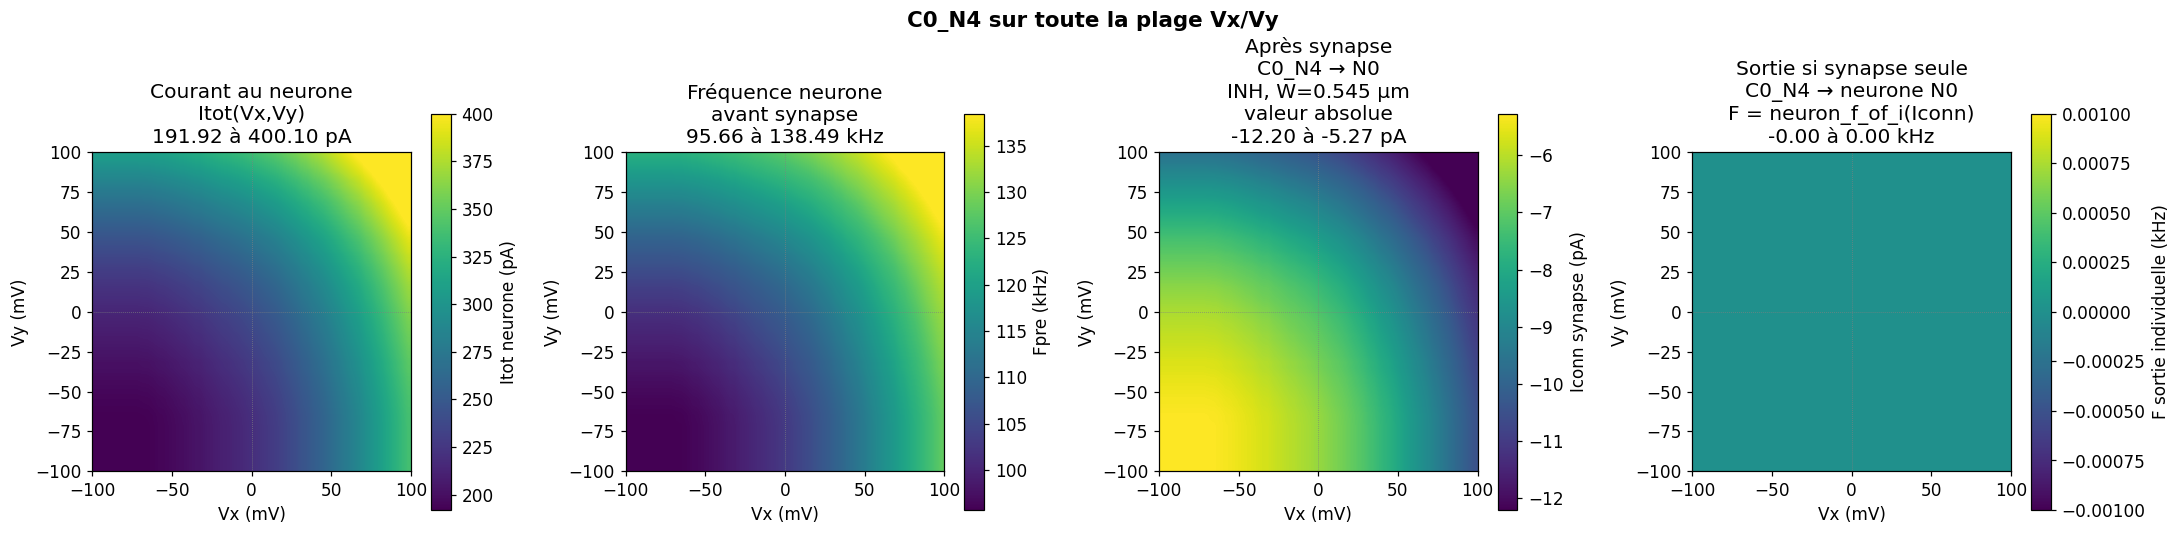

In [67]:
# ══════════════════════════════════════════════════════════════
# 14. Colormaps Vx/Vy : neurone caché -> synapse -> sortie propre
# ══════════════════════════════════════════════════════════════
#
# Pour toute la plage Vx,Vy :
#   1) Itot au neurone caché
#   2) Fpre du neurone caché
#   3) Iconn après chaque synapse de sortie
#   4) Fout_indiv si cette synapse alimente son propre neurone
#
# Important :
#   Fout_indiv[j,k] = neuron_f_of_i( Iconn[j,k] )
#   Donc ce n'est PAS la sortie globale sommée.
#   C'est la sortie obtenue si la synapse j->k était seule.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Résolution de la carte
N_GRID_LOCAL = 60

# True = montre Iconn - moyenne(Iconn)
# False = montre Iconn absolu
SHOW_RELATIVE_VARIATION = False

# Percentiles pour accentuer les variations
PERCENTILE_LOW = 2
PERCENTILE_HIGH = 98

# Plage normalisée [-1, 1]
x1_axis_local = np.linspace(-1, 1, N_GRID_LOCAL)
x2_axis_local = np.linspace(-1, 1, N_GRID_LOCAL)

# Conversion vers Vx, Vy réels
vx_axis = V_MIN + (x1_axis_local + 1.0) * (V_MAX - V_MIN) / 2.0
vy_axis = V_MIN + (x2_axis_local + 1.0) * (V_MAX - V_MIN) / 2.0

extent_mv = [
    vx_axis[0] * 1e3,
    vx_axis[-1] * 1e3,
    vy_axis[0] * 1e3,
    vy_axis[-1] * 1e3
]


def adaptive_norm_and_cmap(mat, center_zero=True):
    """
    Normalisation adaptée :
      - percentiles au lieu de min/max
      - colormap divergente si la carte traverse 0
      - colormap séquentielle sinon
    """

    vals = np.asarray(mat, float)
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        return plt.Normalize(vmin=-1, vmax=1), "viridis", -1, 1

    p_low, p_high = np.percentile(vals, [PERCENTILE_LOW, PERCENTILE_HIGH])

    if np.isclose(p_low, p_high):
        p_low = float(np.nanmin(vals))
        p_high = float(np.nanmax(vals))

    if np.isclose(p_low, p_high):
        delta = max(abs(p_low) * 0.05, 1e-3)
        p_low -= delta
        p_high += delta

    if center_zero and (p_low < 0 < p_high):
        vmax = max(abs(p_low), abs(p_high))
        norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
        cmap = "RdBu_r"
        return norm, cmap, -vmax, vmax

    norm = plt.Normalize(vmin=p_low, vmax=p_high)
    cmap = "viridis"
    return norm, cmap, p_low, p_high


def neuron_f_of_i_vectorized(I_A):
    """
    Version vectorisée de neuron_f_of_i.
    I_A peut être une matrice.
    Retourne F en Hz.
    """
    I_A = np.asarray(I_A, float)
    F = np.zeros_like(I_A, dtype=float)

    mask = I_A >= NEURON_I_RHEOBASE

    F[mask] = np.interp(
        I_A[mask],
        NEURON_I_AXIS,
        NEURON_F_AXIS,
        left=NEURON_F_AXIS[0],
        right=NEURON_F_AXIS[-1]
    )

    return F


def compute_hidden_to_output_maps(hidden_layer_index=0):
    """
    Calcule les cartes sur toute la plage Vx/Vy.

    Pour chaque point Vx,Vy :
      - Itot_maps[j]       = courant total reçu par le neurone caché j
      - Fpre_maps[j]       = fréquence générée par le neurone caché j
      - Isyn_maps[j,k]     = courant après la synapse j -> k
      - Fsynout_maps[j,k]  = fréquence si la synapse j -> k alimente son propre neurone
    """

    neuron_layer = hidden_layer_index + 1
    synapse_layer = hidden_layer_index + 1

    if synapse_layer >= len(layers_config):
        raise ValueError(
            "Cette couche n'a pas de synapses après elle. "
            "Choisis une couche cachée avant la sortie."
        )

    n_hidden = layers_config[hidden_layer_index]["signs"].shape[1]
    n_next = layers_config[synapse_layer]["signs"].shape[1]

    Itot_maps = np.zeros((n_hidden, N_GRID_LOCAL, N_GRID_LOCAL))
    Fpre_maps = np.zeros((n_hidden, N_GRID_LOCAL, N_GRID_LOCAL))
    Isyn_maps = np.zeros((n_hidden, n_next, N_GRID_LOCAL, N_GRID_LOCAL))
    Fsynout_maps = np.zeros((n_hidden, n_next, N_GRID_LOCAL, N_GRID_LOCAL))

    print("=" * 80)
    print(f"Calcul colormaps Vx/Vy pour couche cachée C{hidden_layer_index}")
    print(f"Grille : {N_GRID_LOCAL} x {N_GRID_LOCAL} = {N_GRID_LOCAL**2} points")
    print("=" * 80)

    for ii, vx in enumerate(vx_axis):
        for jj, vy in enumerate(vy_axis):

            Vin_loc = np.array([vx, vy])

            hF, hIc, hIt = propagate(Vin_loc, layers_config)

            # Courant reçu par les neurones cachés
            Itot_maps[:, ii, jj] = hIt[hidden_layer_index] * 1e12  # pA

            # Fréquence produite par les neurones cachés
            Fpre_maps[:, ii, jj] = hF[neuron_layer] / 1e3  # kHz

            # Courant après synapse de sortie
            Isyn_A = hIc[synapse_layer]  # A
            Isyn_maps[:, :, ii, jj] = Isyn_A * 1e12  # pA

            # Nouvelle partie :
            # fréquence si chaque synapse alimente son propre neurone
            Fsynout_Hz = neuron_f_of_i_vectorized(Isyn_A)
            Fsynout_maps[:, :, ii, jj] = Fsynout_Hz / 1e3  # kHz

    print("Terminé.")
    return Itot_maps, Fpre_maps, Isyn_maps, Fsynout_maps


def plot_maps_per_hidden_neuron(hidden_layer_index=0):
    """
    Affiche pour chaque neurone caché :
      1) Itot(Vx,Vy)
      2) Fpre(Vx,Vy)
      3) Iconn(Vx,Vy) après chaque synapse
      4) Fout_indiv(Vx,Vy) si cette synapse seule alimente son propre neurone
    """

    Itot_maps, Fpre_maps, Isyn_maps, Fsynout_maps = compute_hidden_to_output_maps(
        hidden_layer_index
    )

    synapse_layer = hidden_layer_index + 1

    signs_out = np.asarray(layers_config[synapse_layer]["signs"], int)
    widths_out = np.asarray(layers_config[synapse_layer]["widths"], float)

    n_hidden = Itot_maps.shape[0]
    n_next = Isyn_maps.shape[1]

    for j in range(n_hidden):

        # 2 cartes fixes + 2 cartes par synapse
        n_cols = 2 + 2 * n_next

        fig, axes = plt.subplots(
            1,
            n_cols,
            figsize=(5.0 * n_cols, 4.9),
            squeeze=False
        )

        axes = axes[0]

        fig.suptitle(
            f"C{hidden_layer_index}_N{j} sur toute la plage Vx/Vy",
            fontsize=14,
            fontweight="bold"
        )

        # ══════════════════════════════════════════════
        # 1) Itot au neurone caché
        # ══════════════════════════════════════════════
        ax = axes[0]
        mat = Itot_maps[j]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
            mat,
            center_zero=True
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        plt.colorbar(im, ax=ax, label="Itot neurone (pA)")
        ax.set_title(
            f"Courant au neurone\n"
            f"Itot(Vx,Vy)\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} pA"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

        # ══════════════════════════════════════════════
        # 2) Fpre du neurone caché
        # ══════════════════════════════════════════════
        ax = axes[1]
        mat = Fpre_maps[j]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
            mat,
            center_zero=False
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        plt.colorbar(im, ax=ax, label="Fpre (kHz)")
        ax.set_title(
            f"Fréquence neurone\n"
            f"avant synapse\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} kHz"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

        # ══════════════════════════════════════════════
        # 3) Pour chaque synapse : Iconn puis Fout_indiv
        # ══════════════════════════════════════════════
        for k in range(n_next):

            sign = signs_out[j, k]
            width = widths_out[j, k]

            if sign == 1:
                syn_name = "EXC"
            elif sign == -1:
                syn_name = "INH"
            else:
                syn_name = "OFF"

            # ──────────────────────────────────────────
            # 3a) Courant après synapse
            # ──────────────────────────────────────────
            ax = axes[2 + 2 * k]

            mat_abs = Isyn_maps[j, k]

            if SHOW_RELATIVE_VARIATION:
                mat = mat_abs - np.nanmean(mat_abs)
                colorbar_label = "Iconn - moyenne (pA)"
                title_mode = "variation relative"
                center_zero = True
            else:
                mat = mat_abs
                colorbar_label = "Iconn synapse (pA)"
                title_mode = "valeur absolue"
                center_zero = True

            norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
                mat,
                center_zero=center_zero
            )

            im = ax.imshow(
                mat.T,
                origin="lower",
                extent=extent_mv,
                aspect="equal",
                cmap=cmap,
                norm=norm,
                interpolation="bilinear"
            )

            plt.colorbar(im, ax=ax, label=colorbar_label)

            ax.set_title(
                f"Après synapse\n"
                f"C{hidden_layer_index}_N{j} → N{k}\n"
                f"{syn_name}, W={width:.3f} µm\n"
                f"{title_mode}\n"
                f"{vmin_show:.2f} à {vmax_show:.2f} pA"
            )

            ax.set_xlabel("Vx (mV)")
            ax.set_ylabel("Vy (mV)")
            ax.axhline(0, color="gray", lw=0.5, ls=":")
            ax.axvline(0, color="gray", lw=0.5, ls=":")

            # ──────────────────────────────────────────
            # 3b) Fréquence si cette synapse a son propre neurone
            # ──────────────────────────────────────────
            ax = axes[2 + 2 * k + 1]

            mat = Fsynout_maps[j, k]  # kHz

            norm, cmap, vmin_show, vmax_show = adaptive_norm_and_cmap(
                mat,
                center_zero=False
            )

            im = ax.imshow(
                mat.T,
                origin="lower",
                extent=extent_mv,
                aspect="equal",
                cmap=cmap,
                norm=norm,
                interpolation="bilinear"
            )

            plt.colorbar(im, ax=ax, label="F sortie individuelle (kHz)")

            ax.set_title(
                f"Sortie si synapse seule\n"
                f"C{hidden_layer_index}_N{j} → neurone N{k}\n"
                f"F = neuron_f_of_i(Iconn)\n"
                f"{vmin_show:.2f} à {vmax_show:.2f} kHz"
            )

            ax.set_xlabel("Vx (mV)")
            ax.set_ylabel("Vy (mV)")
            ax.axhline(0, color="gray", lw=0.5, ls=":")
            ax.axvline(0, color="gray", lw=0.5, ls=":")

        plt.tight_layout()
        plt.show()


# ══════════════════════════════════════════════════════════════
# LANCEMENT
# ══════════════════════════════════════════════════════════════

# Pour architecture [2, 8, 1] :
# C0 -> sortie
plot_maps_per_hidden_neuron(hidden_layer_index=0)

Accumulation choisie des courants
Couche cachée étudiée : C0
Neurone de sortie étudié : Out0
Ordre choisi : [3, 4, 1, 0, 2]
Grille : 60 x 60 = 3600 points
Terminé.


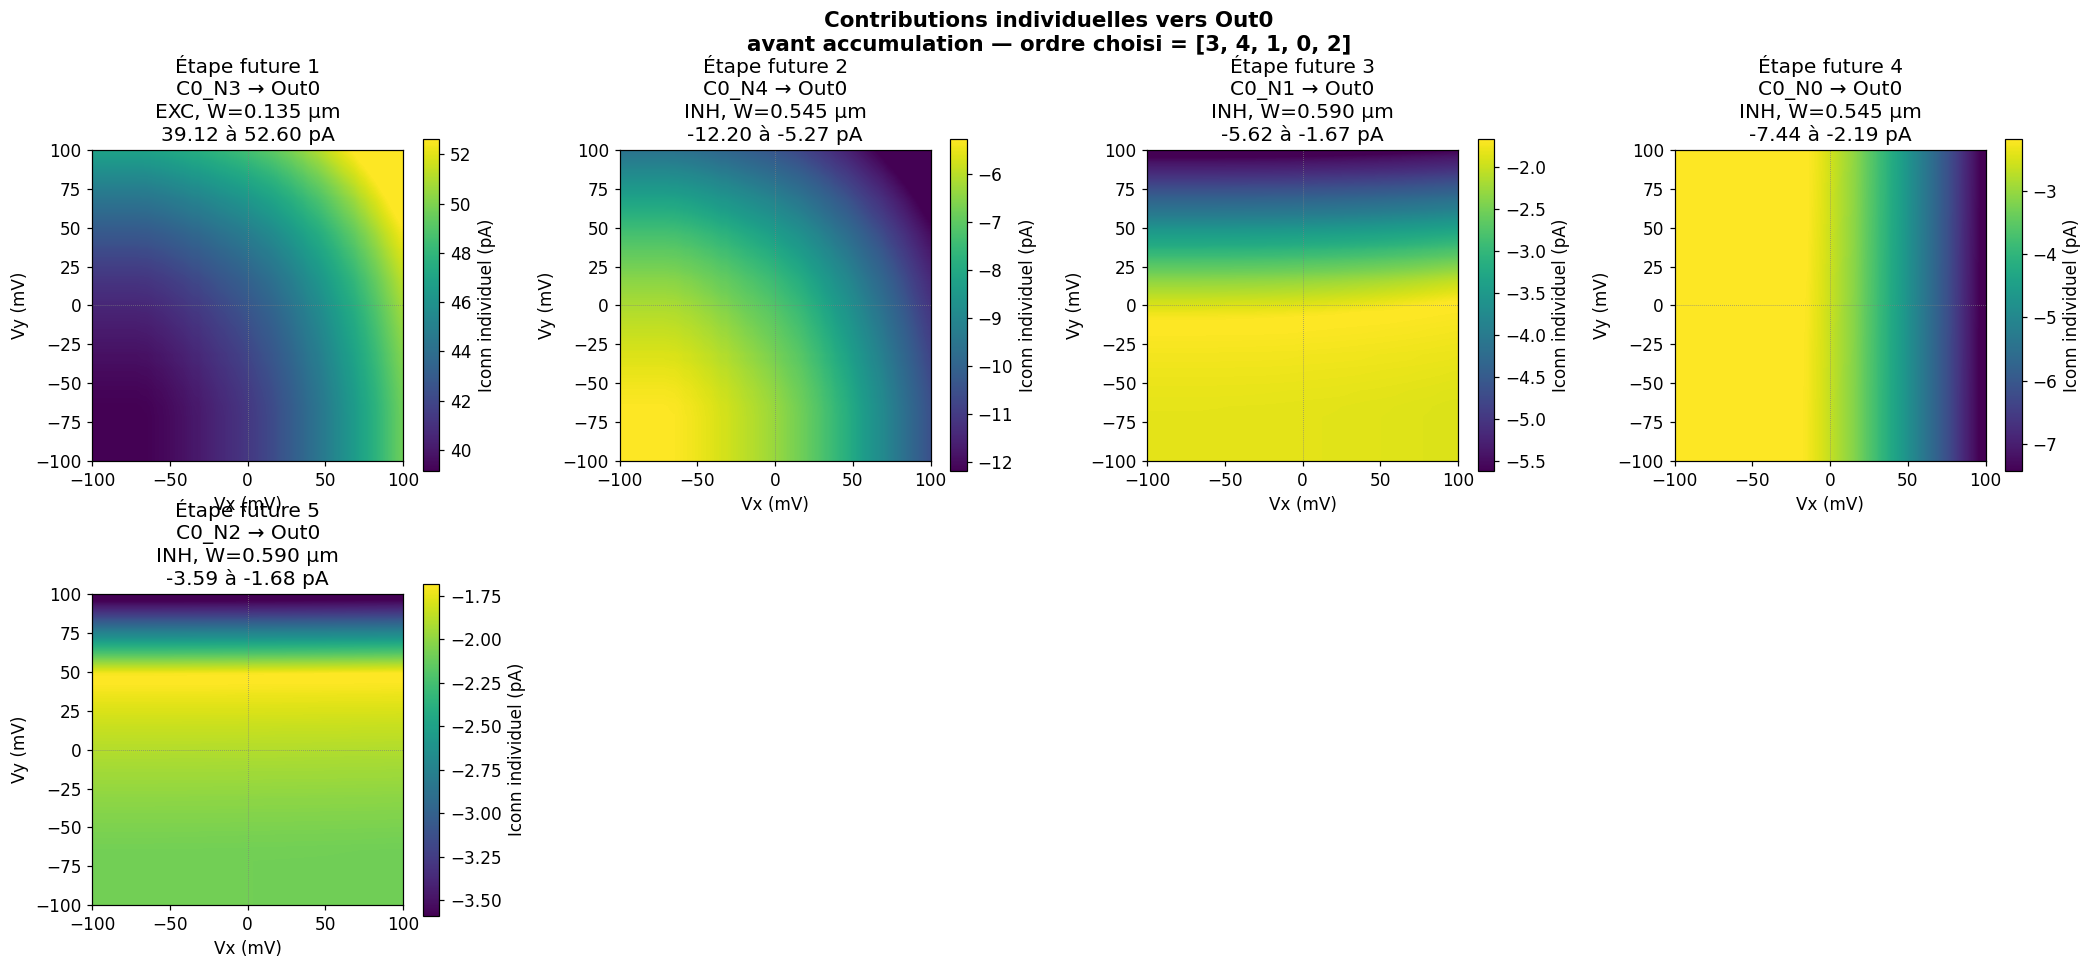

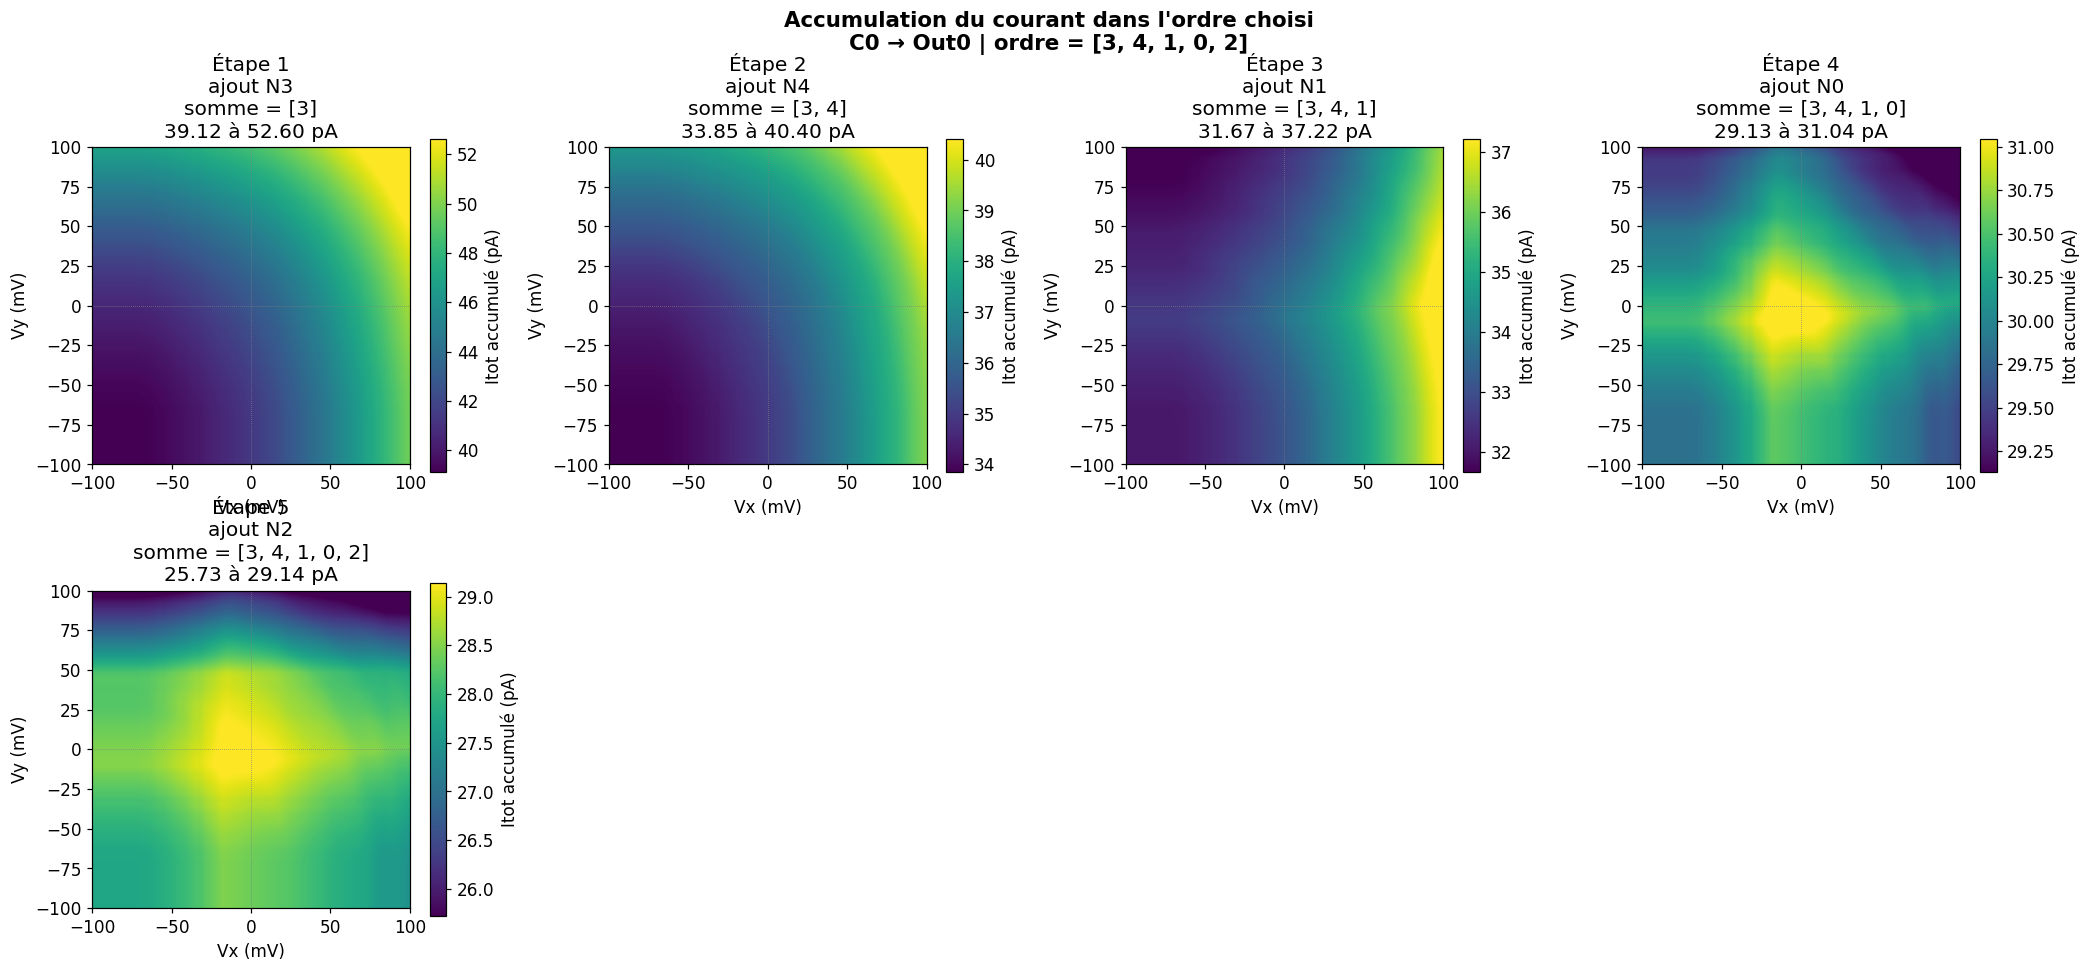

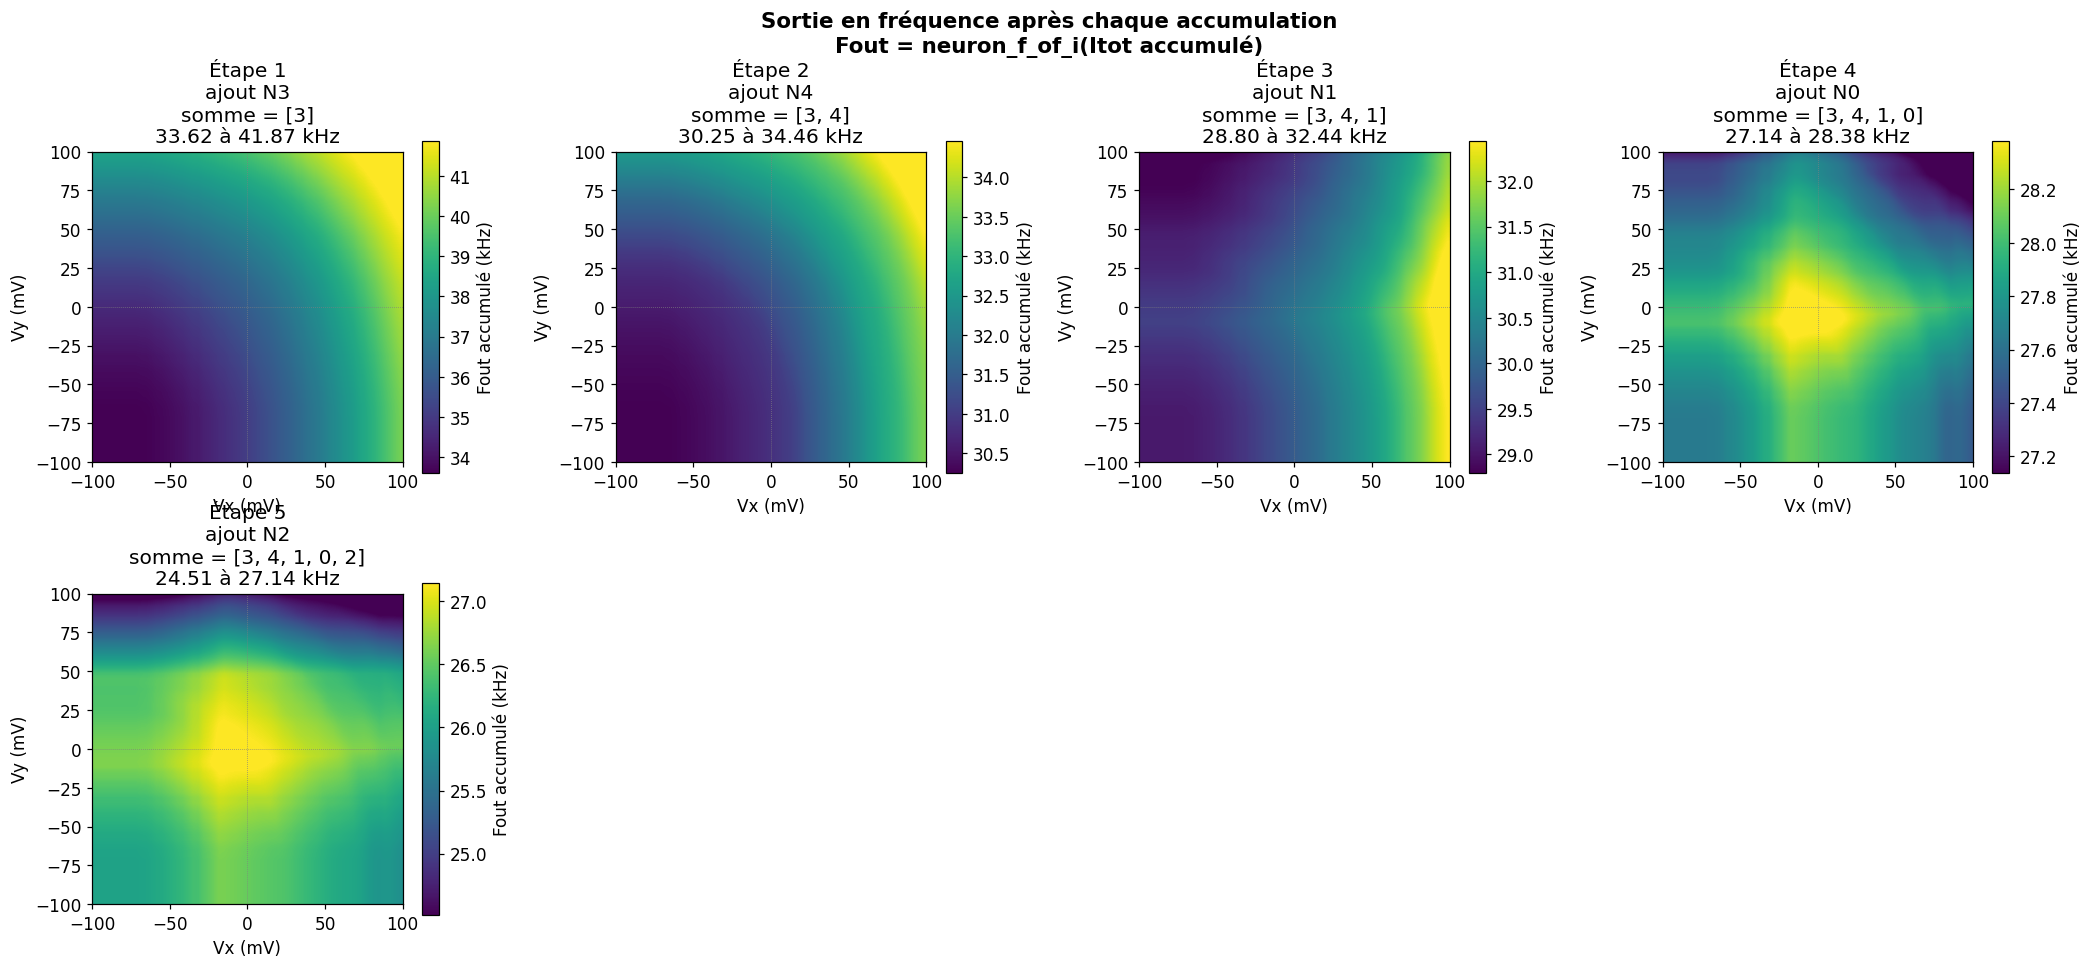

Résumé accumulation
Étape 01 | ajout N3 | Itot = [39.12, 55.35] pA | Fout = [33.62, 43.37] kHz
Étape 02 | ajout N4 | Itot = [33.85, 41.91] pA | Fout = [30.25, 35.53] kHz
Étape 03 | ajout N1 | Itot = [31.45, 37.91] pA | Fout = [28.64, 32.89] kHz
Étape 04 | ajout N0 | Itot = [28.78, 31.19] pA | Fout = [26.86, 28.47] kHz
Étape 05 | ajout N2 | Itot = [25.08, 29.26] pA | Fout = [24.04, 27.24] kHz


In [68]:
# ══════════════════════════════════════════════════════════════
# 15. Accumulation choisie des courants de synapses
#     + sortie en fréquence étape par étape
# ══════════════════════════════════════════════════════════════
#
# Objectif :
#   Tu choisis l'ordre des synapses.
#   Le code accumule les courants dans cet ordre.
#   À chaque étape :
#       Itot_accumulé = somme partielle des synapses
#       Fout_accumulé = neuron_f_of_i(Itot_accumulé)
#
# Exemple architecture [2, 8, 1] :
#   les synapses vers la sortie sont :
#       C0_N0 -> Out0
#       C0_N1 -> Out0
#       ...
#       C0_N7 -> Out0
#
# Tu peux tester plusieurs ordres :
#   ORDER = [0,1,2,3,4,5,6,7]
#   ORDER = [7,6,5,4,3,2,1,0]
#   ORDER = [3,1,7,0,2,5,4,6]

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


# ─────────────────────────────────────────────────────────────
# Paramètres utilisateur
# ─────────────────────────────────────────────────────────────

N_GRID_ACC = 60

# Couche cachée étudiée
# Pour architecture [2, 8, 1] : hidden_layer_index = 0
HIDDEN_LAYER_INDEX_ACC = 0

# Neurone de sortie étudié
# Pour architecture [2, 8, 1] : output_neuron_index = 0
OUTPUT_NEURON_INDEX_ACC = 0

# Ordre d'accumulation choisi par toi
# Chaque nombre correspond au neurone source dans la couche cachée.
ORDER_ACC = [3,4,1,0,2]

# Autres exemples :
# ORDER_ACC = [7, 6, 5, 4, 3, 2, 1, 0]
# ORDER_ACC = [3, 1, 7, 0, 2, 5, 4, 6]

# Si True : affiche aussi les contributions individuelles
SHOW_INDIVIDUAL_SYNAPSES = True


# ─────────────────────────────────────────────────────────────
# Grille Vx/Vy
# ─────────────────────────────────────────────────────────────

x1_axis_acc = np.linspace(-1, 1, N_GRID_ACC)
x2_axis_acc = np.linspace(-1, 1, N_GRID_ACC)

vx_axis_acc = V_MIN + (x1_axis_acc + 1.0) * (V_MAX - V_MIN) / 2.0
vy_axis_acc = V_MIN + (x2_axis_acc + 1.0) * (V_MAX - V_MIN) / 2.0

extent_mv_acc = [
    vx_axis_acc[0] * 1e3,
    vx_axis_acc[-1] * 1e3,
    vy_axis_acc[0] * 1e3,
    vy_axis_acc[-1] * 1e3
]


def adaptive_norm_acc(mat, center_zero=True, p_low=2, p_high=98):
    """
    Normalisation robuste pour voir les variations.
    Utilise des percentiles au lieu de min/max.
    """

    vals = np.asarray(mat, float)
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        return plt.Normalize(vmin=-1, vmax=1), "viridis", -1, 1

    vmin, vmax = np.percentile(vals, [p_low, p_high])

    if np.isclose(vmin, vmax):
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))

    if np.isclose(vmin, vmax):
        delta = max(abs(vmin) * 0.05, 1e-3)
        vmin -= delta
        vmax += delta

    if center_zero and (vmin < 0 < vmax):
        vmax_abs = max(abs(vmin), abs(vmax))
        norm = TwoSlopeNorm(vmin=-vmax_abs, vcenter=0.0, vmax=vmax_abs)
        return norm, "RdBu_r", -vmax_abs, vmax_abs

    return plt.Normalize(vmin=vmin, vmax=vmax), "viridis", vmin, vmax


def neuron_f_of_i_vectorized_acc(I_A):
    """
    Version vectorisée de neuron_f_of_i.
    Entrée : courant en A.
    Sortie : fréquence en Hz.
    """

    I_A = np.asarray(I_A, float)
    F = np.zeros_like(I_A, dtype=float)

    mask = I_A >= NEURON_I_RHEOBASE

    F[mask] = np.interp(
        I_A[mask],
        NEURON_I_AXIS,
        NEURON_F_AXIS,
        left=NEURON_F_AXIS[0],
        right=NEURON_F_AXIS[-1]
    )

    return F


def compute_ordered_accumulation_maps(
    hidden_layer_index=0,
    output_neuron_index=0,
    order=None
):
    """
    Calcule les cartes d'accumulation dans l'ordre choisi.

    Retour :
      I_individual_maps[s] :
          courant individuel de la synapse source s -> output

      I_acc_maps[t] :
          courant accumulé après t étapes

      F_acc_maps[t] :
          fréquence de sortie après t étapes
    """

    if order is None:
        raise ValueError("Tu dois donner un ordre, par exemple order=[0,1,2,3,4,5,6,7].")

    synapse_layer = hidden_layer_index + 1

    if synapse_layer >= len(layers_config):
        raise ValueError("Cette couche cachée n'a pas de synapse après elle.")

    signs_out = np.asarray(layers_config[synapse_layer]["signs"], int)
    widths_out = np.asarray(layers_config[synapse_layer]["widths"], float)

    n_sources = signs_out.shape[0]
    n_outputs = signs_out.shape[1]

    if output_neuron_index >= n_outputs:
        raise ValueError(f"output_neuron_index invalide. Cette couche a seulement {n_outputs} sortie(s).")

    for s in order:
        if s < 0 or s >= n_sources:
            raise ValueError(f"Index {s} invalide dans ORDER_ACC. Il faut entre 0 et {n_sources-1}.")

    I_individual_maps = np.zeros((n_sources, N_GRID_ACC, N_GRID_ACC))

    print("=" * 80)
    print("Accumulation choisie des courants")
    print(f"Couche cachée étudiée : C{hidden_layer_index}")
    print(f"Neurone de sortie étudié : Out{output_neuron_index}")
    print(f"Ordre choisi : {order}")
    print(f"Grille : {N_GRID_ACC} x {N_GRID_ACC} = {N_GRID_ACC**2} points")
    print("=" * 80)

    # Calcul des contributions individuelles sur toute la plage Vx/Vy
    for ii, vx in enumerate(vx_axis_acc):
        for jj, vy in enumerate(vy_axis_acc):

            Vin_loc = np.array([vx, vy])
            hF, hIc, hIt = propagate(Vin_loc, layers_config)

            # hIc[synapse_layer] shape = (n_sources, n_outputs)
            Iconn_out = hIc[synapse_layer][:, output_neuron_index]  # A

            I_individual_maps[:, ii, jj] = Iconn_out * 1e12  # pA

    # Accumulation dans l'ordre choisi
    n_steps = len(order)

    I_acc_maps = np.zeros((n_steps, N_GRID_ACC, N_GRID_ACC))
    F_acc_maps = np.zeros((n_steps, N_GRID_ACC, N_GRID_ACC))

    I_running = np.zeros((N_GRID_ACC, N_GRID_ACC))

    for t, source_idx in enumerate(order):
        I_running = I_running + I_individual_maps[source_idx]

        I_acc_maps[t] = I_running

        # Conversion pA -> A avant neuron_f_of_i
        F_acc_maps[t] = neuron_f_of_i_vectorized_acc(I_running * 1e-12) / 1e3  # kHz

    print("Terminé.")
    return I_individual_maps, I_acc_maps, F_acc_maps, signs_out, widths_out


def plot_ordered_accumulation_maps(
    hidden_layer_index=0,
    output_neuron_index=0,
    order=None
):
    """
    Affiche :
      - les contributions individuelles optionnelles
      - l'accumulation du courant étape par étape
      - la fréquence de sortie étape par étape
    """

    I_individual_maps, I_acc_maps, F_acc_maps, signs_out, widths_out = compute_ordered_accumulation_maps(
        hidden_layer_index=hidden_layer_index,
        output_neuron_index=output_neuron_index,
        order=order
    )

    n_steps = len(order)

    # ══════════════════════════════════════════════════════════
    # Figure A : contributions individuelles des synapses
    # ══════════════════════════════════════════════════════════
    if SHOW_INDIVIDUAL_SYNAPSES:

        n_cols = min(4, len(order))
        n_rows = int(np.ceil(len(order) / n_cols))

        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(4.8 * n_cols, 4.4 * n_rows),
            squeeze=False
        )

        fig.suptitle(
            f"Contributions individuelles vers Out{output_neuron_index}\n"
            f"avant accumulation — ordre choisi = {order}",
            fontsize=14,
            fontweight="bold"
        )

        for idx_plot, source_idx in enumerate(order):
            r = idx_plot // n_cols
            c = idx_plot % n_cols
            ax = axes[r, c]

            mat = I_individual_maps[source_idx]

            norm, cmap, vmin_show, vmax_show = adaptive_norm_acc(
                mat,
                center_zero=True
            )

            im = ax.imshow(
                mat.T,
                origin="lower",
                extent=extent_mv_acc,
                aspect="equal",
                cmap=cmap,
                norm=norm,
                interpolation="bilinear"
            )

            sign = signs_out[source_idx, output_neuron_index]
            width = widths_out[source_idx, output_neuron_index]

            if sign == 1:
                syn_name = "EXC"
            elif sign == -1:
                syn_name = "INH"
            else:
                syn_name = "OFF"

            plt.colorbar(im, ax=ax, label="Iconn individuel (pA)")
            ax.set_title(
                f"Étape future {idx_plot+1}\n"
                f"C{hidden_layer_index}_N{source_idx} → Out{output_neuron_index}\n"
                f"{syn_name}, W={width:.3f} µm\n"
                f"{vmin_show:.2f} à {vmax_show:.2f} pA"
            )
            ax.set_xlabel("Vx (mV)")
            ax.set_ylabel("Vy (mV)")
            ax.axhline(0, color="gray", lw=0.5, ls=":")
            ax.axvline(0, color="gray", lw=0.5, ls=":")

        # Cacher les axes vides
        for idx_empty in range(len(order), n_rows * n_cols):
            r = idx_empty // n_cols
            c = idx_empty % n_cols
            axes[r, c].axis("off")

        plt.tight_layout()
        plt.show()

    # ══════════════════════════════════════════════════════════
    # Figure B : courant accumulé étape par étape
    # ══════════════════════════════════════════════════════════

    n_cols = min(4, n_steps)
    n_rows = int(np.ceil(n_steps / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.8 * n_cols, 4.4 * n_rows),
        squeeze=False
    )

    fig.suptitle(
        f"Accumulation du courant dans l'ordre choisi\n"
        f"C{hidden_layer_index} → Out{output_neuron_index} | ordre = {order}",
        fontsize=14,
        fontweight="bold"
    )

    for t, source_idx in enumerate(order):
        r = t // n_cols
        c = t % n_cols
        ax = axes[r, c]

        mat = I_acc_maps[t]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_acc(
            mat,
            center_zero=True
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv_acc,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        partial_order = order[:t+1]

        plt.colorbar(im, ax=ax, label="Itot accumulé (pA)")
        ax.set_title(
            f"Étape {t+1}\n"
            f"ajout N{source_idx}\n"
            f"somme = {partial_order}\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} pA"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

    for idx_empty in range(n_steps, n_rows * n_cols):
        r = idx_empty // n_cols
        c = idx_empty % n_cols
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()

    # ══════════════════════════════════════════════════════════
    # Figure C : fréquence de sortie après accumulation
    # ══════════════════════════════════════════════════════════

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.8 * n_cols, 4.4 * n_rows),
        squeeze=False
    )

    fig.suptitle(
        f"Sortie en fréquence après chaque accumulation\n"
        f"Fout = neuron_f_of_i(Itot accumulé)",
        fontsize=14,
        fontweight="bold"
    )

    for t, source_idx in enumerate(order):
        r = t // n_cols
        c = t % n_cols
        ax = axes[r, c]

        mat = F_acc_maps[t]

        norm, cmap, vmin_show, vmax_show = adaptive_norm_acc(
            mat,
            center_zero=False
        )

        im = ax.imshow(
            mat.T,
            origin="lower",
            extent=extent_mv_acc,
            aspect="equal",
            cmap=cmap,
            norm=norm,
            interpolation="bilinear"
        )

        partial_order = order[:t+1]

        plt.colorbar(im, ax=ax, label="Fout accumulé (kHz)")
        ax.set_title(
            f"Étape {t+1}\n"
            f"ajout N{source_idx}\n"
            f"somme = {partial_order}\n"
            f"{vmin_show:.2f} à {vmax_show:.2f} kHz"
        )
        ax.set_xlabel("Vx (mV)")
        ax.set_ylabel("Vy (mV)")
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.axvline(0, color="gray", lw=0.5, ls=":")

    for idx_empty in range(n_steps, n_rows * n_cols):
        r = idx_empty // n_cols
        c = idx_empty % n_cols
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()

    # ══════════════════════════════════════════════════════════
    # Résumé numérique simple
    # ══════════════════════════════════════════════════════════

    print("=" * 80)
    print("Résumé accumulation")
    print("=" * 80)

    for t, source_idx in enumerate(order):
        Imin = np.min(I_acc_maps[t])
        Imax = np.max(I_acc_maps[t])
        Fmin = np.min(F_acc_maps[t])
        Fmax = np.max(F_acc_maps[t])

        print(
            f"Étape {t+1:02d} | ajout N{source_idx} | "
            f"Itot = [{Imin:.2f}, {Imax:.2f}] pA | "
            f"Fout = [{Fmin:.2f}, {Fmax:.2f}] kHz"
        )

    print("=" * 80)


# ══════════════════════════════════════════════════════════════
# LANCEMENT
# ══════════════════════════════════════════════════════════════

plot_ordered_accumulation_maps(
    hidden_layer_index=HIDDEN_LAYER_INDEX_ACC,
    output_neuron_index=OUTPUT_NEURON_INDEX_ACC,
    order=ORDER_ACC
)

In [69]:
# ══════════════════════════════════════════════════════════════
# 16. CADENCE — Accumulation choisie des courants C0 -> sortie
#     Version lissée en map continue, non pixélisée
# ══════════════════════════════════════════════════════════════
#
# Utilise :
#   - GRID_POINTS avec pt["cad_c0"]
#   - VIN_GRID = [-0.100, -0.050, 0.000, 0.050, 0.100]
#   - layers_config
#   - layer_forward(...)
#   - NEURON_I_AXIS, NEURON_F_AXIS, NEURON_I_RHEOBASE
#
# But :
#   1) prendre les fréquences Cadence mesurées de C0
#   2) calculer les courants C0_Nj -> sortie
#   3) accumuler ces courants dans l'ordre choisi
#   4) convertir l'accumulation en fréquence
#   5) afficher tout en maps lisses

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.interpolate import RBFInterpolator


# ══════════════════════════════════════════════════════════════
# PARAMÈTRES UTILISATEUR
# ══════════════════════════════════════════════════════════════

# Pour architecture [2, 8, 1]
CAD_HIDDEN_LAYER_INDEX_ACC = 0
CAD_OUTPUT_NEURON_INDEX_ACC = 0

# Ordre d'accumulation choisi
CAD_ORDER_ACC = [4,6,0,1,2,7,3,5]

# Exemples :
# CAD_ORDER_ACC = [7, 6, 5, 4, 3, 2, 1, 0]
# CAD_ORDER_ACC = [3, 1, 7, 0, 2, 5, 4, 6]

# Afficher aussi les contributions individuelles avant accumulation
SHOW_CAD_INDIVIDUAL_SYNAPSES = True

# Résolution de la map lissée
N_CAD_SMOOTH = 90

# Lissage RBF :
# 0.0 = passe très proche des points
# 0.2 / 0.5 = plus doux
CAD_RBF_SMOOTHING = 0.2

# Afficher les 25 vrais points Cadence sur les maps
SHOW_CAD_POINTS = True

# Afficher les valeurs numériques sur les 25 points
# False conseillé pour avoir une map propre
SHOW_CAD_VALUES = False

# Percentiles pour éviter qu'un point extrême écrase la colormap
CAD_PERCENTILE_LOW = 2
CAD_PERCENTILE_HIGH = 98


# ══════════════════════════════════════════════════════════════
# AXES CADENCE
# ══════════════════════════════════════════════════════════════

cad_vx_axis_mv = np.array([v * 1e3 for v in VIN_GRID])
cad_vy_axis_mv = np.array([v * 1e3 for v in VIN_GRID])

cad_extent_mv = [
    cad_vx_axis_mv[0],
    cad_vx_axis_mv[-1],
    cad_vy_axis_mv[0],
    cad_vy_axis_mv[-1]
]

cad_x_smooth = np.linspace(cad_vx_axis_mv[0], cad_vx_axis_mv[-1], N_CAD_SMOOTH)
cad_y_smooth = np.linspace(cad_vy_axis_mv[0], cad_vy_axis_mv[-1], N_CAD_SMOOTH)

CAD_XG, CAD_YG = np.meshgrid(cad_x_smooth, cad_y_smooth, indexing="xy")
CAD_QUERY = np.column_stack([CAD_XG.ravel(), CAD_YG.ravel()])

CAD_X5, CAD_Y5 = np.meshgrid(cad_vx_axis_mv, cad_vy_axis_mv, indexing="xy")
CAD_PTS_5x5 = np.column_stack([CAD_X5.ravel(), CAD_Y5.ravel()])


# ══════════════════════════════════════════════════════════════
# OUTILS
# ══════════════════════════════════════════════════════════════

def adaptive_norm_cad_acc(mat, center_zero=True):
    """
    Normalisation robuste :
      - utilise les percentiles
      - centre à 0 si la carte traverse 0
      - sinon colormap séquentielle
    """

    vals = np.asarray(mat, float)
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        return plt.Normalize(vmin=-1, vmax=1), "viridis", -1, 1

    vmin, vmax = np.percentile(
        vals,
        [CAD_PERCENTILE_LOW, CAD_PERCENTILE_HIGH]
    )

    if np.isclose(vmin, vmax):
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))

    if np.isclose(vmin, vmax):
        delta = max(abs(vmin) * 0.05, 1e-3)
        vmin -= delta
        vmax += delta

    if center_zero and (vmin < 0 < vmax):
        vmax_abs = max(abs(vmin), abs(vmax))
        norm = TwoSlopeNorm(vmin=-vmax_abs, vcenter=0.0, vmax=vmax_abs)
        cmap = "RdBu_r"
        return norm, cmap, -vmax_abs, vmax_abs

    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap = "viridis"
    return norm, cmap, vmin, vmax


def neuron_f_of_i_vectorized_cad_acc(I_A):
    """
    Version vectorisée de neuron_f_of_i.

    Entrée :
        I_A : courant en A

    Sortie :
        F : fréquence en Hz

    Même logique que ton notebook :
        si I < rheobase -> 0 Hz
        sinon interpolation sur NEURON_I_AXIS / NEURON_F_AXIS
    """

    I_A = np.asarray(I_A, float)
    F = np.zeros_like(I_A, dtype=float)

    mask = I_A >= NEURON_I_RHEOBASE

    F[mask] = np.interp(
        I_A[mask],
        NEURON_I_AXIS,
        NEURON_F_AXIS,
        left=NEURON_F_AXIS[0],
        right=NEURON_F_AXIS[-1]
    )

    return F


def smooth_cadence_map(mat_5x5, smoothing=CAD_RBF_SMOOTHING):
    """
    Transforme une carte Cadence 5x5 en carte lisse N_CAD_SMOOTH x N_CAD_SMOOTH.

    Entrée :
        mat_5x5 : matrice 5x5

    Sortie :
        mat_smooth : matrice lissée
    """

    values = np.asarray(mat_5x5, float).ravel()

    rbf = RBFInterpolator(
        CAD_PTS_5x5,
        values,
        kernel="thin_plate_spline",
        smoothing=smoothing
    )

    smooth_values = rbf(CAD_QUERY)

    return smooth_values.reshape(N_CAD_SMOOTH, N_CAD_SMOOTH)


def imshow_smooth_cadence(
    ax,
    mat_5x5,
    center_zero,
    title,
    cbar_label,
    show_points=SHOW_CAD_POINTS,
    show_values=SHOW_CAD_VALUES
):
    """
    Affiche une carte Cadence 5x5 comme une map lisse.
    """

    mat_smooth = smooth_cadence_map(mat_5x5)

    norm, cmap, vmin_show, vmax_show = adaptive_norm_cad_acc(
        mat_smooth,
        center_zero=center_zero
    )

    im = ax.imshow(
        mat_smooth,
        origin="lower",
        extent=cad_extent_mv,
        aspect="equal",
        cmap=cmap,
        norm=norm,
        interpolation="bilinear"
    )

    plt.colorbar(im, ax=ax, label=cbar_label)

    if show_points:
        ax.scatter(
            CAD_PTS_5x5[:, 0],
            CAD_PTS_5x5[:, 1],
            s=18,
            c="black",
            marker="o",
            alpha=0.70,
            linewidths=0.0,
            label="points Cadence"
        )

    if show_values:
        vmax_txt = max(np.nanmax(np.abs(mat_5x5)), 1e-9)

        for rr in range(5):
            for cc in range(5):
                val = mat_5x5[rr, cc]
                ax.text(
                    cad_vx_axis_mv[cc],
                    cad_vy_axis_mv[rr],
                    f"{val:.1f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if abs(val) > 0.55 * vmax_txt else "black"
                )

    ax.set_title(
        title + f"\nrange affiché : {vmin_show:.2f} à {vmax_show:.2f}"
    )
    ax.set_xlabel("Vin1 / Vx (mV)")
    ax.set_ylabel("Vin2 / Vy (mV)")
    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    if show_points:
        ax.legend(fontsize=7, loc="upper right", framealpha=0.75)


# ══════════════════════════════════════════════════════════════
# CALCUL CADENCE : CONTRIBUTIONS + ACCUMULATION
# ══════════════════════════════════════════════════════════════

def compute_cadence_ordered_accumulation_maps_smooth(
    hidden_layer_index=0,
    output_neuron_index=0,
    order=None
):
    """
    Version Cadence.

    Utilise :
        pt["cad_c0"]

    Calcule :
        I_individual_maps[s] :
            courant individuel C0_Ns -> Out

        I_acc_maps[t] :
            courant accumulé après t étapes

        F_acc_maps[t] :
            fréquence de sortie après t étapes
    """

    if order is None:
        raise ValueError("Tu dois donner un ordre, par exemple order=[0,1,2,3,4,5,6,7].")

    assert hidden_layer_index == 0, (
        "Cette version Cadence utilise pt['cad_c0'], donc hidden_layer_index doit être 0."
    )

    synapse_layer = hidden_layer_index + 1

    if synapse_layer >= len(layers_config):
        raise ValueError("Cette couche cachée n'a pas de synapse après elle.")

    cfg_out = layers_config[synapse_layer]

    signs_out = np.asarray(cfg_out["signs"], int)
    widths_out = np.asarray(cfg_out["widths"], float)

    n_sources = signs_out.shape[0]
    n_outputs = signs_out.shape[1]

    if output_neuron_index >= n_outputs:
        raise ValueError(
            f"output_neuron_index invalide. Cette couche a seulement {n_outputs} sortie(s)."
        )

    for s in order:
        if s < 0 or s >= n_sources:
            raise ValueError(
                f"Index {s} invalide dans CAD_ORDER_ACC. Il faut entre 0 et {n_sources-1}."
            )

    N_CAD = 5
    I_individual_maps = np.zeros((n_sources, N_CAD, N_CAD))

    print("=" * 90)
    print("CADENCE — Accumulation choisie des courants avec maps lisses")
    print("Source utilisée : fréquences Cadence pt['cad_c0']")
    print(f"Couche étudiée : C{hidden_layer_index}")
    print(f"Sortie étudiée : Out{output_neuron_index}")
    print(f"Ordre choisi : {order}")
    print("=" * 90)

    # ─────────────────────────────────────────────────────────
    # Contributions individuelles sur les 25 points Cadence
    # ─────────────────────────────────────────────────────────
    for idx_pt, pt in enumerate(GRID_POINTS):

        r = idx_pt // 5   # ligne Vy
        c = idx_pt % 5    # colonne Vx

        C0_cad = np.asarray(pt["cad_c0"], float)

        # C0 Cadence -> synapses -> sortie
        Fout_vec, Iconn_mat, Itot_vec = layer_forward(
            C0_cad,
            signs_out,
            widths_out
        )

        Iconn_out = Iconn_mat[:, output_neuron_index]  # A

        I_individual_maps[:, r, c] = Iconn_out * 1e12  # pA

    # ─────────────────────────────────────────────────────────
    # Accumulation selon l'ordre choisi
    # ─────────────────────────────────────────────────────────
    n_steps = len(order)

    I_acc_maps = np.zeros((n_steps, N_CAD, N_CAD))
    F_acc_maps = np.zeros((n_steps, N_CAD, N_CAD))

    I_running = np.zeros((N_CAD, N_CAD))

    for t, source_idx in enumerate(order):

        I_running = I_running + I_individual_maps[source_idx]

        I_acc_maps[t] = I_running

        # pA -> A puis courant -> fréquence
        F_acc_maps[t] = neuron_f_of_i_vectorized_cad_acc(
            I_running * 1e-12
        ) / 1e3  # kHz

    print("Terminé.")
    return I_individual_maps, I_acc_maps, F_acc_maps, signs_out, widths_out


# ══════════════════════════════════════════════════════════════
# AFFICHAGE
# ══════════════════════════════════════════════════════════════

def plot_cadence_ordered_accumulation_maps_smooth(
    hidden_layer_index=0,
    output_neuron_index=0,
    order=None
):
    """
    Affiche en maps lisses :
      1) contributions individuelles Cadence C0_Nj -> Out
      2) accumulation du courant étape par étape
      3) fréquence de sortie étape par étape
    """

    I_individual_maps, I_acc_maps, F_acc_maps, signs_out, widths_out = (
        compute_cadence_ordered_accumulation_maps_smooth(
            hidden_layer_index=hidden_layer_index,
            output_neuron_index=output_neuron_index,
            order=order
        )
    )

    n_steps = len(order)

    # ══════════════════════════════════════════════════════════
    # Figure A : contributions individuelles
    # ══════════════════════════════════════════════════════════

    if SHOW_CAD_INDIVIDUAL_SYNAPSES:

        n_cols = min(4, len(order))
        n_rows = int(np.ceil(len(order) / n_cols))

        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(4.9 * n_cols, 4.6 * n_rows),
            squeeze=False
        )

        fig.suptitle(
            f"CADENCE lissé — Contributions individuelles C0 -> Out{output_neuron_index}\n"
            f"ordre choisi = {order}",
            fontsize=14,
            fontweight="bold"
        )

        for idx_plot, source_idx in enumerate(order):

            rr = idx_plot // n_cols
            cc = idx_plot % n_cols
            ax = axes[rr, cc]

            mat = I_individual_maps[source_idx]

            sign = signs_out[source_idx, output_neuron_index]
            width = widths_out[source_idx, output_neuron_index]

            if sign == 1:
                syn_name = "EXC"
            elif sign == -1:
                syn_name = "INH"
            else:
                syn_name = "OFF"

            title = (
                f"Synapse C0_N{source_idx} -> Out{output_neuron_index}\n"
                f"{syn_name}, W={width:.3f} µm"
            )

            imshow_smooth_cadence(
                ax=ax,
                mat_5x5=mat,
                center_zero=True,
                title=title,
                cbar_label="Iconn individuel (pA)"
            )

        for idx_empty in range(len(order), n_rows * n_cols):
            rr = idx_empty // n_cols
            cc = idx_empty % n_cols
            axes[rr, cc].axis("off")

        plt.tight_layout()
        plt.show()

    # ══════════════════════════════════════════════════════════
    # Figure B : courant accumulé
    # ══════════════════════════════════════════════════════════

    n_cols = min(4, n_steps)
    n_rows = int(np.ceil(n_steps / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.9 * n_cols, 4.6 * n_rows),
        squeeze=False
    )

    fig.suptitle(
        f"CADENCE lissé — Accumulation du courant C0 -> Out{output_neuron_index}\n"
        f"ordre = {order}",
        fontsize=14,
        fontweight="bold"
    )

    for t, source_idx in enumerate(order):

        rr = t // n_cols
        cc = t % n_cols
        ax = axes[rr, cc]

        mat = I_acc_maps[t]
        partial_order = order[:t + 1]

        title = (
            f"Étape {t+1} : ajout C0_N{source_idx}\n"
            f"somme = {partial_order}"
        )

        imshow_smooth_cadence(
            ax=ax,
            mat_5x5=mat,
            center_zero=True,
            title=title,
            cbar_label="Itot accumulé (pA)"
        )

    for idx_empty in range(n_steps, n_rows * n_cols):
        rr = idx_empty // n_cols
        cc = idx_empty % n_cols
        axes[rr, cc].axis("off")

    plt.tight_layout()
    plt.show()

    # ══════════════════════════════════════════════════════════
    # Figure C : fréquence de sortie après accumulation
    # ══════════════════════════════════════════════════════════

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(4.9 * n_cols, 4.6 * n_rows),
        squeeze=False
    )

    fig.suptitle(
        "CADENCE lissé — Sortie en fréquence après chaque accumulation\n"
        "Fout = neuron_f_of_i(Itot accumulé)",
        fontsize=14,
        fontweight="bold"
    )

    for t, source_idx in enumerate(order):

        rr = t // n_cols
        cc = t % n_cols
        ax = axes[rr, cc]

        mat = F_acc_maps[t]
        partial_order = order[:t + 1]

        title = (
            f"Étape {t+1} : ajout C0_N{source_idx}\n"
            f"somme = {partial_order}"
        )

        imshow_smooth_cadence(
            ax=ax,
            mat_5x5=mat,
            center_zero=False,
            title=title,
            cbar_label="Fout accumulé (kHz)"
        )

    for idx_empty in range(n_steps, n_rows * n_cols):
        rr = idx_empty // n_cols
        cc = idx_empty % n_cols
        axes[rr, cc].axis("off")

    plt.tight_layout()
    plt.show()

    # ══════════════════════════════════════════════════════════
    # Résumé numérique sur les 25 points Cadence
    # ══════════════════════════════════════════════════════════

    print("=" * 90)
    print("Résumé CADENCE — accumulation sur les 25 points mesurés")
    print("=" * 90)

    for t, source_idx in enumerate(order):

        Imin = np.min(I_acc_maps[t])
        Imax = np.max(I_acc_maps[t])
        Fmin = np.min(F_acc_maps[t])
        Fmax = np.max(F_acc_maps[t])

        print(
            f"Étape {t+1:02d} | ajout C0_N{source_idx} | "
            f"Itot = [{Imin:.2f}, {Imax:.2f}] pA | "
            f"Fout = [{Fmin:.2f}, {Fmax:.2f}] kHz"
        )

    print("=" * 90)


# ══════════════════════════════════════════════════════════════
# LANCEMENT CADENCE LISSÉ
# ══════════════════════════════════════════════════════════════

plot_cadence_ordered_accumulation_maps_smooth(
    hidden_layer_index=CAD_HIDDEN_LAYER_INDEX_ACC,
    output_neuron_index=CAD_OUTPUT_NEURON_INDEX_ACC,
    order=CAD_ORDER_ACC
)

ValueError: Index 6 invalide dans CAD_ORDER_ACC. Il faut entre 0 et 4.

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F1 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F1_CAD = np.array([
    77.0e3, 77.0e3, 77.5e3, 77.5e3, 77.5e3,
    77.0e3, 77.0e3, 77.5e3, 78.0e3, 77.5e3,
    77.5e3, 77.5e3, 77.5e3, 78.0e3, 77.5e3,
    78.0e3, 77.5e3, 78.0e3, 77.5e3, 77.5e3,
    77.5e3, 77.5e3, 77.5e3, 78.0e3, 78.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F1_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F1\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F2 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F2_CAD = np.array([
    55.5e3, 55.0e3, 53.5e3, 51.0e3, 48.0e3,
    55.0e3, 55.0e3, 53.5e3, 51.0e3, 48.0e3,
    56.0e3, 54.5e3, 53.5e3, 51.0e3, 48.5e3,
    56.0e3, 54.5e3, 53.5e3, 51.0e3, 48.5e3,
    56.0e3, 55.0e3, 53.5e3, 51.5e3, 48.5e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F2_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F2\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

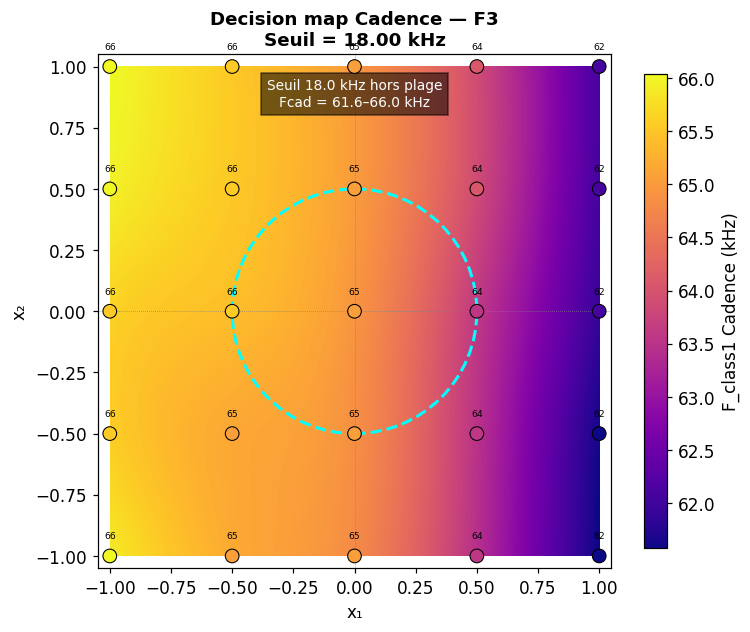

In [70]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F3 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F3_CAD = np.array([
    66.0e3, 65.0e3, 65.0e3, 63.5e3, 61.5e3,
    65.5e3, 65.0e3, 65.0e3, 63.5e3, 61.5e3,
    65.5e3, 65.5e3, 65.0e3, 63.5e3, 62.0e3,
    66.0e3, 65.5e3, 65.0e3, 64.0e3, 62.0e3,
    66.0e3, 65.5e3, 65.0e3, 64.0e3, 62.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F3_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F3\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

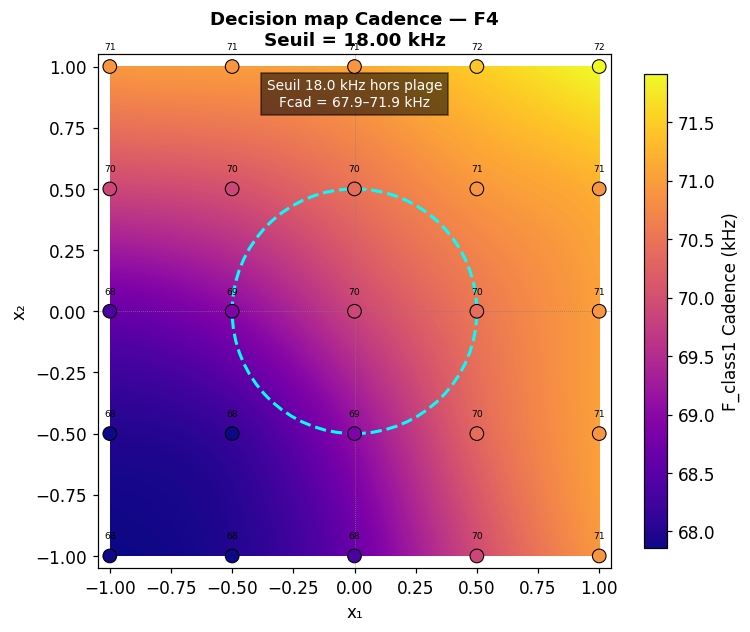

In [71]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F4 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F4_CAD = np.array([
    68.0e3, 68.0e3, 68.5e3, 70.0e3, 71.0e3,
    68.0e3, 68.0e3, 69.0e3, 70.5e3, 71.0e3,
    68.5e3, 69.0e3, 70.0e3, 70.5e3, 71.0e3,
    70.0e3, 70.0e3, 70.5e3, 71.0e3, 71.0e3,
    71.0e3, 71.0e3, 71.0e3, 71.5e3, 72.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F4_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F4\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F5 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F5_CAD = np.array([
    93.0e3, 93.0e3, 93.5e3, 95.0e3, 96.0e3,
    93.0e3, 93.5e3, 93.0e3, 94.5e3, 96.0e3,
    92.5e3, 93.5e3, 93.0e3, 94.5e3, 96.5e3,
    92.5e3, 93.0e3, 93.0e3, 94.5e3, 96.0e3,
    92.5e3, 93.0e3, 93.5e3, 94.5e3, 95.5e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F5_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F5\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F6 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F6_CAD = np.array([
    65.5e3, 66.0e3, 66.0e3, 68.0e3, 69.5e3,
    66.0e3, 66.0e3, 66.5e3, 68.5e3, 69.5e3,
    66.0e3, 66.0e3, 67.0e3, 68.5e3, 70.0e3,
    68.0e3, 68.0e3, 69.0e3, 70.0e3, 70.0e3,
    70.0e3, 70.0e3, 70.0e3, 70.0e3, 71.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F6_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F6\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

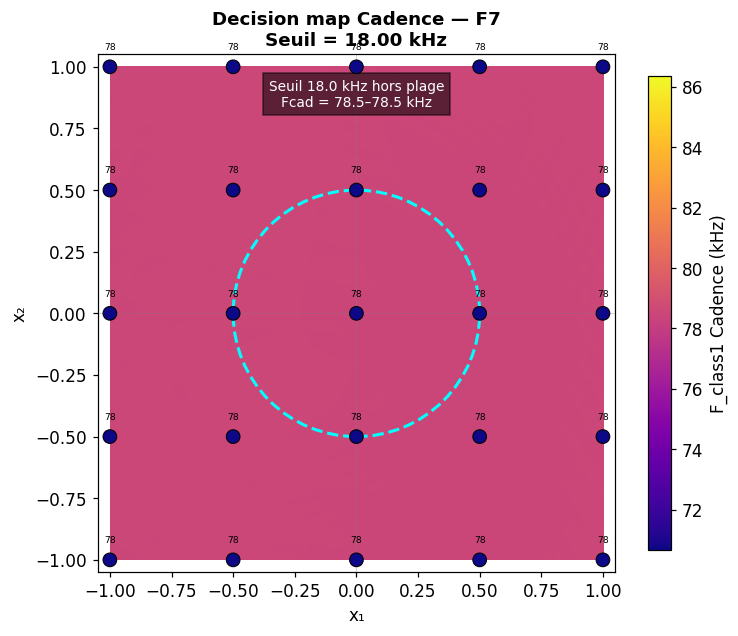

In [72]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F7 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F7_CAD = np.array([
    78.5e3, 78.5e3, 78.5e3, 78.5e3, 78.5e3,
    78.5e3, 78.5e3, 78.5e3, 78.5e3, 78.5e3,
    78.5e3, 78.5e3, 78.5e3, 78.5e3, 78.5e3,
    78.5e3, 78.5e3, 78.5e3, 78.5e3, 78.5e3,
    78.5e3, 78.5e3, 78.5e3, 78.5e3, 78.5e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F7_CAD[i]
# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F7\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F8 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24

F8_CAD = np.array([
    38.5e3, 38.0e3, 36.5e3, 34.5e3, 32.0e3,
    38.0e3, 37.0e3, 36.5e3, 34.5e3, 32.5e3,
    37.5e3, 36.5e3, 36.5e3, 34.5e3, 32.5e3,
    36.5e3, 36.5e3, 35.5e3, 34.0e3, 32.0e3,
    34.5e3, 34.0e3, 33.5e3, 33.5e3, 32.0e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F8_CAD[i]

# ─────────────────────────────────────────────────────────────
# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 18000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — F8\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE SEULEMENT — F_class1
# Fond = fréquence Cadence interpolée
# Blanc = seuil de décision
# ══════════════════════════════════════════════════════════════

from scipy.interpolate import RBFInterpolator
from matplotlib.patches import Circle
import numpy as np
import matplotlib.pyplot as plt


# ── SORTIE FINALE CADENCE : F1 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24
# eval err = 0.0

# ── SORTIE FINALE CADENCE : F1 ────────────────────────────────
# Ordre : C0_0, C0_1, ..., C0_24
# eval err = 0.0

F1_CAD = np.array([
    0.0,    1.5e3,  6.5e3,  7.5e3, 5.0e3,
    3.0e3,  6.5e3, 11.0e3,  8.5e3, 4.5e3,
    6.5e3,  9.5e3, 12.0e3,  9.0e3, 5.5e3,
    3.0e3,  3.0e3,  9.5e3,  8.0e3, 6.0e3,
    2.5e3,  1.0e3,  0.0,    3.0e3, 5.5e3,
])

for i, pt in enumerate(GRID_POINTS):
    pt["fout_cadence"] = F1_CAD[i]

# 2. Grille continue [-1, 1]²
# ─────────────────────────────────────────────────────────────

N_MAP_CAD = 120

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

TH_KHZ = 6000 / 1e3
DISK_R = 0.5
ext = [-1, 1, -1, 1]


# ─────────────────────────────────────────────────────────────
# 3. Interpolation Cadence de F_class1
# ─────────────────────────────────────────────────────────────

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)


# ─────────────────────────────────────────────────────────────
# 4. Fonction décoration
# ─────────────────────────────────────────────────────────────

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")


# ─────────────────────────────────────────────────────────────
# 5. Figure : Decision map Cadence seulement
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(im, ax=ax, label="F_class1 Cadence (kHz)", shrink=0.85)


# ── Frontière du seuil ───────────────────────────────────────

if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )


# ── Points mesurés Cadence ───────────────────────────────────

ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)


# ── Valeurs mesurées sur les points ──────────────────────────

for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=6,
        color="black",
        zorder=7
    )


decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — Fout\nSeuil = {TH_KHZ:.2f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────
# SORTIE FINALE CADENCE : F1 — grille 20×20
# Ordre :
#   ligne 0 : Vy = -100 mV, Vx de -100 à +100 mV
#   ligne 1 : Vy suivant, Vx de -100 à +100 mV
#   ...
# eval err / evaluating / simulation finished = 0.0
# ─────────────────────────────────────────────────────────────

F1_RAW = """
F1		1.5K	eval err	eval err	eval err	eval err	eval err	eval err	eval err	4K	eval err	7K	7K	7K	7K	5.5K	5K	3.5K	4K	3.5K	3K	eval err	1.5K	eval err	1K	eval err	2K	1.5K	2.5K	4K	5K	7K	7K	6.5K	6.5K	5K	3K	3.5K	2K	2K	3K	2K	2K	1.5K	2K	1.5K	2.5K	2.5K	4.5K	3.5K	5.5K	7K	8K	7.5K	6K	5.5K	3K	3.5K	3K	2K	3K	eval err	1.5K	2.5K	1K	2K	2K	2.5K	4K	5K	6.5K	8K	7.5K	6.5K	6.5K	5.5K	4.5K	3.5K	3K	2.5K	2.5K	eval err	3K	2K	2K	2K	4K	3.5K	6K	7.5K	8K	7.5K	7.5K	7.5K	6.5K	5.5K	3.5K	3K	3.5K	2K	2K	1.5K	2K	3.5K	1.5K	2.5K	2K	3.5K	5.5K	7.5K	7.5K	7.5K	7.5K	8K	6.5K	6.5K	4K	3.5K	3.5K	1.5K	2K	1.5K	3K	3K	4.5K	5.5K	5.5K	4.5K	6.5K	7.5K	8.5K	8K	8K	8K	7K	5.5K	4.5K	4K	4K	3.5K	3K	3K	3K	4K	5K	6.5K	6K	7K	8K	8K	8.5K	8K	7.5K	8.5K	6K	6.5K	4.5K	4.5K	3.5K	2.5K	3K	3.5K	3K	5.5K	5K	7K	7.5K	8K	8K	8K	8K	7.5K	7.5K	8K	6K	5.5K	5K	4.5K	3.5K	3K	2.5K	6K	6.5K	6K	6.5K	7.5K	8K	7.5K	7.5K	8K	8K	8K	8K	7.5K	6.5K	8K	5.5K	5.5K	4K	3K	3K	4.5K	5K	5.5K	6.5K	6.5K	7.5K	8K	8K	8K	8.5K	8K	8K	7.5K	8K	7K	6.5K	4K	3K	3K	3K	5K	4K	4.5K	7K	7.5K	8K	8K	8.5K	8K	8K	8K	8.5K	8K	6K	6.5K	6K	4K	4K	2K	3.5K	4K	3.5K	5.5K	4K	6K	7K	7.5K	8K	8.5K	9K	8K	7.5K	8K	7K	6.5K	4.5K	4.5K	3.5K	4K	2K	2.5K	2K	4.5K	3K	3K	4K	4.5K	7K	7K	8K	8K	8K	7.5K	7K	6.5K	6K	4.5K	3K	3K	3.5K	eval err	2.5K	1.5K	eval err	2K	2K	3.5K	4.5K	8K	7.5K	8.5K	7K	7K	6.5K	5K	5.5K	3.5K	4K	3.5K	3K	eval err	eval err	eval err	eval err	1K	2.5K	2K	2.5K	2.5K	4K	4K	6.5K	7K	6.5K	5K	5K	3.5K	4.5K	3K	2K	eval err	eval err	eval err	eval err	eval err	eval err	eval err	1K	eval err	2.5K	2.5K	3.5K	4.5K	3.5K	4K	4.5K	2K	4K	2.5K	3K	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	2.5K	2K	3.5K	4.5K	4.5K	3K	3K	2K	3K	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	1.5K	1.5K	2.5K	2.5K	2.5K	3K	2.5K	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	eval err	2K	2.5K	1.5K	2.5K	3K	3K
"""

# ─────────────────────────────────────────────────────────────
# Parser robuste
# ─────────────────────────────────────────────────────────────

def parse_freq_row(raw):
    """
    Convertit une ligne Cadence en array numpy.
    - 1K      -> 1000
    - 1.5K    -> 1500
    - eval err / evaluating / simulation finished -> 0
    - ignore F1
    """
    tokens = re.findall(
        r"eval err|simulation finished|evaluating|[-+]?\d+(?:\.\d+)?K?",
        raw
    )

    values = []

    for t in tokens:
        if t in ["eval err", "simulation finished", "evaluating"]:
            values.append(0.0)

        elif t.endswith("K"):
            values.append(float(t[:-1]) * 1e3)

        else:
            # Ignore les nombres seuls comme le "1" dans "F1"
            pass

    return np.array(values, dtype=float)


F1_CAD = parse_freq_row(F1_RAW)

print("Nombre de points lus =", len(F1_CAD))

# ─────────────────────────────────────────────────────────────
# Sécurité : forcer 400 points
# ─────────────────────────────────────────────────────────────

N = 20
N_EXPECTED = N * N

if len(F1_CAD) < N_EXPECTED:
    print(f"⚠️ Il manque {N_EXPECTED - len(F1_CAD)} valeur(s). Remplissage par 0.0 à la fin.")
    F1_CAD = np.pad(F1_CAD, (0, N_EXPECTED - len(F1_CAD)), constant_values=0.0)

elif len(F1_CAD) > N_EXPECTED:
    print(f"⚠️ Il y a {len(F1_CAD) - N_EXPECTED} valeur(s) en trop. On coupe à 400.")
    F1_CAD = F1_CAD[:N_EXPECTED]

print("Nombre final de points =", len(F1_CAD))

# Carte 20×20
F1_CAD_MAP = F1_CAD.reshape(N, N)

# ─────────────────────────────────────────────────────────────
# Créer la grille 20×20
# ─────────────────────────────────────────────────────────────

VX_20 = np.linspace(-100, 100, N)
VY_20 = np.linspace(-100, 100, N)

GRID_POINTS_20 = []

for iy, vy in enumerate(VY_20):
    for ix, vx in enumerate(VX_20):
        idx = iy * N + ix
        GRID_POINTS_20.append({
            "idx": idx,
            "vx": vx,
            "vy": vy,
            "fout_cadence": F1_CAD[idx],
        })

# ─────────────────────────────────────────────────────────────
# Affichage carte Cadence
# ─────────────────────────────────────────────────────────────

plt.figure(figsize=(7, 6))
plt.imshow(
    F1_CAD_MAP / 1e3,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto"
)
plt.colorbar(label="F1 Cadence (kHz)")
plt.xlabel("Vin1 / Vx (mV)")
plt.ylabel("Vin2 / Vy (mV)")
plt.title("F1 Cadence — grille 20×20")
plt.show()

# ─────────────────────────────────────────────────────────────
# FIGURE : FREQ DE DÉCISION + DECISION MAP
# ─────────────────────────────────────────────────────────────

THRESH_KHZ = 7.0

F_DEC_KHZ = F1_CAD_MAP / 1e3
DECISION_CAD = (F_DEC_KHZ > THRESH_KHZ).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Carte fréquence
im0 = axes[0].imshow(
    F_DEC_KHZ,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto",
    interpolation="bilinear"
)

axes[0].contour(
    VX_20,
    VY_20,
    F_DEC_KHZ,
    levels=[THRESH_KHZ],
    linewidths=2
)

axes[0].set_title("Fréquence de décision Cadence")
axes[0].set_xlabel("Vin1 / Vx (mV)")
axes[0].set_ylabel("Vin2 / Vy (mV)")
axes[0].grid(alpha=0.2)
fig.colorbar(im0, ax=axes[0], label="F1 Cadence (kHz)")

# Carte décision binaire
im1 = axes[1].imshow(
    DECISION_CAD,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto",
    interpolation="nearest"
)

axes[1].contour(
    VX_20,
    VY_20,
    F_DEC_KHZ,
    levels=[THRESH_KHZ],
    linewidths=2
)

axes[1].set_title(f"Decision map Cadence — seuil = {THRESH_KHZ:.1f} kHz")
axes[1].set_xlabel("Vin1 / Vx (mV)")
axes[1].set_ylabel("Vin2 / Vy (mV)")
axes[1].grid(alpha=0.2)
fig.colorbar(im1, ax=axes[1], label="Décision")

plt.tight_layout()
plt.show()

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.interpolate import RBFInterpolator

# ══════════════════════════════════════════════════════════════
# 1. LIGNE CADENCE À COLLER ICI
# ══════════════════════════════════════════════════════════════

F1_RAW = """																							
																										
Fout		29K	29K	29K	30K	30K	29K	29K	30K	30K	30K	30K	30K	30K	30K	30K	30K	30K	30K	30K	30K	29K	29K	29K	29K	29K




"""

# ══════════════════════════════════════════════════════════════
# 2. PARSER ROBUSTE
# ══════════════════════════════════════════════════════════════

def parse_freq_row(raw):
    """
    Convertit une ligne Cadence en array numpy.
    - 34K     -> 34000
    - 1.5K    -> 1500
    - eval err / evaluating / simulation finished -> 0
    - ignore F1
    """
    tokens = re.findall(
        r"eval err|simulation finished|evaluating|[-+]?\d+(?:\.\d+)?K?",
        raw
    )

    values = []

    for t in tokens:
        if t in ["eval err", "simulation finished", "evaluating"]:
            values.append(0.0)

        elif t.endswith("K"):
            values.append(float(t[:-1]) * 1e3)

        else:
            # Ignore les nombres seuls comme le "1" dans "F1"
            pass

    return np.array(values, dtype=float)


F1_CAD = parse_freq_row(F1_RAW)

print("Nombre de points lus =", len(F1_CAD))

# ══════════════════════════════════════════════════════════════
# 3. DÉTECTION AUTOMATIQUE DE LA GRILLE
# ══════════════════════════════════════════════════════════════

N_POINTS = len(F1_CAD)
N = int(np.sqrt(N_POINTS))

if N * N != N_POINTS:
    raise ValueError(
        f"Le nombre de points = {N_POINTS}, ce n'est pas une grille carrée. "
        f"Exemple attendu : 25 pour 5×5, 400 pour 20×20."
    )

print(f"Grille détectée : {N} × {N}")

F1_CAD_MAP = F1_CAD.reshape(N, N)

# ══════════════════════════════════════════════════════════════
# 4. CRÉATION AUTOMATIQUE DE GRID_POINTS
#    x1, x2 normalisés entre -1 et +1
# ══════════════════════════════════════════════════════════════

x1_vals = np.linspace(-1, 1, N)
x2_vals = np.linspace(-1, 1, N)

GRID_POINTS = []

for iy, x2 in enumerate(x2_vals):
    for ix, x1 in enumerate(x1_vals):
        idx = iy * N + ix
        GRID_POINTS.append({
            "idx": idx,
            "x1": x1,
            "x2": x2,
            "fout_cadence": F1_CAD[idx],
        })

# ══════════════════════════════════════════════════════════════
# 5. PARAMÈTRES DE LA DECISION MAP
# ══════════════════════════════════════════════════════════════

N_MAP_CAD = 200

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

# Seuil de décision en kHz
# Pour ton ancienne carte : 6 kHz
# Mais avec tes valeurs 29–36 kHz, un seuil utile serait plutôt autour de 33 ou 34 kHz.
TH_KHZ = 2.0

DISK_R = 0.5
ext = [-1, 1, -1, 1]

# ══════════════════════════════════════════════════════════════
# 6. INTERPOLATION CADENCE
# ══════════════════════════════════════════════════════════════

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)

# ══════════════════════════════════════════════════════════════
# 7. DÉCORATION
# ══════════════════════════════════════════════════════════════

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.grid(alpha=0.15)

# ══════════════════════════════════════════════════════════════
# 8. FIGURE : DECISION MAP CADENCE SEULEMENT
# ══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(
    im,
    ax=ax,
    label="F_class1 Cadence (kHz)",
    shrink=0.85
)

# Frontière du seuil
if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )

# Points mesurés Cadence
ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)

# Valeurs mesurées sur les points
for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=7,
        color="black",
        zorder=7
    )

decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — Fout\nSeuil = {TH_KHZ:.1f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Nombre de points lus = 25
Grille détectée : 5 × 5


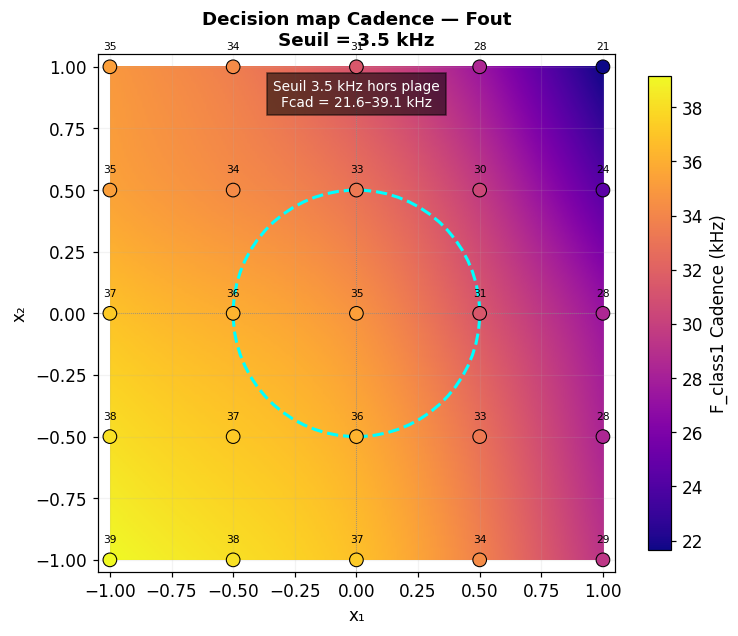

In [121]:
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.interpolate import RBFInterpolator

# ══════════════════════════════════════════════════════════════
# 1. LIGNE CADENCE À COLLER ICI
# ══════════════════════════════════════════════════════════════

F1_RAW = """																																																	

																										
																										
Fout		39K	38K	37K	34K	29K	38K	37K	36K	33K	28K	37K	36K	35K	31K	28K	35K	34K	33K	30K	24K	35K	34K	31K	28K	21K


"""

# ══════════════════════════════════════════════════════════════
# 2. PARSER ROBUSTE
# ══════════════════════════════════════════════════════════════

def parse_freq_row(raw):
    """
    Convertit une ligne Cadence en array numpy.
    - 34K     -> 34000
    - 1.5K    -> 1500
    - eval err / evaluating / simulation finished -> 0
    - ignore F1
    """
    tokens = re.findall(
        r"eval err|simulation finished|evaluating|[-+]?\d+(?:\.\d+)?K?",
        raw
    )

    values = []

    for t in tokens:
        if t in ["eval err", "simulation finished", "evaluating"]:
            values.append(0.0)

        elif t.endswith("K"):
            values.append(float(t[:-1]) * 1e3)

        else:
            # Ignore les nombres seuls comme le "1" dans "F1"
            pass

    return np.array(values, dtype=float)


F1_CAD = parse_freq_row(F1_RAW)

print("Nombre de points lus =", len(F1_CAD))

# ══════════════════════════════════════════════════════════════
# 3. DÉTECTION AUTOMATIQUE DE LA GRILLE
# ══════════════════════════════════════════════════════════════

N_POINTS = len(F1_CAD)
N = int(np.sqrt(N_POINTS))

if N * N != N_POINTS:
    raise ValueError(
        f"Le nombre de points = {N_POINTS}, ce n'est pas une grille carrée. "
        f"Exemple attendu : 25 pour 5×5, 400 pour 20×20."
    )

print(f"Grille détectée : {N} × {N}")

F1_CAD_MAP = F1_CAD.reshape(N, N)

# ══════════════════════════════════════════════════════════════
# 4. CRÉATION AUTOMATIQUE DE GRID_POINTS
#    x1, x2 normalisés entre -1 et +1
# ══════════════════════════════════════════════════════════════

x1_vals = np.linspace(-1, 1, N)
x2_vals = np.linspace(-1, 1, N)

GRID_POINTS = []

for iy, x2 in enumerate(x2_vals):
    for ix, x1 in enumerate(x1_vals):
        idx = iy * N + ix
        GRID_POINTS.append({
            "idx": idx,
            "x1": x1,
            "x2": x2,
            "fout_cadence": F1_CAD[idx],
        })

# ══════════════════════════════════════════════════════════════
# 5. PARAMÈTRES DE LA DECISION MAP
# ══════════════════════════════════════════════════════════════

N_MAP_CAD = 200

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)

X1_cad, X2_cad = np.meshgrid(x1_cad, x2_cad)

# Seuil de décision en kHz
# Pour ton ancienne carte : 6 kHz
# Mais avec tes valeurs 29–36 kHz, un seuil utile serait plutôt autour de 33 ou 34 kHz.
TH_KHZ = 3.5
DISK_R = 0.5
ext = [-1, 1, -1, 1]

# ══════════════════════════════════════════════════════════════
# 6. INTERPOLATION CADENCE
# ══════════════════════════════════════════════════════════════

pts_xy = np.array([[pt["x1"], pt["x2"]] for pt in GRID_POINTS])
fout_cad_pts = np.array([pt["fout_cadence"] for pt in GRID_POINTS])

query_cad = np.column_stack([
    X1_cad.ravel(),
    X2_cad.ravel()
])

rbf_fclass1 = RBFInterpolator(
    pts_xy,
    fout_cad_pts,
    kernel="thin_plate_spline",
    smoothing=0.3
)

grid_fout_cad = rbf_fclass1(query_cad).reshape(N_MAP_CAD, N_MAP_CAD) / 1e3
grid_fout_cad = np.maximum(grid_fout_cad, 0.0)

# ══════════════════════════════════════════════════════════════
# 7. DÉCORATION
# ══════════════════════════════════════════════════════════════

def decorate_map(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            DISK_R,
            color="cyan",
            fill=False,
            lw=2,
            ls="--",
            zorder=5
        )
    )

    ax.axhline(0, color="gray", lw=0.5, ls=":")
    ax.axvline(0, color="gray", lw=0.5, ls=":")

    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_aspect("equal")

    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.grid(alpha=0.15)

# ══════════════════════════════════════════════════════════════
# 8. FIGURE : DECISION MAP CADENCE SEULEMENT
# ══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    grid_fout_cad,
    origin="lower",
    extent=ext,
    aspect="equal",
    cmap="plasma",
    interpolation="bilinear"
)

plt.colorbar(
    im,
    ax=ax,
    label="F_class1 Cadence (kHz)",
    shrink=0.85
)

# Frontière du seuil
if grid_fout_cad.min() <= TH_KHZ <= grid_fout_cad.max():
    ax.contour(
        x1_cad,
        x2_cad,
        grid_fout_cad,
        levels=[TH_KHZ],
        colors="white",
        linewidths=2.5
    )
else:
    ax.text(
        0,
        0.95,
        f"Seuil {TH_KHZ:.1f} kHz hors plage\n"
        f"Fcad = {grid_fout_cad.min():.1f}–{grid_fout_cad.max():.1f} kHz",
        ha="center",
        va="top",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.55)
    )

# Points mesurés Cadence
ax.scatter(
    pts_xy[:, 0],
    pts_xy[:, 1],
    c=fout_cad_pts / 1e3,
    cmap="plasma",
    s=80,
    edgecolors="black",
    linewidths=0.7,
    zorder=6
)

# Valeurs mesurées sur les points
for pt in GRID_POINTS:
    ax.text(
        pt["x1"],
        pt["x2"] + 0.07,
        f'{pt["fout_cadence"] / 1e3:.0f}',
        ha="center",
        fontsize=7,
        color="black",
        zorder=7
    )

decorate_map(ax)

ax.set_title(
    f"Decision map Cadence — Fout\nSeuil = {TH_KHZ:.1f} kHz",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Nombre de points lus = 400
Nombre final de points = 400


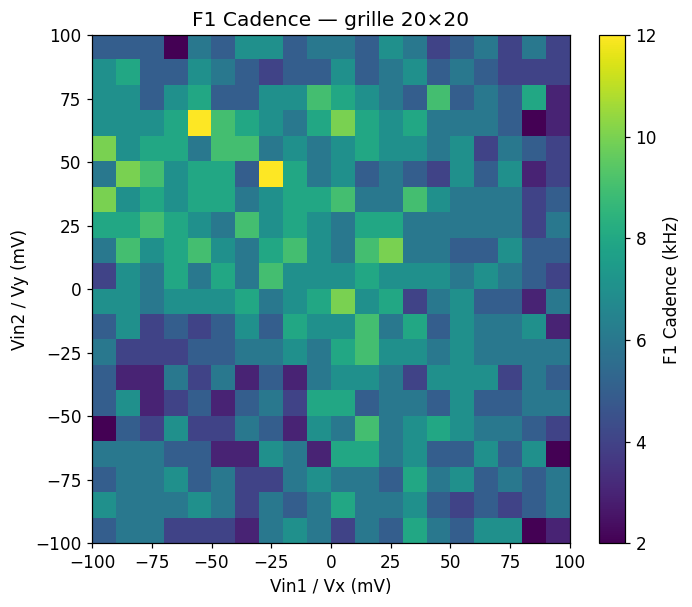

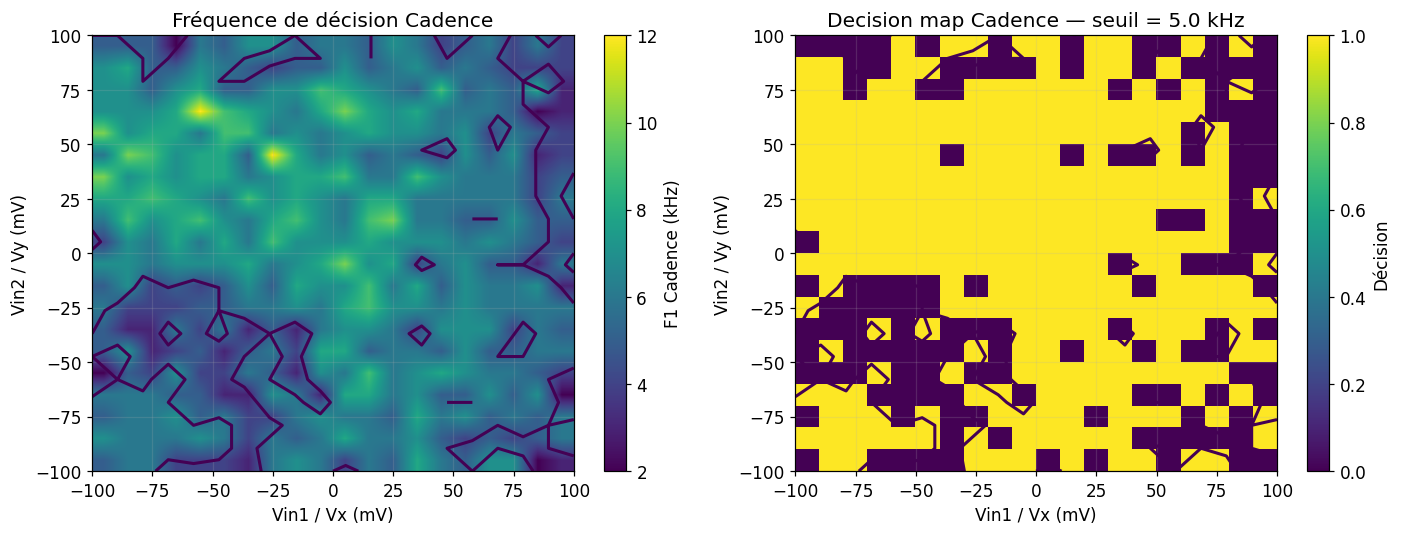

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────
# SORTIE FINALE CADENCE : F1 — grille 20×20
# Ordre :
#   ligne 0 : Vy = -100 mV, Vx de -100 à +100 mV
#   ligne 1 : Vy suivant, Vx de -100 à +100 mV
#   ...
# eval err / evaluating / simulation finished = 0.0
# ─────────────────────────────────────────────────────────────

F1_RAW = """
																																																																																																																																																																																																																																																																																																																																																																																																																	
																																																																																																																																																																																																																																																																																																																																																																																																																	
Fout		5K	6K	6K	4K	4K	4K	3K	6K	7K	6K	4K	6K	5K	8K	6K	5K	7K	7K	2K	3K	7K	6K	6K	6K	7K	6K	4K	6K	5K	6K	8K	6K	6K	7K	5K	4K	5K	4K	5K	6K	5K	6K	6K	7K	5K	6K	4K	4K	6K	7K	6K	6K	5K	8K	6K	7K	5K	6K	5K	6K	6K	6K	6K	5K	5K	3K	3K	7K	6K	3K	8K	8K	6K	7K	5K	5K	7K	5K	7K	2K	2K	5K	4K	7K	4K	4K	6K	5K	3K	7K	6K	9K	6K	7K	8K	7K	6K	6K	5K	4K	5K	7K	3K	4K	5K	3K	5K	6K	4K	8K	8K	5K	6K	6K	5K	7K	5K	5K	6K	6K	5K	3K	3K	6K	4K	6K	3K	5K	3K	6K	7K	7K	6K	4K	7K	7K	7K	4K	6K	5K	6K	4K	4K	4K	5K	5K	6K	6K	7K	6K	8K	9K	7K	7K	6K	7K	6K	6K	6K	6K	5K	7K	4K	5K	4K	5K	7K	5K	8K	7K	7K	9K	6K	8K	5K	7K	6K	6K	7K	3K	7K	7K	6K	7K	7K	7K	8K	6K	7K	8K	10K	7K	8K	4K	6K	7K	5K	5K	3K	6K	4K	7K	6K	8K	6K	8K	6K	9K	7K	7K	7K	8K	7K	7K	7K	6K	7K	6K	5K	4K	6K	9K	7K	8K	9K	7K	6K	8K	9K	7K	6K	9K	10K	6K	6K	5K	5K	7K	5K	5K	8K	8K	9K	8K	7K	6K	9K	7K	8K	7K	6K	8K	8K	6K	6K	6K	6K	6K	4K	6K	10K	7K	8K	7K	8K	8K	6K	7K	8K	8K	9K	6K	6K	9K	7K	6K	6K	6K	4K	5K	6K	10K	9K	7K	8K	8K	5K	12K	8K	6K	7K	5K	6K	5K	4K	7K	5K	7K	3K	4K	10K	7K	8K	8K	6K	9K	9K	6K	7K	6K	7K	8K	7K	7K	6K	7K	4K	6K	5K	4K	7K	7K	7K	8K	12K	9K	8K	7K	6K	8K	10K	8K	7K	8K	6K	6K	6K	5K	2K	3K	7K	7K	5K	7K	8K	5K	5K	7K	7K	9K	8K	7K	6K	5K	9K	5K	6K	5K	8K	3K	7K	8K	5K	5K	7K	6K	5K	4K	5K	5K	7K	5K	6K	7K	5K	6K	5K	4K	4K	4K	5K	5K	5K	2K	6K	5K	7K	7K	5K	6K	6K	5K	7K	6K	4K	5K	6K	4K	6K	4K
"""

# ─────────────────────────────────────────────────────────────
# Parser robuste
# ─────────────────────────────────────────────────────────────

def parse_freq_row(raw):
    """
    Convertit une ligne Cadence en array numpy.
    - 1K      -> 1000
    - 1.5K    -> 1500
    - eval err / evaluating / simulation finished -> 0
    - ignore F1
    """
    tokens = re.findall(
        r"eval err|simulation finished|evaluating|[-+]?\d+(?:\.\d+)?K?",
        raw
    )

    values = []

    for t in tokens:
        if t in ["eval err", "simulation finished", "evaluating"]:
            values.append(0.0)

        elif t.endswith("K"):
            values.append(float(t[:-1]) * 1e3)

        else:
            # Ignore les nombres seuls comme le "1" dans "F1"
            pass

    return np.array(values, dtype=float)


F1_CAD = parse_freq_row(F1_RAW)

print("Nombre de points lus =", len(F1_CAD))

# ─────────────────────────────────────────────────────────────
# Sécurité : forcer 400 points
# ─────────────────────────────────────────────────────────────

N = 20
N_EXPECTED = N * N

if len(F1_CAD) < N_EXPECTED:
    print(f"⚠️ Il manque {N_EXPECTED - len(F1_CAD)} valeur(s). Remplissage par 0.0 à la fin.")
    F1_CAD = np.pad(F1_CAD, (0, N_EXPECTED - len(F1_CAD)), constant_values=0.0)

elif len(F1_CAD) > N_EXPECTED:
    print(f"⚠️ Il y a {len(F1_CAD) - N_EXPECTED} valeur(s) en trop. On coupe à 400.")
    F1_CAD = F1_CAD[:N_EXPECTED]

print("Nombre final de points =", len(F1_CAD))

# Carte 20×20
F1_CAD_MAP = F1_CAD.reshape(N, N)

# ─────────────────────────────────────────────────────────────
# Créer la grille 20×20
# ─────────────────────────────────────────────────────────────

VX_20 = np.linspace(-100, 100, N)
VY_20 = np.linspace(-100, 100, N)

GRID_POINTS_20 = []

for iy, vy in enumerate(VY_20):
    for ix, vx in enumerate(VX_20):
        idx = iy * N + ix
        GRID_POINTS_20.append({
            "idx": idx,
            "vx": vx,
            "vy": vy,
            "fout_cadence": F1_CAD[idx],
        })

# ─────────────────────────────────────────────────────────────
# Affichage carte Cadence
# ─────────────────────────────────────────────────────────────

plt.figure(figsize=(7, 6))
plt.imshow(
    F1_CAD_MAP / 1e3,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto"
)
plt.colorbar(label="F1 Cadence (kHz)")
plt.xlabel("Vin1 / Vx (mV)")
plt.ylabel("Vin2 / Vy (mV)")
plt.title("F1 Cadence — grille 20×20")
plt.show()

# ─────────────────────────────────────────────────────────────
# FIGURE : FREQ DE DÉCISION + DECISION MAP
# ─────────────────────────────────────────────────────────────

THRESH_KHZ = 5.0

F_DEC_KHZ = F1_CAD_MAP / 1e3
DECISION_CAD = (F_DEC_KHZ > THRESH_KHZ).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Carte fréquence
im0 = axes[0].imshow(
    F_DEC_KHZ,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto",
    interpolation="bilinear"
)

axes[0].contour(
    VX_20,
    VY_20,
    F_DEC_KHZ,
    levels=[THRESH_KHZ],
    linewidths=2
)

axes[0].set_title("Fréquence de décision Cadence")
axes[0].set_xlabel("Vin1 / Vx (mV)")
axes[0].set_ylabel("Vin2 / Vy (mV)")
axes[0].grid(alpha=0.2)
fig.colorbar(im0, ax=axes[0], label="F1 Cadence (kHz)")

# Carte décision binaire
im1 = axes[1].imshow(
    DECISION_CAD,
    origin="lower",
    extent=[-100, 100, -100, 100],
    aspect="auto",
    interpolation="nearest"
)

axes[1].contour(
    VX_20,
    VY_20,
    F_DEC_KHZ,
    levels=[THRESH_KHZ],
    linewidths=2
)

axes[1].set_title(f"Decision map Cadence — seuil = {THRESH_KHZ:.1f} kHz")
axes[1].set_xlabel("Vin1 / Vx (mV)")
axes[1].set_ylabel("Vin2 / Vy (mV)")
axes[1].grid(alpha=0.2)
fig.colorbar(im1, ax=axes[1], label="Décision")

plt.tight_layout()
plt.show()